In [1]:
from pathlib import Path

# Extracted dataset folder
dataset_path = Path("hackathon-100")

print("Current working directory:", Path.cwd())
print("Dataset exists:", dataset_path.exists())

# Locate company 003
company_path = dataset_path / "company-003"

print("Company 003 exists:", company_path.exists())

if company_path.exists():
    print("\nContents of Company 003:")
    for item in company_path.iterdir():
        print(item.name)

Current working directory: /Users/anushreenema
Dataset exists: True
Company 003 exists: True

Contents of Company 003:
rwm-v4
.ipynb_checkpoints


In [2]:
from pathlib import Path

company_path = Path("hackathon-100/company-003")

# Recursively list all files inside company 003
all_files = sorted(
    f for f in company_path.rglob("*")
    if f.is_file()
)

print("Total files:", len(all_files))

print("\nAll files in Company 003:\n")

for f in all_files:
    print(f.relative_to(company_path))

Total files: 23

All files in Company 003:

rwm-v4/world-05d64e2d010225ca/SCHEMA.md
rwm-v4/world-05d64e2d010225ca/accounts.yaml
rwm-v4/world-05d64e2d010225ca/bank_transactions.yaml
rwm-v4/world-05d64e2d010225ca/bill_payments.yaml
rwm-v4/world-05d64e2d010225ca/bills.yaml
rwm-v4/world-05d64e2d010225ca/company.yaml
rwm-v4/world-05d64e2d010225ca/customer_payments.yaml
rwm-v4/world-05d64e2d010225ca/customers.yaml
rwm-v4/world-05d64e2d010225ca/employees.yaml
rwm-v4/world-05d64e2d010225ca/estimates.yaml
rwm-v4/world-05d64e2d010225ca/invoices.yaml
rwm-v4/world-05d64e2d010225ca/items.yaml
rwm-v4/world-05d64e2d010225ca/journal_entries.yaml
rwm-v4/world-05d64e2d010225ca/manifest.yaml
rwm-v4/world-05d64e2d010225ca/payroll_runs.yaml
rwm-v4/world-05d64e2d010225ca/projects.yaml
rwm-v4/world-05d64e2d010225ca/reports/ap_aging.yaml
rwm-v4/world-05d64e2d010225ca/reports/ar_aging.yaml
rwm-v4/world-05d64e2d010225ca/reports/balance_sheet.yaml
rwm-v4/world-05d64e2d010225ca/reports/profit_and_loss.yaml
rwm-v4

In [3]:
import yaml
import pandas as pd

# Locate the actual data directory
data_path = company_path / "rwm-v4" / "world-05d64e2d010225ca"

def load_yaml(filename):
    with open(data_path / filename, "r", encoding="utf-8") as f:
        return yaml.safe_load(f)

# Load datasets
customers = load_yaml("customers.yaml")
invoices = load_yaml("invoices.yaml")
payments = load_yaml("customer_payments.yaml")

# Inspect data types and structure
for name, data in [
    ("CUSTOMERS", customers),
    ("INVOICES", invoices),
    ("PAYMENTS", payments)
]:
    print(f"\n===== {name} =====")
    print("Type:", type(data).__name__)

    if isinstance(data, list):
        print("Number of records:", len(data))
        print("First record:")
        print(data[0] if data else "Empty")

    elif isinstance(data, dict):
        print("Top-level keys:", list(data.keys()))
        for key, value in data.items():
            if isinstance(value, list):
                print(f"  {key}: {len(value)} records")
                print("  First record:", value[0] if value else "Empty")
            else:
                print(f"  {key}: {type(value).__name__}")


===== CUSTOMERS =====
Type: list
Number of records: 136
First record:
{'id': 'cust-customer-1', 'display_name': 'Lantern Toyworks & Co.', 'company_name': 'Lantern Toyworks & Co.', 'contact_given_name': 'Bruno', 'contact_family_name': 'Ulloa', 'email': 'bruno.ulloa@lanterntoyworksco.example', 'phone': '(555) 178-4459', 'address': {'line1': '7218 Foundry Lane', 'city': 'Fresno', 'state': 'CA', 'postal_code': '93773', 'country': 'United States', 'line2': None}, 'payment_terms': 'Net 7', 'payment_terms_days': 7, 'credit_limit_amount': '1871.21', 'joined_sim_day': 0, 'joined_date': '2025-10-06', 'ended_sim_day': 308, 'ended_date': '2026-08-10', 'ended_sim_event_id': 'event-45853', 'notes': '', 'sim_actor_id': 'customer-1', 'sim_event_ids': ['event-45853']}

===== INVOICES =====
Type: list
Number of records: 5132
First record:
{'id': 'inv-00063', 'doc_number': 'INV-1001', 'customer_id': 'cust-customer-5', 'customer_name': 'Meridian Elmsworth Confections', 'txn_sim_day': 7, 'txn_date': '2025

In [4]:
import pandas as pd

# Convert customer records into DataFrame
customers_df = pd.DataFrame(customers)

# Convert date columns
customers_df["joined_date"] = pd.to_datetime(
    customers_df["joined_date"]
)

customers_df["ended_date"] = pd.to_datetime(
    customers_df["ended_date"]
)

# Identify ended relationships
customers_df["has_ended"] = customers_df["ended_date"].notna()

print("Total customers:", len(customers_df))

print(
    "Active / not marked ended:",
    (~customers_df["has_ended"]).sum()
)

print(
    "Ended relationships:",
    customers_df["has_ended"].sum()
)

print("\nTermination percentage:")
print(
    round(customers_df["has_ended"].mean() * 100, 2),
    "%"
)

print("\nCustomer join date range:")
print(
    customers_df["joined_date"].min(),
    "to",
    customers_df["joined_date"].max()
)

print("\nCustomer termination date range:")
print(
    customers_df["ended_date"].min(),
    "to",
    customers_df["ended_date"].max()
)

# Relationship duration for ended customers
ended_customers = customers_df[
    customers_df["has_ended"]
].copy()

ended_customers["relationship_days"] = (
    ended_customers["ended_date"]
    - ended_customers["joined_date"]
).dt.days

print("\nRelationship duration (ended customers):")

print(
    ended_customers["relationship_days"].describe()
)

Total customers: 136
Active / not marked ended: 95
Ended relationships: 41

Termination percentage:
30.15 %

Customer join date range:
2025-10-06 00:00:00 to 2026-09-28 00:00:00

Customer termination date range:
2025-11-03 00:00:00 to 2026-10-05 00:00:00

Relationship duration (ended customers):
count     41.000000
mean     165.682927
std      118.332041
min       28.000000
25%       84.000000
50%      126.000000
75%      280.000000
max      364.000000
Name: relationship_days, dtype: float64


In [5]:
# Convert invoices into a DataFrame
invoices_df = pd.DataFrame(invoices)

invoices_df["txn_date"] = pd.to_datetime(
    invoices_df["txn_date"]
)

invoices_df["total_amount"] = pd.to_numeric(
    invoices_df["total_amount"]
)

# Count invoices per customer
invoice_stats = (
    invoices_df
    .groupby("customer_id")
    .agg(
        invoice_count=("id", "count"),
        first_invoice=("txn_date", "min"),
        last_invoice=("txn_date", "max"),
        total_revenue=("total_amount", "sum")
    )
    .reset_index()
)

# Join customer information
customer_analysis = customers_df[
    ["id", "display_name", "joined_date", "ended_date", "has_ended"]
].merge(
    invoice_stats,
    left_on="id",
    right_on="customer_id",
    how="left"
)

customer_analysis["invoice_count"] = (
    customer_analysis["invoice_count"].fillna(0).astype(int)
)

print("Invoice counts by customer:")
print(customer_analysis["invoice_count"].describe())

print("\nInvoice history by relationship status:")
print(
    customer_analysis.groupby("has_ended")["invoice_count"]
    .describe()
)

print("\nEnded customers with at least 5 invoices:")
print(
    (
        (customer_analysis["has_ended"])
        & (customer_analysis["invoice_count"] >= 5)
    ).sum()
)

print("\nEnded customers with at least 10 invoices:")
print(
    (
        (customer_analysis["has_ended"])
        & (customer_analysis["invoice_count"] >= 10)
    ).sum()
)

print("\nEnded customers with at least 20 invoices:")
print(
    (
        (customer_analysis["has_ended"])
        & (customer_analysis["invoice_count"] >= 20)
    ).sum()
)

Invoice counts by customer:
count    136.000000
mean      37.735294
std       22.439791
min        2.000000
25%       16.750000
50%       39.000000
75%       54.000000
max       84.000000
Name: invoice_count, dtype: float64

Invoice history by relationship status:
           count       mean        std  min   25%   50%   75%   max
has_ended                                                          
False       95.0  43.410526  20.497792  2.0  35.0  43.0  55.0  84.0
True        41.0  24.585366  21.409082  2.0   7.0  16.0  38.0  84.0

Ended customers with at least 5 invoices:
35

Ended customers with at least 10 invoices:
29

Ended customers with at least 20 invoices:
18


Eligible ended customers: 24

Average invoices per 30-day window:
window
90-61 days    4.833333
60-31 days    5.083333
30-1 days     4.583333
Name: invoice_count, dtype: float64


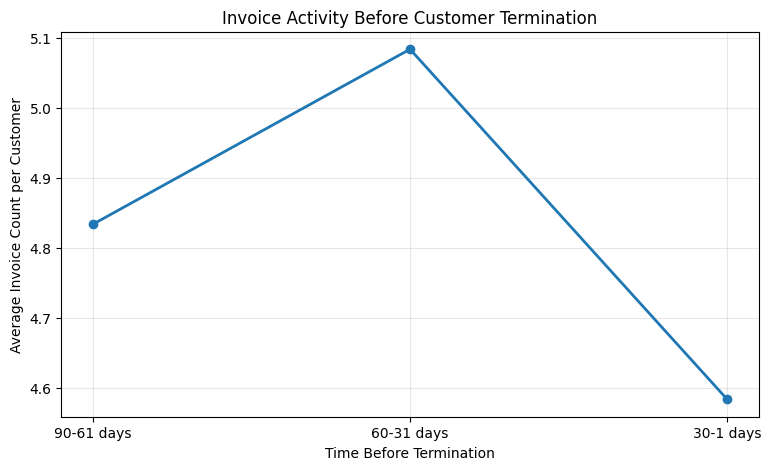

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Select ended customers with at least 90 days of history
eligible = customers_df[
    customers_df["ended_date"].notna()
    & (
        (customers_df["ended_date"] - customers_df["joined_date"])
        .dt.days >= 90
    )
].copy()

records = []

for _, customer in eligible.iterrows():
    cid = customer["id"]
    end_date = customer["ended_date"]

    customer_invoices = invoices_df[
        invoices_df["customer_id"] == cid
    ]

    for label, start_days, end_days in [
        ("90-61 days", 90, 60),
        ("60-31 days", 60, 30),
        ("30-1 days", 30, 0)
    ]:
        start_date = end_date - pd.Timedelta(days=start_days)
        stop_date = end_date - pd.Timedelta(days=end_days)

        count = (
            (customer_invoices["txn_date"] >= start_date)
            & (customer_invoices["txn_date"] < stop_date)
        ).sum()

        records.append({
            "customer_id": cid,
            "window": label,
            "invoice_count": count
        })

activity_df = pd.DataFrame(records)

window_order = [
    "90-61 days",
    "60-31 days",
    "30-1 days"
]

average_activity = (
    activity_df.groupby("window")["invoice_count"]
    .mean()
    .reindex(window_order)
)

print("Eligible ended customers:", len(eligible))
print("\nAverage invoices per 30-day window:")
print(average_activity)

plt.figure(figsize=(9, 5))
plt.plot(
    window_order,
    average_activity.values,
    marker="o",
    linewidth=2
)

plt.title("Invoice Activity Before Customer Termination")
plt.xlabel("Time Before Termination")
plt.ylabel("Average Invoice Count per Customer")
plt.grid(alpha=0.3)
plt.show()

In [7]:
# Reshape activity into one row per customer
customer_trends = activity_df.pivot(
    index="customer_id",
    columns="window",
    values="invoice_count"
).reset_index()

# Calculate percentage change
customer_trends["change_pct"] = (
    (
        customer_trends["30-1 days"]
        - customer_trends["90-61 days"]
    )
    / customer_trends["90-61 days"].replace(0, float("nan"))
) * 100

# Classify behavior
def classify_trend(row):
    earlier = row["90-61 days"]
    recent = row["30-1 days"]

    if earlier == 0:
        return "Insufficient baseline"

    change = (recent - earlier) / earlier

    if change <= -0.30:
        return "Declining"
    elif change >= 0.30:
        return "Increasing"
    else:
        return "Stable"

customer_trends["trend"] = customer_trends.apply(
    classify_trend,
    axis=1
)

print("Customer behavior distribution:")
print(customer_trends["trend"].value_counts())

print("\nIndividual customer trends:")
print(
    customer_trends[
        [
            "customer_id",
            "90-61 days",
            "60-31 days",
            "30-1 days",
            "change_pct",
            "trend"
        ]
    ].sort_values("change_pct").to_string(index=False)
)

Customer behavior distribution:
trend
Stable        13
Declining      7
Increasing     4
Name: count, dtype: int64

Individual customer trends:
      customer_id  90-61 days  60-31 days  30-1 days  change_pct      trend
 cust-customer-84           6           4          2  -66.666667  Declining
 cust-customer-63           4           4          2  -50.000000  Declining
 cust-customer-10           7           7          4  -42.857143  Declining
  cust-customer-8           7           4          4  -42.857143  Declining
 cust-customer-18           5           4          3  -40.000000  Declining
 cust-customer-83           5           6          3  -40.000000  Declining
 cust-customer-34           3           4          2  -33.333333  Declining
 cust-customer-80           4           3          3  -25.000000     Stable
 cust-customer-42           5           3          4  -20.000000     Stable
 cust-customer-58           5           5          4  -20.000000     Stable
cust-customer-110   

In [8]:
# STEP 8: Build invoice-payment history

import pandas as pd

payments_df = pd.DataFrame(payments)

payments_df["txn_date"] = pd.to_datetime(
    payments_df["txn_date"]
)

# Each payment may apply to multiple invoices
payment_records = []

for payment in payments:
    for app in payment.get("applications", []):
        payment_records.append({
            "payment_id": payment["id"],
            "customer_id": payment["customer_id"],
            "payment_date": pd.to_datetime(payment["txn_date"]),
            "invoice_id": app["document_id"],
            "applied_amount": float(app["amount"])
        })

payment_apps_df = pd.DataFrame(payment_records)

# Invoice information
invoice_info = invoices_df[
    ["id", "customer_id", "txn_date", "due_date", "total_amount"]
].copy()

invoice_info["due_date"] = pd.to_datetime(
    invoice_info["due_date"]
)

# Join payment applications to invoices
payment_history = payment_apps_df.merge(
    invoice_info,
    left_on=["invoice_id", "customer_id"],
    right_on=["id", "customer_id"],
    how="left",
    validate="many_to_one"
)

# Calculate payment timing
payment_history["days_after_due"] = (
    payment_history["payment_date"]
    - payment_history["due_date"]
).dt.days

print("Total payment applications:", len(payment_history))

print(
    "Unmatched invoice applications:",
    payment_history["id"].isna().sum()
)

print("\nPayment timing statistics:")
print(
    payment_history["days_after_due"].describe()
)

print("\nPercentage of applications paid after due date:")
print(
    round(
        (payment_history["days_after_due"] > 0).mean() * 100,
        2
    ),
    "%"
)

print("\nSample payment history:")
print(
    payment_history[
        [
            "customer_id",
            "invoice_id",
            "payment_date",
            "due_date",
            "applied_amount",
            "days_after_due"
        ]
    ].head(10).to_string(index=False)
)

Total payment applications: 9813
Unmatched invoice applications: 0

Payment timing statistics:
count    9813.000000
mean        5.980842
std         9.107146
min        -6.000000
25%         1.000000
50%         5.000000
75%         9.000000
max       164.000000
Name: days_after_due, dtype: float64

Percentage of applications paid after due date:
78.11 %

Sample payment history:
     customer_id invoice_id payment_date   due_date  applied_amount  days_after_due
cust-customer-26  inv-00066   2025-10-14 2025-10-20           75.10              -6
 cust-customer-8  inv-00078   2025-10-15 2025-10-21          141.70              -6
 cust-customer-5  inv-00063   2025-10-16 2025-10-20          238.05              -4
cust-customer-50  inv-00079   2025-10-17 2025-10-21          210.58              -4
cust-customer-82  inv-00074   2025-10-17 2025-10-21           99.51              -4
cust-customer-89  inv-00075   2025-10-18 2025-10-21          226.06              -3
cust-customer-13  inv-00085   

Eligible ended customers: 24

Average payment delay by window:
window
90-61 days    6.532898
60-31 days    5.669235
30-1 days     7.957717
Name: avg_days_after_due, dtype: float64

Customers with payment records in each window:
window
90-61 days    24
60-31 days    24
30-1 days     24
Name: avg_days_after_due, dtype: int64


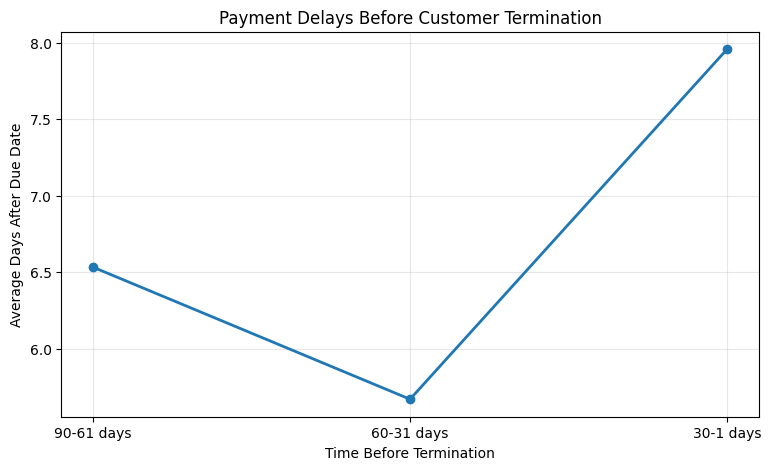

In [9]:
# STEP 9: Payment behavior before customer termination

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

records = []

for _, customer in eligible.iterrows():

    cid = customer["id"]
    end_date = customer["ended_date"]

    customer_payments = payment_history[
        payment_history["customer_id"] == cid
    ]

    for label, start_days, end_days in [
        ("90-61 days", 90, 60),
        ("60-31 days", 60, 30),
        ("30-1 days", 30, 0)
    ]:

        start_date = end_date - pd.Timedelta(days=start_days)
        stop_date = end_date - pd.Timedelta(days=end_days)

        window_payments = customer_payments[
            (customer_payments["payment_date"] >= start_date)
            & (customer_payments["payment_date"] < stop_date)
        ]

        records.append({
            "customer_id": cid,
            "window": label,
            "payment_count": len(window_payments),
            "avg_days_after_due": (
                window_payments["days_after_due"].mean()
                if len(window_payments) > 0
                else np.nan
            )
        })

payment_trends_df = pd.DataFrame(records)

window_order = [
    "90-61 days",
    "60-31 days",
    "30-1 days"
]

average_delays = (
    payment_trends_df.groupby("window")["avg_days_after_due"]
    .mean()
    .reindex(window_order)
)

print("Eligible ended customers:", len(eligible))

print("\nAverage payment delay by window:")
print(average_delays)

print("\nCustomers with payment records in each window:")
print(
    payment_trends_df.groupby("window")["avg_days_after_due"]
    .count()
    .reindex(window_order)
)

plt.figure(figsize=(9, 5))

plt.plot(
    window_order,
    average_delays.values,
    marker="o",
    linewidth=2
)

plt.title("Payment Delays Before Customer Termination")
plt.xlabel("Time Before Termination")
plt.ylabel("Average Days After Due Date")
plt.grid(alpha=0.3)
plt.show()

In [10]:
# STEP 10: Combine invoice and payment behavior

# Reshape payment trends
payment_wide = payment_trends_df.pivot(
    index="customer_id",
    columns="window",
    values="avg_days_after_due"
).reset_index()

# Calculate payment delay change
payment_wide["delay_change_days"] = (
    payment_wide["30-1 days"]
    - payment_wide["90-61 days"]
)

# Combine with invoice trends
combined = customer_trends.merge(
    payment_wide[
        ["customer_id", "delay_change_days"]
    ],
    on="customer_id",
    how="inner"
)

# Identify signals
combined["invoice_decline"] = (
    combined["trend"] == "Declining"
)

combined["payment_deterioration"] = (
    combined["delay_change_days"] >= 3
)

combined["both_signals"] = (
    combined["invoice_decline"]
    & combined["payment_deterioration"]
)

print("Customers analyzed:", len(combined))

print("\nInvoice decline:", combined["invoice_decline"].sum())

print(
    "Payment deterioration:",
    combined["payment_deterioration"].sum()
)

print(
    "Both signals:",
    combined["both_signals"].sum()
)

print("\nCustomer-level results:")

print(
    combined[
        [
            "customer_id",
            "change_pct",
            "delay_change_days",
            "invoice_decline",
            "payment_deterioration",
            "both_signals"
        ]
    ]
    .sort_values(
        ["both_signals", "delay_change_days"],
        ascending=[False, False]
    )
    .to_string(index=False)
)

Customers analyzed: 24

Invoice decline: 7
Payment deterioration: 5
Both signals: 3

Customer-level results:
      customer_id  change_pct  delay_change_days  invoice_decline  payment_deterioration  both_signals
 cust-customer-18  -40.000000          12.375000             True                   True          True
 cust-customer-10  -42.857143           3.546154             True                   True          True
  cust-customer-8  -42.857143           3.000000             True                   True          True
cust-customer-101   25.000000          25.011111            False                   True         False
cust-customer-110  -20.000000          10.412698            False                   True         False
 cust-customer-62    0.000000           1.050000            False                  False         False
cust-customer-111   50.000000           0.916667            False                  False         False
 cust-customer-63  -50.000000           0.800000             True  

In [11]:
# STEP 11: Inspect customer 18

customer_id = "cust-customer-18"

customer = customers_df[
    customers_df["id"] == customer_id
].iloc[0]

customer_invoices = invoices_df[
    invoices_df["customer_id"] == customer_id
].sort_values("txn_date")

customer_payments = payment_history[
    payment_history["customer_id"] == customer_id
].sort_values("payment_date")

print("CUSTOMER:", customer["display_name"])
print("Joined:", customer["joined_date"])
print("Ended:", customer["ended_date"])

print("\nTotal invoices:", len(customer_invoices))
print("Total payment applications:", len(customer_payments))

print("\nInvoice date range:")
print(
    customer_invoices["txn_date"].min(),
    "to",
    customer_invoices["txn_date"].max()
)

print("\nPayment date range:")
print(
    customer_payments["payment_date"].min(),
    "to",
    customer_payments["payment_date"].max()
)

print("\nLast 10 invoices:")
print(
    customer_invoices[
        ["id", "txn_date", "due_date", "total_amount"]
    ].tail(10).to_string(index=False)
)

print("\nLast 10 payment applications:")
print(
    customer_payments[
        [
            "invoice_id",
            "payment_date",
            "applied_amount",
            "days_after_due"
        ]
    ].tail(10).to_string(index=False)
)

CUSTOMER: Fairhaven Pottery Group
Joined: 2025-10-06 00:00:00
Ended: 2026-10-01 00:00:00

Total invoices: 54
Total payment applications: 105

Invoice date range:
2025-10-30 00:00:00 to 2026-09-25 00:00:00

Payment date range:
2025-11-02 00:00:00 to 2026-10-06 00:00:00

Last 10 invoices:
       id   txn_date   due_date  total_amount
inv-04821 2026-07-21 2026-07-28        259.16
inv-04943 2026-07-29 2026-08-05        348.80
inv-04998 2026-07-31 2026-08-07        256.70
inv-05063 2026-08-05 2026-08-12        591.60
inv-05194 2026-08-12 2026-08-19        547.40
inv-05348 2026-08-21 2026-08-28        238.00
inv-05469 2026-08-28 2026-09-04        591.60
inv-05594 2026-09-04 2026-09-11        631.96
inv-05694 2026-09-10 2026-09-17        200.00
inv-05944 2026-09-25 2026-10-02        451.26

Last 10 payment applications:
invoice_id payment_date  applied_amount  days_after_due
 inv-04278   2026-09-06           58.37              73
 inv-05348   2026-09-09          214.20              12
 inv-05

In [12]:
# STEP 12: Build first historical vs current customer state

import pandas as pd

customer_id = "cust-customer-18"

cutoff = pd.Timestamp("2026-08-31")

baseline_start = pd.Timestamp("2026-06-02")
baseline_end = pd.Timestamp("2026-07-31")

current_start = pd.Timestamp("2026-08-01")
current_end = cutoff

def calculate_state(start, end):
    # Only invoices known within this period
    inv = invoices_df[
        (invoices_df["customer_id"] == customer_id)
        & (invoices_df["txn_date"].between(start, end))
    ]

    # Only payment applications observed within this period
    pay = payment_history[
        (payment_history["customer_id"] == customer_id)
        & (payment_history["payment_date"].between(start, end))
    ]

    days = (end - start).days + 1

    return {
        "start": start.date().isoformat(),
        "end": end.date().isoformat(),
        "days": days,
        "invoice_count": len(inv),
        "invoices_per_30_days": round(len(inv) / days * 30, 2),
        "total_invoice_amount": round(inv["total_amount"].sum(), 2),
        "average_invoice_amount": round(
            inv["total_amount"].mean(), 2
        ) if len(inv) else 0,
        "payment_applications": len(pay),
        "average_payment_delay_days": round(
            pay["days_after_due"].mean(), 2
        ) if len(pay) else None,
        "late_payment_application_pct": round(
            (pay["days_after_due"] > 0).mean() * 100, 2
        ) if len(pay) else None
    }

historical_state = calculate_state(
    baseline_start, baseline_end
)

current_state = calculate_state(
    current_start, current_end
)

print("CUSTOMER:", customer["display_name"])
print("CUTOFF:", cutoff.date())

print("\nHISTORICAL STATE:")
for key, value in historical_state.items():
    print(f"{key}: {value}")

print("\nCURRENT STATE:")
for key, value in current_state.items():
    print(f"{key}: {value}")

print("\nCHANGES:")

print(
    "Invoice frequency change:",
    round(
        (
            current_state["invoices_per_30_days"]
            / historical_state["invoices_per_30_days"]
            - 1
        ) * 100, 2
    ) if historical_state["invoices_per_30_days"] else None,
    "%"
)

print(
    "Payment delay change:",
    round(
        current_state["average_payment_delay_days"]
        - historical_state["average_payment_delay_days"], 2
    )
    if (
        current_state["average_payment_delay_days"] is not None
        and historical_state["average_payment_delay_days"] is not None
    )
    else None,
    "days"
)

CUSTOMER: Fairhaven Pottery Group
CUTOFF: 2026-08-31

HISTORICAL STATE:
start: 2026-06-02
end: 2026-07-31
days: 60
invoice_count: 11
invoices_per_30_days: 5.5
total_invoice_amount: 4123.92
average_invoice_amount: 374.9
payment_applications: 20
average_payment_delay_days: 13.85
late_payment_application_pct: 60.0

CURRENT STATE:
start: 2026-08-01
end: 2026-08-31
days: 31
invoice_count: 4
invoices_per_30_days: 3.87
total_invoice_amount: 1968.6
average_invoice_amount: 492.15
payment_applications: 9
average_payment_delay_days: 10.89
late_payment_application_pct: 77.78

CHANGES:
Invoice frequency change: -29.64 %
Payment delay change: -2.96 days


In [13]:
# STEP 13: Reconstruct receivables as of August 31, 2026

import pandas as pd

customer_id = "cust-customer-18"
cutoff = pd.Timestamp("2026-08-31")

# Invoices issued by cutoff
inv = invoices_df[
    (invoices_df["customer_id"] == customer_id)
    & (invoices_df["txn_date"] <= cutoff)
].copy()

inv["due_date"] = pd.to_datetime(inv["due_date"])

# Payments received by cutoff
pay = payment_history[
    (payment_history["customer_id"] == customer_id)
    & (payment_history["payment_date"] <= cutoff)
].copy()

# Total applied payments by invoice
paid_by_invoice = (
    pay.groupby("invoice_id")["applied_amount"]
    .sum()
)

inv["paid_as_of_cutoff"] = (
    inv["id"].map(paid_by_invoice).fillna(0)
)

inv["outstanding"] = (
    inv["total_amount"]
    - inv["paid_as_of_cutoff"]
).round(2)

inv["is_overdue"] = (
    (inv["due_date"] < cutoff)
    & (inv["outstanding"] > 0.01)
)

print("CUSTOMER: Fairhaven Pottery Group")
print("AS OF:", cutoff.date())

print("\nTotal invoiced:", round(inv["total_amount"].sum(), 2))
print("Total paid:", round(inv["paid_as_of_cutoff"].sum(), 2))
print("Outstanding balance:", round(inv["outstanding"].sum(), 2))

print(
    "Overdue balance:",
    round(inv.loc[inv["is_overdue"], "outstanding"].sum(), 2)
)

print(
    "Number of overdue invoices:",
    inv["is_overdue"].sum()
)

print("\nOutstanding invoices:")
print(
    inv.loc[inv["outstanding"] > 0.01,
        ["id", "due_date", "total_amount",
         "paid_as_of_cutoff", "outstanding", "is_overdue"]
    ]
    .sort_values("due_date")
    .to_string(index=False)
)

CUSTOMER: Fairhaven Pottery Group
AS OF: 2026-08-31

Total invoiced: 21940.32
Total paid: 20095.53
Outstanding balance: 1844.79
Overdue balance: 1253.19
Number of overdue invoices: 3

Outstanding invoices:
       id   due_date  total_amount  paid_as_of_cutoff  outstanding  is_overdue
inv-02681 2026-03-27        956.82               0.00       956.82        True
inv-04278 2026-06-25        583.68             525.31        58.37        True
inv-05348 2026-08-28        238.00               0.00       238.00        True
inv-05469 2026-09-04        591.60               0.00       591.60       False


In [14]:
# STEP 14: Inspect invoice adjustment fields

print("Invoice fields:")
print(list(invoices_df.columns))

print("\nCustomer payment fields:")
print(list(payments_df.columns))

print("\nOutstanding invoice details:")
print(
    inv.loc[
        inv["outstanding"] > 0.01,
        [
            "id",
            "deposit_applied_amount",
            "retainage_amount",
            "total_amount"
        ]
    ].to_string(index=False)
)

Invoice fields:
['id', 'doc_number', 'customer_id', 'customer_name', 'txn_sim_day', 'txn_date', 'due_sim_day', 'due_date', 'lines', 'total_amount', 'income_account_id', 'project_id', 'deposit_applied_amount', 'retainage_amount', 'deposit_account_id', 'retainage_account_id', 'memo', 'provenance_note', 'sim_order_id', 'sim_obligation_id', 'sim_event_ids']

Customer payment fields:
['id', 'customer_id', 'customer_name', 'txn_sim_day', 'txn_date', 'amount', 'applications', 'unapplied_amount', 'settles', 'source_account_id', 'deposit_account_id', 'project_id', 'memo', 'provenance_note', 'sim_payment_id', 'sim_obligation_id', 'sim_event_ids']

Outstanding invoice details:
       id deposit_applied_amount retainage_amount  total_amount
inv-02681                   0.00             0.00        956.82
inv-04278                   0.00             0.00        583.68
inv-05348                   0.00             0.00        238.00
inv-05469                   0.00             0.00        591.60


In [15]:
def get_customer_financial_state(customer_id, as_of_date):

    as_of = pd.Timestamp(as_of_date)

    # Invoices available at this date
    customer_inv = invoices_df[
        (invoices_df["customer_id"] == customer_id)
        & (invoices_df["txn_date"] <= as_of)
    ].copy()

    customer_inv["due_date"] = pd.to_datetime(
        customer_inv["due_date"]
    )

    # Payments available at this date
    customer_pay = payment_history[
        (payment_history["customer_id"] == customer_id)
        & (payment_history["payment_date"] <= as_of)
    ].copy()

    paid_by_invoice = (
        customer_pay.groupby("invoice_id")["applied_amount"]
        .sum()
    )

    customer_inv["paid"] = (
        customer_inv["id"]
        .map(paid_by_invoice)
        .fillna(0)
    )

    customer_inv["outstanding"] = (
        customer_inv["total_amount"]
        - customer_inv["paid"]
    ).round(2)

    customer_inv["days_overdue"] = (
        as_of - customer_inv["due_date"]
    ).dt.days.clip(lower=0)

    open_inv = customer_inv[
        customer_inv["outstanding"] > 0.01
    ]

    overdue_inv = open_inv[
        open_inv["days_overdue"] > 0
    ]

    # Recent purchasing activity
    recent_inv = customer_inv[
        customer_inv["txn_date"] > as_of - pd.Timedelta(days=30)
    ]

    previous_inv = customer_inv[
        (customer_inv["txn_date"] > as_of - pd.Timedelta(days=60))
        & (customer_inv["txn_date"] <= as_of - pd.Timedelta(days=30))
    ]

    state = {
        "customer_id": customer_id,
        "as_of_date": str(as_of.date()),

        "outstanding_ar": round(
            open_inv["outstanding"].sum(), 2
        ),

        "overdue_ar": round(
            overdue_inv["outstanding"].sum(), 2
        ),

        "overdue_invoice_count": len(overdue_inv),

        "max_days_overdue": (
            int(overdue_inv["days_overdue"].max())
            if len(overdue_inv) else 0
        ),

        "recent_30d_invoice_count": len(recent_inv),

        "previous_30d_invoice_count": len(previous_inv),

        "recent_30d_revenue": round(
            recent_inv["total_amount"].sum(), 2
        ),

        "previous_30d_revenue": round(
            previous_inv["total_amount"].sum(), 2
        )
    }

    return state

In [16]:
state = get_customer_financial_state(
    "cust-customer-18",
    "2026-08-31"
)

for key, value in state.items():
    print(f"{key}: {value}")

customer_id: cust-customer-18
as_of_date: 2026-08-31
outstanding_ar: 1844.79
overdue_ar: 1253.19
overdue_invoice_count: 3
max_days_overdue: 157
recent_30d_invoice_count: 4
previous_30d_invoice_count: 5
recent_30d_revenue: 1968.6
previous_30d_revenue: 1588.18


In [17]:
# STEP 16: Replay a real invoice event

customer_id = "cust-customer-18"

before = get_customer_financial_state(
    customer_id, "2026-09-03"
)

after = get_customer_financial_state(
    customer_id, "2026-09-04"
)

print("BEFORE EVENT:")
for key, value in before.items():
    print(f"{key}: {value}")

print("\nAFTER EVENT:")
for key, value in after.items():
    print(f"{key}: {value}")

print("\nSTATE CHANGES:")

for key in before:
    if key in ["customer_id", "as_of_date"]:
        continue

    old = before[key]
    new = after[key]

    print(f"{key}: {old} → {new} (Δ {round(new - old, 2)})")

BEFORE EVENT:
customer_id: cust-customer-18
as_of_date: 2026-09-03
outstanding_ar: 1844.79
overdue_ar: 1253.19
overdue_invoice_count: 3
max_days_overdue: 160
recent_30d_invoice_count: 4
previous_30d_invoice_count: 5
recent_30d_revenue: 1968.6
previous_30d_revenue: 1588.18

AFTER EVENT:
customer_id: cust-customer-18
as_of_date: 2026-09-04
outstanding_ar: 2476.75
overdue_ar: 1253.19
overdue_invoice_count: 3
max_days_overdue: 161
recent_30d_invoice_count: 4
previous_30d_invoice_count: 6
recent_30d_revenue: 2008.96
previous_30d_revenue: 2179.78

STATE CHANGES:
outstanding_ar: 1844.79 → 2476.75 (Δ 631.96)
overdue_ar: 1253.19 → 1253.19 (Δ 0.0)
overdue_invoice_count: 3 → 3 (Δ 0)
max_days_overdue: 160 → 161 (Δ 1)
recent_30d_invoice_count: 4 → 4 (Δ 0)
previous_30d_invoice_count: 5 → 6 (Δ 1)
recent_30d_revenue: 1968.6 → 2008.96 (Δ 40.36)
previous_30d_revenue: 1588.18 → 2179.78 (Δ 591.6)


In [18]:
# STEP 17: Inspect all Fairhaven events on September 4

customer_id = "cust-customer-18"
event_date = pd.Timestamp("2026-09-04")

# Invoices issued that day
day_invoices = invoices_df[
    (invoices_df["customer_id"] == customer_id)
    & (invoices_df["txn_date"] == event_date)
]

# Payments received that day
day_payments = payments_df[
    (payments_df["customer_id"] == customer_id)
    & (payments_df["txn_date"] == event_date)
]

print("=== NEW INVOICES ===")
print("Count:", len(day_invoices))

for _, invoice in day_invoices.iterrows():
    print({
        "event_type": "invoice_created",
        "invoice_id": invoice["id"],
        "amount": float(invoice["total_amount"]),
        "due_date": invoice["due_date"],
        "memo": invoice["memo"]
    })

print("\n=== PAYMENTS RECEIVED ===")
print("Count:", len(day_payments))

for _, payment in day_payments.iterrows():
    print({
        "event_type": "payment_received",
        "payment_id": payment["id"],
        "amount": float(payment["amount"]),
        "applications": payment["applications"]
    })

print("\n=== SUMMARY ===")
print("New invoices:", len(day_invoices))
print("New payments:", len(day_payments))

=== NEW INVOICES ===
Count: 1
{'event_type': 'invoice_created', 'invoice_id': 'inv-05594', 'amount': 631.96, 'due_date': '2026-09-11', 'memo': 'Order shipped complete from our warehouse.'}

=== PAYMENTS RECEIVED ===
Count: 0

=== SUMMARY ===
New invoices: 1
New payments: 0


In [19]:
# STEP 18: Isolate the impact of one invoice event

customer_id = "cust-customer-18"
event_date = "2026-09-04"
event_id = "inv-05594"

# Calculate the state with the invoice included
state_after = get_customer_financial_state(
    customer_id,
    event_date
)

# Temporarily exclude this invoice to reconstruct
# the same-day state immediately before its creation
original_invoices_df = invoices_df

try:
    invoices_df = original_invoices_df[
        original_invoices_df["id"] != event_id
    ].copy()

    state_before = get_customer_financial_state(
        customer_id,
        event_date
    )

finally:
    invoices_df = original_invoices_df

# Compute direct state changes
event_delta = {}

for key in state_after:
    if key in ["customer_id", "as_of_date"]:
        continue

    event_delta[key] = round(
        state_after[key] - state_before[key], 2
    )

event = {
    "event_type": "invoice_created",
    "invoice_id": event_id,
    "amount": 631.96,
    "due_date": "2026-09-11",
    "memo": "Order shipped complete from our warehouse."
}

transition = {
    "customer_id": customer_id,
    "event_date": event_date,
    "event": event,
    "state_before": state_before,
    "state_after": state_after,
    "event_delta": event_delta
}

print("EVENT:")
print(transition["event"])

print("\nISOLATED EVENT IMPACT:")
for key, value in event_delta.items():
    print(f"{key}: {value}")

EVENT:
{'event_type': 'invoice_created', 'invoice_id': 'inv-05594', 'amount': 631.96, 'due_date': '2026-09-11', 'memo': 'Order shipped complete from our warehouse.'}

ISOLATED EVENT IMPACT:
outstanding_ar: 631.96
overdue_ar: 0.0
overdue_invoice_count: 0
max_days_overdue: 0
recent_30d_invoice_count: 1
previous_30d_invoice_count: 0
recent_30d_revenue: 631.96
previous_30d_revenue: 0.0


In [20]:
# STEP 19: Build a historical baseline before the event

customer_id = "cust-customer-18"
event_date = pd.Timestamp("2026-09-04")
baseline_start = event_date - pd.Timedelta(days=90)

historical_invoices = invoices_df[
    (invoices_df["customer_id"] == customer_id)
    & (invoices_df["txn_date"] >= baseline_start)
    & (invoices_df["txn_date"] < event_date)
].copy()

historical_invoices = historical_invoices.sort_values("txn_date")

invoice_amounts = historical_invoices["total_amount"]

historical_baseline = {
    "window_days": 90,
    "invoice_count": len(historical_invoices),
    "invoices_per_30_days": round(
        len(historical_invoices) / 90 * 30, 2
    ),
    "average_invoice_amount": round(
        invoice_amounts.mean(), 2
    ) if len(invoice_amounts) else None,
    "median_invoice_amount": round(
        invoice_amounts.median(), 2
    ) if len(invoice_amounts) else None,
    "invoice_amount_std": round(
        invoice_amounts.std(), 2
    ) if len(invoice_amounts) > 1 else None,
    "total_invoiced": round(
        invoice_amounts.sum(), 2
    )
}

new_invoice_amount = 631.96

print("HISTORICAL BASELINE:")
for key, value in historical_baseline.items():
    print(f"{key}: {value}")

print("\nNEW EVENT:")
print("Invoice amount:", new_invoice_amount)

if historical_baseline["average_invoice_amount"]:
    ratio = (
        new_invoice_amount
        / historical_baseline["average_invoice_amount"]
    )
    print(
        "Invoice amount vs historical average:",
        round(ratio, 2),
        "x"
    )

HISTORICAL BASELINE:
window_days: 90
invoice_count: 14
invoices_per_30_days: 4.67
average_invoice_amount: 403.04
median_invoice_amount: 383.02
invoice_amount_std: 153.92
total_invoiced: 5642.6

NEW EVENT:
Invoice amount: 631.96
Invoice amount vs historical average: 1.57 x


In [21]:
# STEP 20: Construct the first Jev-ready event record

import json

jev_input = {
    "customer_id": customer_id,
    "event_timestamp": event_date.isoformat(),

    "event": transition["event"],

    "financial_state_before": transition["state_before"],

    "financial_state_after": transition["state_after"],

    "event_impact": transition["event_delta"],

    "historical_baseline": historical_baseline,

    "derived_context": {
        "invoice_vs_average_ratio": round(
            transition["event"]["amount"]
            / historical_baseline["average_invoice_amount"],
            2
        ),

        "invoice_amount_z_score": round(
            (
                transition["event"]["amount"]
                - historical_baseline["average_invoice_amount"]
            )
            / historical_baseline["invoice_amount_std"],
            2
        ),

        "overdue_ar_share_before": round(
            transition["state_before"]["overdue_ar"]
            / transition["state_before"]["outstanding_ar"],
            3
        ) if transition["state_before"]["outstanding_ar"] > 0 else 0
    }
}

print(json.dumps(jev_input, indent=2, default=str))

{
  "customer_id": "cust-customer-18",
  "event_timestamp": "2026-09-04T00:00:00",
  "event": {
    "event_type": "invoice_created",
    "invoice_id": "inv-05594",
    "amount": 631.96,
    "due_date": "2026-09-11",
    "memo": "Order shipped complete from our warehouse."
  },
  "financial_state_before": {
    "customer_id": "cust-customer-18",
    "as_of_date": "2026-09-04",
    "outstanding_ar": 1844.79,
    "overdue_ar": 1253.19,
    "overdue_invoice_count": 3,
    "max_days_overdue": 161,
    "recent_30d_invoice_count": 3,
    "previous_30d_invoice_count": 6,
    "recent_30d_revenue": 1377.0,
    "previous_30d_revenue": 2179.78
  },
  "financial_state_after": {
    "customer_id": "cust-customer-18",
    "as_of_date": "2026-09-04",
    "outstanding_ar": 2476.75,
    "overdue_ar": 1253.19,
    "overdue_invoice_count": 3,
    "max_days_overdue": 161,
    "recent_30d_invoice_count": 4,
    "previous_30d_invoice_count": 6,
    "recent_30d_revenue": 2008.96,
    "previous_30d_revenue": 2

In [22]:
# STEP 21: Define the event-level detection contract

detection_request = {
    "task": "customer_relationship_change_detection",
    "schema_version": "1.0",

    "objective": (
        "Determine whether the new event represents a meaningful "
        "change in the customer relationship, compared with the "
        "customer's prior financial state and historical behavior."
    ),

    "decision_rules": [
        "Distinguish existing financial risk from new event impact.",
        "Do not treat every increase in accounts receivable as deterioration.",
        "Consider the event's meaning relative to historical behavior.",
        "Use only information available at the event timestamp.",
        "Do not infer customer intent without supporting evidence.",
        "Escalate ambiguous or potentially consequential changes."
    ],

    "allowed_change_types": [
        "positive",
        "negative",
        "neutral",
        "ambiguous"
    ],

    "allowed_severities": [
        "low",
        "medium",
        "high"
    ],

    "required_output": {
        "meaningful_change": "boolean",
        "change_type": "string",
        "severity": "string",
        "reason": "string",
        "needs_system_two": "boolean"
    },

    "input": jev_input
}

print("Detection request created.")
print("Task:", detection_request["task"])
print("Schema version:", detection_request["schema_version"])
print("Input event:", detection_request["input"]["event"])
print("Required output:", detection_request["required_output"])

Detection request created.
Task: customer_relationship_change_detection
Schema version: 1.0
Input event: {'event_type': 'invoice_created', 'invoice_id': 'inv-05594', 'amount': 631.96, 'due_date': '2026-09-11', 'memo': 'Order shipped complete from our warehouse.'}
Required output: {'meaningful_change': 'boolean', 'change_type': 'string', 'severity': 'string', 'reason': 'string', 'needs_system_two': 'boolean'}


In [23]:
# STEP 22: Create a controlled synthetic evaluation scenario

import copy

synthetic_event_input = copy.deepcopy(jev_input)

synthetic_event_input["event"] = {
    "event_type": "customer_communication",
    "channel": "email",
    "message": (
        "Starting next month, we're moving most of our purchases "
        "to another supplier. Please expect our order volume "
        "to drop significantly."
    ),
    "synthetic": True
}

# Communication does not directly change accounting balances.
# The before/after financial state stays identical.
synthetic_event_input["financial_state_after"] = copy.deepcopy(
    synthetic_event_input["financial_state_before"]
)

synthetic_event_input["event_impact"] = {
    key: 0
    for key in jev_input["event_impact"]
}

# Ground truth is stored separately from model input.
# Jev must not see this label.
synthetic_ground_truth = {
    "meaningful_change": True,
    "change_type": "negative",
    "severity": "high",
    "needs_system_two": True,
    "label_source": "controlled_synthetic_scenario"
}

print("SYNTHETIC EVENT:")
print(synthetic_event_input["event"])

print("\nFINANCIAL STATE CHANGED?")
print(
    synthetic_event_input["financial_state_before"]
    != synthetic_event_input["financial_state_after"]
)

print("\nEXPECTED LABEL (NOT SENT TO JEV):")
print(synthetic_ground_truth)

SYNTHETIC EVENT:
{'event_type': 'customer_communication', 'channel': 'email', 'message': "Starting next month, we're moving most of our purchases to another supplier. Please expect our order volume to drop significantly.", 'synthetic': True}

FINANCIAL STATE CHANGED?
False

EXPECTED LABEL (NOT SENT TO JEV):
{'meaningful_change': True, 'change_type': 'negative', 'severity': 'high', 'needs_system_two': True, 'label_source': 'controlled_synthetic_scenario'}


In [24]:
# STEP 23: Prepare the synthetic event for Jev

import copy
import json

jev_test_request = copy.deepcopy(detection_request)

# Replace the original invoice event with our synthetic message
jev_test_request["input"] = copy.deepcopy(
    synthetic_event_input
)

# Remove the synthetic marker from model-facing data.
# Keep provenance in our evaluation records instead.
jev_test_request["input"]["event"].pop("synthetic", None)

# Basic leakage checks
request_text = json.dumps(jev_test_request)

assert "synthetic_ground_truth" not in request_text
assert "label_source" not in request_text
assert "ended_date" not in request_text
assert "has_ended" not in request_text

print("MODEL INPUT READY")
print("\nEVENT:")
print(json.dumps(
    jev_test_request["input"]["event"],
    indent=2
))

print("\nGROUND TRUTH EXCLUDED:", 
      "label_source" not in request_text)

print("\nREQUEST SIZE:")
print("Characters:", len(request_text))

print("\nOUTPUT FIELDS:")
print(jev_test_request["required_output"])

MODEL INPUT READY

EVENT:
{
  "event_type": "customer_communication",
  "channel": "email",
  "message": "Starting next month, we're moving most of our purchases to another supplier. Please expect our order volume to drop significantly."
}

GROUND TRUTH EXCLUDED: True

REQUEST SIZE:
Characters: 2439

OUTPUT FIELDS:
{'meaningful_change': 'boolean', 'change_type': 'string', 'severity': 'string', 'reason': 'string', 'needs_system_two': 'boolean'}


In [25]:
from pathlib import Path
import yaml
import pandas as pd

# Root directory containing the hackathon dataset
DATA_ROOT = Path("hackathon-100")

# Selected company
COMPANY_ID = "company-003"

# Locate the company's data directory
company_path = DATA_ROOT / COMPANY_ID / "rwm-v4" / "world-05d64e2d010225ca"

print("Company path:", company_path)
print("Directory exists:", company_path.exists())

# Load QuickBooks-style data
with open(company_path / "customers.yaml", "r") as f:
    customers_data = yaml.safe_load(f)

with open(company_path / "invoices.yaml", "r") as f:
    invoices_data = yaml.safe_load(f)

with open(company_path / "customer_payments.yaml", "r") as f:
    payments_data = yaml.safe_load(f)

# Convert to DataFrames
customers_df = pd.DataFrame(customers_data)
invoices_df = pd.DataFrame(invoices_data)
payments_df = pd.DataFrame(payments_data)

print("\n========== COMPANY-003 DATA ==========")
print("Customers:", len(customers_df))
print("Invoices:", len(invoices_df))
print("Payments:", len(payments_df))

print("\nCustomer columns:")
print(customers_df.columns.tolist())

print("\nInvoice columns:")
print(invoices_df.columns.tolist())

print("\nPayment columns:")
print(payments_df.columns.tolist())

Company path: hackathon-100/company-003/rwm-v4/world-05d64e2d010225ca
Directory exists: True

========== COMPANY-003 DATA ==========
Customers: 136
Invoices: 5132
Payments: 9813

Customer columns:
['id', 'display_name', 'company_name', 'contact_given_name', 'contact_family_name', 'email', 'phone', 'address', 'payment_terms', 'payment_terms_days', 'credit_limit_amount', 'joined_sim_day', 'joined_date', 'ended_sim_day', 'ended_date', 'ended_sim_event_id', 'notes', 'sim_actor_id', 'sim_event_ids']

Invoice columns:
['id', 'doc_number', 'customer_id', 'customer_name', 'txn_sim_day', 'txn_date', 'due_sim_day', 'due_date', 'lines', 'total_amount', 'income_account_id', 'project_id', 'deposit_applied_amount', 'retainage_amount', 'deposit_account_id', 'retainage_account_id', 'memo', 'provenance_note', 'sim_order_id', 'sim_obligation_id', 'sim_event_ids']

Payment columns:
['id', 'customer_id', 'customer_name', 'txn_sim_day', 'txn_date', 'amount', 'applications', 'unapplied_amount', 'settles', '

In [26]:
# Invoice events
invoice_events = invoices_df[
    ["id", "customer_id", "txn_date", "total_amount", "memo"]
].copy()

invoice_events = invoice_events.rename(columns={
    "id": "event_id",
    "txn_date": "event_date",
    "total_amount": "amount",
    "memo": "description",
})

invoice_events["event_type"] = "invoice_created"


# Payment events
payment_events = payments_df[
    ["id", "customer_id", "txn_date", "amount", "memo"]
].copy()

payment_events = payment_events.rename(columns={
    "id": "event_id",
    "txn_date": "event_date",
    "memo": "description",
})

payment_events["event_type"] = "payment_received"


# Combine into one event timeline
events_df = pd.concat(
    [invoice_events, payment_events],
    ignore_index=True
)

events_df["event_date"] = pd.to_datetime(
    events_df["event_date"]
)

# Sort chronologically within each customer
events_df = events_df.sort_values(
    ["customer_id", "event_date", "event_type", "event_id"]
).reset_index(drop=True)

# Previous observed event for each customer
events_df["previous_event_id"] = (
    events_df.groupby("customer_id")["event_id"].shift(1)
)

events_df["previous_event_type"] = (
    events_df.groupby("customer_id")["event_type"].shift(1)
)

events_df["previous_event_date"] = (
    events_df.groupby("customer_id")["event_date"].shift(1)
)

print("========== EVENT TIMELINE ==========")
print("Total events:", len(events_df))

print("\nEvents by type:")
print(events_df["event_type"].value_counts())

print("\nDate range:")
print(events_df["event_date"].min(), "to", events_df["event_date"].max())

print("\nFirst 10 events:")
display(events_df.head(10))

========== EVENT TIMELINE ==========
Total events: 14945

Events by type:
event_type
payment_received    9813
invoice_created     5132
Name: count, dtype: int64

Date range:
2025-10-13 00:00:00 to 2026-10-06 00:00:00

First 10 events:


,event_id,customer_id,event_date,amount,description,event_type,previous_event_id,previous_event_type,previous_event_date
0,inv-00220,cust-customer-1,2025-10-21,436.00,Order shipped complete from our warehouse.,invoice_created,NaN,NaN,NaT
1,rcpt-00047,cust-customer-1,2025-10-23,353.16,Payment received against invoice.,payment_received,inv-00220,invoice_created,2025-10-21
2,rcpt-00108,cust-customer-1,2025-10-31,82.84,Payment received against invoice.,payment_received,rcpt-00047,payment_received,2025-10-23
3,inv-00329,cust-customer-1,2025-11-06,512.30,Thank you for your order.,invoice_created,rcpt-00108,payment_received,2025-10-31
4,rcpt-00217,cust-customer-1,2025-11-09,414.96,Payment received against invoice.,payment_received,inv-00329,invoice_created,2025-11-06
5,rcpt-00321,cust-customer-1,2025-11-15,97.34,Payment received against invoice.,payment_received,rcpt-00217,payment_received,2025-11-09
6,inv-00452,cust-customer-1,2025-11-24,457.80,Thank you for your order.,invoice_created,rcpt-00321,payment_received,2025-11-15
7,rcpt-00516,cust-customer-1,2025-11-26,370.81,Payment received against invoice.,payment_received,inv-00452,invoice_created,2025-11-24
8,rcpt-00627,cust-customer-1,2025-12-03,86.99,Payment received against invoice.,payment_received,rcpt-00516,payment_received,2025-11-26
9,inv-00572,cust-customer-1,2025-12-04,191.88,Thank you for your order.,invoice_created,rcpt-00627,payment_received,2025-12-03


In [27]:
print("========== PAYMENT APPLICATION STRUCTURE ==========")

# Find a payment that has at least one application
sample_payments = payments_df[
    payments_df["applications"].apply(
        lambda x: isinstance(x, list) and len(x) > 0
    )
]

print("Payments with applications:", len(sample_payments))

if not sample_payments.empty:
    sample = sample_payments.iloc[0]

    print("\nPayment ID:", sample["id"])
    print("Customer ID:", sample["customer_id"])
    print("Payment date:", sample["txn_date"])
    print("Payment amount:", sample["amount"])

    print("\nApplications:")
    from pprint import pprint
    pprint(sample["applications"])

    print("\nSettles:")
    pprint(sample["settles"])

print("\n========== INVOICE DATE FIELDS ==========")

sample_invoice = invoices_df.iloc[0]

print("Invoice ID:", sample_invoice["id"])
print("Invoice date:", sample_invoice["txn_date"])
print("Due date:", sample_invoice["due_date"])
print("Invoice amount:", sample_invoice["total_amount"])

========== PAYMENT APPLICATION STRUCTURE ==========
Payments with applications: 9813

Payment ID: rcpt-00006
Customer ID: cust-customer-26
Payment date: 2025-10-14
Payment amount: 75.10

Applications:
[{'amount': '75.10', 'document_id': 'inv-00066'}]

Settles:
'receivable'

========== INVOICE DATE FIELDS ==========
Invoice ID: inv-00063
Invoice date: 2025-10-13
Due date: 2025-10-20
Invoice amount: 283.40


In [28]:
import pandas as pd

# Prepare invoices
inv = invoices_df.copy()
inv["txn_date"] = pd.to_datetime(inv["txn_date"])
inv["due_date"] = pd.to_datetime(inv["due_date"])
inv["total_amount"] = pd.to_numeric(inv["total_amount"])

# Prepare payment applications
payment_rows = []

for _, payment in payments_df.iterrows():
    for application in payment["applications"]:
        payment_rows.append({
            "customer_id": payment["customer_id"],
            "invoice_id": application["document_id"],
            "payment_date": pd.to_datetime(payment["txn_date"]),
            "applied_amount": float(application["amount"]),
        })

payment_applications = pd.DataFrame(payment_rows)


def get_financial_state(customer_id, as_of_date):
    """
    Financial state immediately before as_of_date.
    Only transactions dated earlier than as_of_date are included.
    """

    as_of_date = pd.Timestamp(as_of_date)

    customer_invoices = inv[
        (inv["customer_id"] == customer_id)
        & (inv["txn_date"] < as_of_date)
    ].copy()

    customer_payments = payment_applications[
        (payment_applications["customer_id"] == customer_id)
        & (payment_applications["payment_date"] < as_of_date)
    ]

    paid_by_invoice = (
        customer_payments.groupby("invoice_id")["applied_amount"].sum()
    )

    customer_invoices["paid_amount"] = (
        customer_invoices["id"]
        .map(paid_by_invoice)
        .fillna(0.0)
    )

    customer_invoices["balance"] = (
        customer_invoices["total_amount"]
        - customer_invoices["paid_amount"]
    ).clip(lower=0)

    overdue = customer_invoices[
        (customer_invoices["due_date"] < as_of_date)
        & (customer_invoices["balance"] > 0.01)
    ]

    recent_start = as_of_date - pd.Timedelta(days=30)
    previous_start = as_of_date - pd.Timedelta(days=60)

    recent = customer_invoices[
        customer_invoices["txn_date"] >= recent_start
    ]

    previous = customer_invoices[
        (customer_invoices["txn_date"] >= previous_start)
        & (customer_invoices["txn_date"] < recent_start)
    ]

    return {
        "outstanding_ar": round(
            customer_invoices["balance"].sum(), 2
        ),
        "overdue_ar": round(
            overdue["balance"].sum(), 2
        ),
        "overdue_invoice_count": len(overdue),
        "max_days_overdue": (
            int((as_of_date - overdue["due_date"]).dt.days.max())
            if not overdue.empty else 0
        ),
        "recent_30d_invoice_count": len(recent),
        "previous_30d_invoice_count": len(previous),
        "recent_30d_revenue": round(
            recent["total_amount"].sum(), 2
        ),
        "previous_30d_revenue": round(
            previous["total_amount"].sum(), 2
        ),
    }


# Test on our previously investigated customer
test_state = get_financial_state(
    "cust-customer-18",
    "2026-09-04"
)

print("========== FINANCIAL STATE ==========")
print("Customer: cust-customer-18")
print("As of: 2026-09-04 (exclusive)")
print()

for key, value in test_state.items():
    print(f"{key}: {value}")

print("\nPayment applications:", len(payment_applications))

========== FINANCIAL STATE ==========
Customer: cust-customer-18
As of: 2026-09-04 (exclusive)

outstanding_ar: 1844.79
overdue_ar: 1253.19
overdue_invoice_count: 3
max_days_overdue: 161
recent_30d_invoice_count: 4
previous_30d_invoice_count: 5
recent_30d_revenue: 1968.6
previous_30d_revenue: 1588.18

Payment applications: 9813


In [29]:
import json

EVENT_ID = "inv-05594"

# Get the real invoice
event_invoice = inv.loc[inv["id"] == EVENT_ID].iloc[0]

customer_id = event_invoice["customer_id"]
event_date = pd.Timestamp(event_invoice["txn_date"])
amount = float(event_invoice["total_amount"])

# Financial state before the event date
old_state = get_financial_state(customer_id, event_date)

# Find the most recent event from an earlier date
previous_events = events_df[
    (events_df["customer_id"] == customer_id)
    & (events_df["event_date"] < event_date)
].sort_values(["event_date", "event_id"])

previous_event = None

if not previous_events.empty:
    prev = previous_events.iloc[-1]

    previous_event = {
        "event_id": prev["event_id"],
        "event_type": prev["event_type"],
        "event_date": prev["event_date"].strftime("%Y-%m-%d"),
        "amount": float(prev["amount"]),
        "description": prev["description"],
    }

# The event we're evaluating
new_event = {
    "event_id": EVENT_ID,
    "event_type": "invoice_created",
    "event_date": event_date.strftime("%Y-%m-%d"),
    "amount": amount,
    "due_date": pd.Timestamp(
        event_invoice["due_date"]
    ).strftime("%Y-%m-%d"),
    "description": event_invoice["memo"],
}

# Apply only this invoice's direct effects.
# No other same-day transactions are included.
current_state = old_state.copy()

current_state["outstanding_ar"] = round(
    old_state["outstanding_ar"] + amount, 2
)

current_state["recent_30d_invoice_count"] += 1

current_state["recent_30d_revenue"] = round(
    old_state["recent_30d_revenue"] + amount, 2
)

# Newly issued invoice is not overdue on its creation date.
event_impact = {
    "outstanding_ar_delta": round(amount, 2),
    "overdue_ar_delta": 0.0,
    "recent_30d_invoice_count_delta": 1,
    "recent_30d_revenue_delta": round(amount, 2),
}

benchmark_event = {
    "company_id": "company-003",
    "customer_id": customer_id,
    "event_date": event_date.strftime("%Y-%m-%d"),
    "old_state": old_state,
    "previous_event": previous_event,
    "new_event": new_event,
    "current_state": current_state,
    "event_impact": event_impact,
}

print(json.dumps(benchmark_event, indent=2, default=str))

{
  "company_id": "company-003",
  "customer_id": "cust-customer-18",
  "event_date": "2026-09-04",
  "old_state": {
    "outstanding_ar": 1844.79,
    "overdue_ar": 1253.19,
    "overdue_invoice_count": 3,
    "max_days_overdue": 161,
    "recent_30d_invoice_count": 4,
    "previous_30d_invoice_count": 5,
    "recent_30d_revenue": 1968.6,
    "previous_30d_revenue": 1588.18
  },
  "previous_event": {
    "event_id": "rcpt-09534",
    "event_type": "payment_received",
    "event_date": "2026-08-31",
    "amount": 525.31,
    "description": "Payment received against invoice."
  },
  "new_event": {
    "event_id": "inv-05594",
    "event_type": "invoice_created",
    "event_date": "2026-09-04",
    "amount": 631.96,
    "due_date": "2026-09-11",
    "description": "Order shipped complete from our warehouse."
  },
  "current_state": {
    "outstanding_ar": 2476.75,
    "overdue_ar": 1253.19,
    "overdue_invoice_count": 3,
    "max_days_overdue": 161,
    "recent_30d_invoice_count": 5,
  

In [30]:
# Validate our first benchmark event

old = benchmark_event["old_state"]
new = benchmark_event["current_state"]
impact = benchmark_event["event_impact"]

checks = {
    "Outstanding AR change": (
        round(new["outstanding_ar"] - old["outstanding_ar"], 2)
        == impact["outstanding_ar_delta"]
    ),
    "Overdue AR change": (
        round(new["overdue_ar"] - old["overdue_ar"], 2)
        == impact["overdue_ar_delta"]
    ),
    "Invoice count change": (
        new["recent_30d_invoice_count"]
        - old["recent_30d_invoice_count"]
        == impact["recent_30d_invoice_count_delta"]
    ),
    "Recent revenue change": (
        round(new["recent_30d_revenue"] - old["recent_30d_revenue"], 2)
        == impact["recent_30d_revenue_delta"]
    ),
    "Previous event precedes new event": (
        benchmark_event["previous_event"] is None
        or benchmark_event["previous_event"]["event_date"]
        < benchmark_event["new_event"]["event_date"]
    ),
}

print("========== SNAPSHOT VALIDATION ==========")

for name, passed in checks.items():
    print(f"{'PASS' if passed else 'FAIL'} | {name}")

print("\nAll checks passed:", all(checks.values()))

========== SNAPSHOT VALIDATION ==========
PASS | Outstanding AR change
PASS | Overdue AR change
PASS | Invoice count change
PASS | Recent revenue change
PASS | Previous event precedes new event

All checks passed: True


In [31]:
import json
import time

invoice_snapshots = []
start = time.perf_counter()

# Cache financial states for customers with multiple invoices on the same day.
state_cache = {}

for _, invoice in inv.iterrows():
    customer_id = invoice["customer_id"]
    event_date = pd.Timestamp(invoice["txn_date"])
    event_id = invoice["id"]
    amount = float(invoice["total_amount"])

    cache_key = (customer_id, event_date)

    if cache_key not in state_cache:
        state_cache[cache_key] = get_financial_state(
            customer_id, event_date
        )

    old_state = state_cache[cache_key].copy()

    # Only events strictly before this date are eligible.
    previous_events = events_df[
        (events_df["customer_id"] == customer_id)
        & (events_df["event_date"] < event_date)
    ]

    previous_event = None

    if not previous_events.empty:
        prev = previous_events.iloc[-1]

        previous_event = {
            "event_id": prev["event_id"],
            "event_type": prev["event_type"],
            "event_date": prev["event_date"].strftime("%Y-%m-%d"),
            "amount": float(prev["amount"]),
            "description": prev["description"],
        }

    new_event = {
        "event_id": event_id,
        "event_type": "invoice_created",
        "event_date": event_date.strftime("%Y-%m-%d"),
        "amount": amount,
        "due_date": pd.Timestamp(
            invoice["due_date"]
        ).strftime("%Y-%m-%d"),
        "description": invoice["memo"],
    }

    current_state = old_state.copy()

    current_state["outstanding_ar"] = round(
        old_state["outstanding_ar"] + amount, 2
    )

    current_state["recent_30d_invoice_count"] += 1

    current_state["recent_30d_revenue"] = round(
        old_state["recent_30d_revenue"] + amount, 2
    )

    event_impact = {
        "outstanding_ar_delta": round(amount, 2),
        "overdue_ar_delta": 0.0,
        "recent_30d_invoice_count_delta": 1,
        "recent_30d_revenue_delta": round(amount, 2),
    }

    invoice_snapshots.append({
        "company_id": "company-003",
        "customer_id": customer_id,
        "event_date": event_date.strftime("%Y-%m-%d"),
        "old_state": old_state,
        "previous_event": previous_event,
        "new_event": new_event,
        "current_state": current_state,
        "event_impact": event_impact,
    })

elapsed = time.perf_counter() - start

print("========== INVOICE SNAPSHOTS ==========")
print("Generated:", len(invoice_snapshots))
print("Expected:", len(inv))
print(f"Generation time: {elapsed:.2f} seconds")

print("\nFirst snapshot:")
print(json.dumps(invoice_snapshots[0], indent=2, default=str))

print("\nSnapshot for inv-05594:")
matching = [
    s for s in invoice_snapshots
    if s["new_event"]["event_id"] == "inv-05594"
]

if matching:
    print(json.dumps(matching[0], indent=2, default=str))

========== INVOICE SNAPSHOTS ==========
Generated: 5132
Expected: 5132
Generation time: 10.91 seconds

First snapshot:
{
  "company_id": "company-003",
  "customer_id": "cust-customer-5",
  "event_date": "2025-10-13",
  "old_state": {
    "outstanding_ar": 0.0,
    "overdue_ar": 0.0,
    "overdue_invoice_count": 0,
    "max_days_overdue": 0,
    "recent_30d_invoice_count": 0,
    "previous_30d_invoice_count": 0,
    "recent_30d_revenue": 0.0,
    "previous_30d_revenue": 0.0
  },
  "previous_event": null,
  "new_event": {
    "event_id": "inv-00063",
    "event_type": "invoice_created",
    "event_date": "2025-10-13",
    "amount": 283.4,
    "due_date": "2025-10-20",
    "description": "Freight included. Pallets returnable on request."
  },
  "current_state": {
    "outstanding_ar": 283.4,
    "overdue_ar": 0.0,
    "overdue_invoice_count": 0,
    "max_days_overdue": 0,
    "recent_30d_invoice_count": 1,
    "previous_30d_invoice_count": 0,
    "recent_30d_revenue": 283.4,
    "previou

In [32]:
from collections import defaultdict
import pandas as pd

# Invoice lookup
invoice_lookup = inv.set_index("id")

# Payment applications grouped by payment ID
applications_by_payment = defaultdict(list)

for _, payment in payments_df.iterrows():
    applications_by_payment[payment["id"]] = (
        payment["applications"] or []
    )

def get_payment_impact(payment):
    """
    Compute the direct impact of one payment against
    invoice balances immediately before its date.

    Excludes same-day payment ordering assumptions.
    """

    customer_id = payment["customer_id"]
    payment_date = pd.Timestamp(payment["txn_date"])

    # Payments from earlier dates only
    earlier_payments = payment_applications[
        (payment_applications["customer_id"] == customer_id)
        & (payment_applications["payment_date"] < payment_date)
    ]

    paid_before = (
        earlier_payments.groupby("invoice_id")["applied_amount"].sum()
    )

    outstanding_reduction = 0.0
    overdue_reduction = 0.0
    overdue_invoices_cleared = 0

    for app in applications_by_payment[payment["id"]]:
        invoice_id = app["document_id"]
        applied_amount = float(app["amount"])

        if invoice_id not in invoice_lookup.index:
            continue

        invoice = invoice_lookup.loc[invoice_id]

        # Exclude invoices not yet issued before payment date.
        if pd.Timestamp(invoice["txn_date"]) >= payment_date:
            continue

        balance_before = max(
            float(invoice["total_amount"])
            - float(paid_before.get(invoice_id, 0.0)),
            0.0
        )

        reduction = min(applied_amount, balance_before)

        outstanding_reduction += reduction

        if pd.Timestamp(invoice["due_date"]) < payment_date:
            overdue_reduction += reduction

            if balance_before > 0.01 and (
                balance_before - reduction <= 0.01
            ):
                overdue_invoices_cleared += 1

    return {
        "outstanding_ar_delta": round(
            -outstanding_reduction, 2
        ),
        "overdue_ar_delta": round(
            -overdue_reduction, 2
        ),
        "overdue_invoice_count_delta": (
            -overdue_invoices_cleared
        ),
        "recent_30d_invoice_count_delta": 0,
        "recent_30d_revenue_delta": 0.0,
    }


# Test one payment first
sample_payment = payments_df.iloc[0]

print("Payment:", sample_payment["id"])
print("Customer:", sample_payment["customer_id"])
print("Date:", sample_payment["txn_date"])
print("Amount:", sample_payment["amount"])

print("\nCalculated impact:")
print(get_payment_impact(sample_payment))

Payment: rcpt-00006
Customer: cust-customer-26
Date: 2025-10-14
Amount: 75.10

Calculated impact:
{'outstanding_ar_delta': -75.1, 'overdue_ar_delta': -0.0, 'overdue_invoice_count_delta': 0, 'recent_30d_invoice_count_delta': 0, 'recent_30d_revenue_delta': 0.0}


In [33]:
# Find a payment that actually reduces overdue AR

overdue_example = None

for _, payment in payments_df.iterrows():
    impact = get_payment_impact(payment)

    if impact["overdue_ar_delta"] < 0:
        overdue_example = (payment, impact)
        break

if overdue_example is None:
    print("No payment reducing overdue AR was found.")
else:
    payment, impact = overdue_example

    old_state = get_financial_state(
        payment["customer_id"],
        payment["txn_date"]
    )

    print("========== OVERDUE PAYMENT TEST ==========")
    print("Payment ID:", payment["id"])
    print("Customer:", payment["customer_id"])
    print("Date:", payment["txn_date"])
    print("Payment amount:", payment["amount"])
    print("Applications:", payment["applications"])

    print("\nOld financial state:")
    print(old_state)

    print("\nPayment impact:")
    print(impact)

    print("\nOutstanding AR after isolated payment:",
          round(
              old_state["outstanding_ar"]
              + impact["outstanding_ar_delta"], 2
          ))

    print("Overdue AR after isolated payment:",
          round(
              old_state["overdue_ar"]
              + impact["overdue_ar_delta"], 2
          ))

========== OVERDUE PAYMENT TEST ==========
Payment ID: rcpt-00038
Customer: cust-customer-33
Date: 2025-10-22
Payment amount: 179.85
Applications: [{'document_id': 'inv-00067', 'amount': '179.85'}]

Old financial state:
{'outstanding_ar': np.float64(327.0), 'overdue_ar': np.float64(327.0), 'overdue_invoice_count': 1, 'max_days_overdue': 2, 'recent_30d_invoice_count': 1, 'previous_30d_invoice_count': 0, 'recent_30d_revenue': np.float64(327.0), 'previous_30d_revenue': np.float64(0.0)}

Payment impact:
{'outstanding_ar_delta': -179.85, 'overdue_ar_delta': -179.85, 'overdue_invoice_count_delta': 0, 'recent_30d_invoice_count_delta': 0, 'recent_30d_revenue_delta': 0.0}

Outstanding AR after isolated payment: 147.15
Overdue AR after isolated payment: 147.15


In [34]:
same_day_payments = []
missing_invoice_payments = []
cross_customer_payments = []

for _, payment in payments_df.iterrows():
    payment_date = pd.Timestamp(payment["txn_date"])

    for app in payment["applications"]:
        invoice_id = app["document_id"]

        if invoice_id not in invoice_lookup.index:
            missing_invoice_payments.append(payment["id"])
            continue

        invoice = invoice_lookup.loc[invoice_id]
        invoice_date = pd.Timestamp(invoice["txn_date"])

        if invoice_date == payment_date:
            same_day_payments.append(payment["id"])

        if invoice["customer_id"] != payment["customer_id"]:
            cross_customer_payments.append(payment["id"])

print("========== PAYMENT DATA QUALITY ==========")
print("Payments with same-day invoice applications:",
      len(set(same_day_payments)))

print("Payments referencing missing invoices:",
      len(set(missing_invoice_payments)))

print("Payments referencing another customer's invoice:",
      len(set(cross_customer_payments)))

print("\nExample same-day payments:")
print(list(dict.fromkeys(same_day_payments))[:5])

========== PAYMENT DATA QUALITY ==========
Payments with same-day invoice applications: 0
Payments referencing missing invoices: 0
Payments referencing another customer's invoice: 0

Example same-day payments:
[]


In [35]:
def get_state_after_payment(payment):
    """
    Return old state, isolated post-payment state, and impact.

    Uses only transactions dated before the payment date,
    plus the specific payment being evaluated.
    """

    customer_id = payment["customer_id"]
    payment_date = pd.Timestamp(payment["txn_date"])

    old_state = get_financial_state(customer_id, payment_date)

    # Invoices issued before the payment date
    customer_invoices = inv[
        (inv["customer_id"] == customer_id)
        & (inv["txn_date"] < payment_date)
    ].copy()

    # Earlier payment applications only
    earlier_apps = payment_applications[
        (payment_applications["customer_id"] == customer_id)
        & (payment_applications["payment_date"] < payment_date)
    ]

    paid_before = (
        earlier_apps.groupby("invoice_id")["applied_amount"].sum()
    )

    # Apply the current payment to its linked invoices
    current_apps = {
        app["document_id"]: float(app["amount"])
        for app in payment["applications"]
    }

    customer_invoices["paid_before"] = (
        customer_invoices["id"].map(paid_before).fillna(0.0)
    )

    customer_invoices["current_payment"] = (
        customer_invoices["id"].map(current_apps).fillna(0.0)
    )

    customer_invoices["balance_after"] = (
        customer_invoices["total_amount"]
        - customer_invoices["paid_before"]
        - customer_invoices["current_payment"]
    ).clip(lower=0)

    overdue_after = customer_invoices[
        (customer_invoices["due_date"] < payment_date)
        & (customer_invoices["balance_after"] > 0.01)
    ]

    current_state = old_state.copy()

    current_state["outstanding_ar"] = round(
        float(customer_invoices["balance_after"].sum()), 2
    )

    current_state["overdue_ar"] = round(
        float(overdue_after["balance_after"].sum()), 2
    )

    current_state["overdue_invoice_count"] = len(overdue_after)

    current_state["max_days_overdue"] = (
        int((payment_date - overdue_after["due_date"]).dt.days.max())
        if not overdue_after.empty else 0
    )

    event_impact = {
        "outstanding_ar_delta": round(
            current_state["outstanding_ar"]
            - float(old_state["outstanding_ar"]), 2
        ),
        "overdue_ar_delta": round(
            current_state["overdue_ar"]
            - float(old_state["overdue_ar"]), 2
        ),
        "overdue_invoice_count_delta": (
            current_state["overdue_invoice_count"]
            - old_state["overdue_invoice_count"]
        ),
        "max_days_overdue_delta": (
            current_state["max_days_overdue"]
            - old_state["max_days_overdue"]
        ),
        "recent_30d_invoice_count_delta": 0,
        "recent_30d_revenue_delta": 0.0,
    }

    return old_state, current_state, event_impact


# Test on the overdue payment we just inspected
payment = payments_df.loc[
    payments_df["id"] == "rcpt-00038"
].iloc[0]

old_state, current_state, impact = get_state_after_payment(payment)

print("========== PAYMENT STATE VALIDATION ==========")
print("Payment:", payment["id"])
print("\nOld state:", old_state)
print("\nCurrent state:", current_state)
print("\nEvent impact:", impact)

assert current_state["outstanding_ar"] == 147.15
assert current_state["overdue_ar"] == 147.15
assert current_state["overdue_invoice_count"] == 1

print("\nPASS — Payment state reconstructed correctly!")

========== PAYMENT STATE VALIDATION ==========
Payment: rcpt-00038

Old state: {'outstanding_ar': np.float64(327.0), 'overdue_ar': np.float64(327.0), 'overdue_invoice_count': 1, 'max_days_overdue': 2, 'recent_30d_invoice_count': 1, 'previous_30d_invoice_count': 0, 'recent_30d_revenue': np.float64(327.0), 'previous_30d_revenue': np.float64(0.0)}

Current state: {'outstanding_ar': 147.15, 'overdue_ar': 147.15, 'overdue_invoice_count': 1, 'max_days_overdue': 2, 'recent_30d_invoice_count': 1, 'previous_30d_invoice_count': 0, 'recent_30d_revenue': np.float64(327.0), 'previous_30d_revenue': np.float64(0.0)}

Event impact: {'outstanding_ar_delta': -179.85, 'overdue_ar_delta': -179.85, 'overdue_invoice_count_delta': 0, 'max_days_overdue_delta': 0, 'recent_30d_invoice_count_delta': 0, 'recent_30d_revenue_delta': 0.0}

PASS — Payment state reconstructed correctly!


In [36]:
from collections import Counter

duplicate_application_payments = []

for _, payment in payments_df.iterrows():
    invoice_ids = [
        app["document_id"]
        for app in payment["applications"]
    ]

    counts = Counter(invoice_ids)

    duplicates = {
        invoice_id: count
        for invoice_id, count in counts.items()
        if count > 1
    }

    if duplicates:
        duplicate_application_payments.append({
            "payment_id": payment["id"],
            "duplicate_invoices": duplicates,
        })

print("========== DUPLICATE APPLICATION CHECK ==========")

print(
    "Payments with duplicate invoice applications:",
    len(duplicate_application_payments)
)

print("\nExamples:")
for example in duplicate_application_payments[:5]:
    print(example)

========== DUPLICATE APPLICATION CHECK ==========
Payments with duplicate invoice applications: 0

Examples:


In [37]:
import json
import time
from pathlib import Path

start = time.perf_counter()

payment_snapshots = []

# Previous events strictly before each event's date.
# Same-day ordering is unknown.
events_by_customer = {
    cid: group.sort_values(["event_date", "event_id"])
    for cid, group in events_df.groupby("customer_id")
}

for _, payment in payments_df.iterrows():
    customer_id = payment["customer_id"]
    event_date = pd.Timestamp(payment["txn_date"])

    old_state, current_state, impact = get_state_after_payment(payment)

    previous_candidates = events_by_customer[customer_id]
    previous_candidates = previous_candidates[
        previous_candidates["event_date"] < event_date
    ]

    previous_event = None

    if not previous_candidates.empty:
        prev = previous_candidates.iloc[-1]

        previous_event = {
            "event_id": prev["event_id"],
            "event_type": prev["event_type"],
            "event_date": prev["event_date"].strftime("%Y-%m-%d"),
            "amount": float(prev["amount"]),
            "description": prev["description"],
        }

    new_event = {
        "event_id": payment["id"],
        "event_type": "payment_received",
        "event_date": event_date.strftime("%Y-%m-%d"),
        "amount": float(payment["amount"]),
        "description": payment["memo"],
        "applications": payment["applications"],
    }

    payment_snapshots.append({
        "company_id": "company-003",
        "customer_id": customer_id,
        "event_date": event_date.strftime("%Y-%m-%d"),
        "old_state": old_state,
        "previous_event": previous_event,
        "new_event": new_event,
        "current_state": current_state,
        "event_impact": impact,
    })

# Combine both event types
benchmark_snapshots = invoice_snapshots + payment_snapshots

# Chronological ordering
benchmark_snapshots.sort(
    key=lambda s: (
        s["event_date"],
        s["customer_id"],
        s["new_event"]["event_id"],
    )
)

# Save as JSONL: one event snapshot per line
output_path = Path("company003_benchmark_events.jsonl")

with output_path.open("w", encoding="utf-8") as f:
    for snapshot in benchmark_snapshots:
        f.write(json.dumps(snapshot, default=str) + "\n")

elapsed = time.perf_counter() - start

print("========== BENCHMARK DATASET ==========")
print("Invoice snapshots:", len(invoice_snapshots))
print("Payment snapshots:", len(payment_snapshots))
print("Total snapshots:", len(benchmark_snapshots))
print("Expected:", len(inv) + len(payments_df))
print(f"Generation time: {elapsed:.2f} seconds")
print("Saved to:", output_path.resolve())

assert len(payment_snapshots) == 9813
assert len(benchmark_snapshots) == 14945

print("\nPASS — Benchmark event dataset generated!")

========== BENCHMARK DATASET ==========
Invoice snapshots: 5132
Payment snapshots: 9813
Total snapshots: 14945
Expected: 14945
Generation time: 37.56 seconds
Saved to: /Users/anushreenema/company003_benchmark_events.jsonl

PASS — Benchmark event dataset generated!


In [39]:
from collections import Counter
import math

issues = []
event_types = Counter()

for snapshot in benchmark_snapshots:
    event = snapshot["new_event"]
    old = snapshot["old_state"]
    current = snapshot["current_state"]
    impact = snapshot["event_impact"]

    event_id = event["event_id"]
    event_types[event["event_type"]] += 1

    # Check numeric consistency
    for metric, delta_key in [
        ("outstanding_ar", "outstanding_ar_delta"),
        ("overdue_ar", "overdue_ar_delta"),
        ("overdue_invoice_count", "overdue_invoice_count_delta"),
        ("recent_30d_invoice_count", "recent_30d_invoice_count_delta"),
        ("recent_30d_revenue", "recent_30d_revenue_delta"),
    ]:
        actual_delta = float(current[metric]) - float(old[metric])
        expected_delta = float(impact.get(delta_key, 0.0))

        if not math.isclose(
            actual_delta, expected_delta, abs_tol=0.011
        ):
            issues.append((event_id, metric, "delta mismatch"))

    # Balances should not be negative
    for metric in ["outstanding_ar", "overdue_ar"]:
        if float(current[metric]) < -0.01:
            issues.append((event_id, metric, "negative balance"))

    # Overdue AR cannot exceed total outstanding AR
    if (
        float(current["overdue_ar"])
        > float(current["outstanding_ar"]) + 0.01
    ):
        issues.append((event_id, "overdue_ar", "exceeds outstanding"))

    # Previous event must precede the current event
    previous = snapshot["previous_event"]

    if (
        previous is not None
        and previous["event_date"] >= snapshot["event_date"]
    ):
        issues.append((event_id, "previous_event", "date leakage"))

    # Check for invalid numeric values
    for state_name, state in [
        ("old_state", old),
        ("current_state", current),
    ]:
        for metric, value in state.items():
            if not math.isfinite(float(value)):
                issues.append((event_id, state_name, metric))

print("========== FULL DATASET VALIDATION ==========")
print("Total snapshots:", len(benchmark_snapshots))
print("Event types:", dict(event_types))
print("Total issues:", len(issues))

print("\nFirst 10 issues:")
for issue in issues[:10]:
    print(issue)

print("\nValidation passed:", len(issues) == 0)

========== FULL DATASET VALIDATION ==========
Total snapshots: 14945
Event types: {'invoice_created': 5132, 'payment_received': 9813}
Total issues: 0

First 10 issues:

Validation passed: True


In [40]:
# Inspect customer relationship outcomes

customer_outcomes = customers_df[
    ["id", "display_name", "joined_date", "ended_date"]
].copy()

customer_outcomes["joined_date"] = pd.to_datetime(
    customer_outcomes["joined_date"],
    errors="coerce"
)

customer_outcomes["ended_date"] = pd.to_datetime(
    customer_outcomes["ended_date"],
    errors="coerce"
)

customer_outcomes["has_ended"] = (
    customer_outcomes["ended_date"].notna()
)

print("========== CUSTOMER OUTCOMES ==========")
print("Total customers:", len(customer_outcomes))
print("Ended customers:", customer_outcomes["has_ended"].sum())
print("Not recorded as ended:", (~customer_outcomes["has_ended"]).sum())

print("\nEnd date range:")
print("Earliest:", customer_outcomes["ended_date"].min())
print("Latest:", customer_outcomes["ended_date"].max())

print("\nSample ended customers:")
display(
    customer_outcomes[
        customer_outcomes["has_ended"]
    ].head(10)
)

========== CUSTOMER OUTCOMES ==========
Total customers: 136
Ended customers: 41
Not recorded as ended: 95

End date range:
Earliest: 2025-11-03 00:00:00
Latest: 2026-10-05 00:00:00

Sample ended customers:


,id,display_name,joined_date,ended_date,has_ended
0,cust-customer-1,Lantern Toyworks & Co.,2025-10-06,2026-08-10,True
1,cust-customer-10,Oakhurst Confections,2025-10-06,2026-05-18,True
3,cust-customer-101,Hearth Works Group,2025-10-06,2026-10-01,True
10,cust-customer-108,Ridgeline Meridian Goods Partners,2025-11-24,2026-09-07,True
11,cust-customer-109,Zephyr Clearwater Cyclery,2025-12-15,2026-04-20,True
12,cust-customer-11,Opal Riverbend Outfitters,2025-10-06,2026-04-20,True
13,cust-customer-110,Ironclad Joinery Partners,2026-01-05,2026-09-07,True
14,cust-customer-111,Lantern Yarrow Field Brewing,2026-01-12,2026-04-20,True
28,cust-customer-124,Kingsmere Mercantile Holdings,2026-06-04,2026-08-10,True
34,cust-customer-13,Sandoval & Sons Supply,2025-10-06,2025-12-29,True


In [41]:
# Historical outcome analysis only.
# Do NOT add ended_date to model-facing event snapshots.

ended_customers = customer_outcomes[
    customer_outcomes["has_ended"]
][["id", "ended_date"]].copy()

outcome_events = events_df.merge(
    ended_customers,
    left_on="customer_id",
    right_on="id",
    how="inner"
)

outcome_events["days_before_end"] = (
    outcome_events["ended_date"]
    - outcome_events["event_date"]
).dt.days

# Events in the 30 days BEFORE relationship termination
warning_events = outcome_events[
    outcome_events["days_before_end"].between(1, 30)
]

customers_with_warning_events = (
    warning_events["customer_id"].nunique()
)

print("========== PRE-CHURN EVENT COVERAGE ==========")
print("Ended customers:", len(ended_customers))
print(
    "Ended customers with an event 1–30 days before ending:",
    customers_with_warning_events
)
print(
    "Ended customers without such an event:",
    len(ended_customers) - customers_with_warning_events
)

print("\nEvents in the 30-day pre-churn window:")
print(warning_events["event_type"].value_counts())

print("\nDays before ending:")
print(warning_events["days_before_end"].describe())

print("\nSample events:")
display(
    warning_events[
        [
            "customer_id",
            "event_id",
            "event_date",
            "event_type",
            "days_before_end"
        ]
    ].head(10)
)

========== PRE-CHURN EVENT COVERAGE ==========
Ended customers: 41
Ended customers with an event 1–30 days before ending: 38
Ended customers without such an event: 3

Events in the 30-day pre-churn window:
event_type
payment_received    297
invoice_created     148
Name: count, dtype: int64

Days before ending:
count    445.000000
mean      14.853933
std        8.614034
min        1.000000
25%        7.000000
50%       14.000000
75%       23.000000
max       30.000000
Name: days_before_end, dtype: float64

Sample events:


,customer_id,event_id,event_date,event_type,days_before_end
125,cust-customer-1,inv-04657,2026-07-13,invoice_created,28
126,cust-customer-1,rcpt-08022,2026-07-14,payment_received,27
127,cust-customer-1,inv-04751,2026-07-17,invoice_created,24
128,cust-customer-1,rcpt-08045,2026-07-17,payment_received,24
129,cust-customer-1,rcpt-08156,2026-07-20,payment_received,21
130,cust-customer-1,inv-04840,2026-07-22,invoice_created,19
131,cust-customer-1,rcpt-08234,2026-07-23,payment_received,18
132,cust-customer-1,rcpt-08330,2026-07-24,payment_received,17
133,cust-customer-1,rcpt-08383,2026-07-26,payment_received,15
134,cust-customer-1,inv-04952,2026-07-29,invoice_created,12


In [42]:
# Use the last observed date as a conservative data cutoff.
# A dataset-level observation end date would be preferable
# if the source explicitly provides one.

observation_end = events_df["event_date"].max()
horizon_days = 30

eligible_cutoff = observation_end - pd.Timedelta(
    days=horizon_days
)

eligible_events = events_df[
    events_df["event_date"] <= eligible_cutoff
].copy()

excluded_events = events_df[
    events_df["event_date"] > eligible_cutoff
]

print("========== 30-DAY LABEL ELIGIBILITY ==========")
print("Observation cutoff:", observation_end.date())
print("Prediction horizon:", horizon_days, "days")
print("Latest eligible event:", eligible_cutoff.date())

print("\nTotal events:", len(events_df))
print("Eligible events:", len(eligible_events))
print("Excluded near dataset end:", len(excluded_events))

print("\nEligible customers:",
      eligible_events["customer_id"].nunique())

print("\nEligible events by type:")
print(eligible_events["event_type"].value_counts())

========== 30-DAY LABEL ELIGIBILITY ==========
Observation cutoff: 2026-10-06
Prediction horizon: 30 days
Latest eligible event: 2026-09-06

Total events: 14945
Eligible events: 13598
Excluded near dataset end: 1347

Eligible customers: 132

Eligible events by type:
event_type
payment_received    8922
invoice_created     4676
Name: count, dtype: int64


In [43]:
# Build a separate label table.
# Future outcomes must NEVER be included in model input.

churn_labels = eligible_events[
    ["event_id", "customer_id", "event_date", "event_type"]
].copy()

churn_labels = churn_labels.merge(
    customer_outcomes[["id", "ended_date"]],
    left_on="customer_id",
    right_on="id",
    how="left",
    validate="many_to_one",
)

churn_labels["days_until_end"] = (
    churn_labels["ended_date"] - churn_labels["event_date"]
).dt.days

churn_labels["churn_within_30d"] = (
    churn_labels["days_until_end"].between(1, 30)
)

print("========== CHURN LABEL DISTRIBUTION ==========")
print("Total labeled events:", len(churn_labels))

print("\nLabel counts:")
print(churn_labels["churn_within_30d"].value_counts())

print("\nLabel percentages:")
print(
    churn_labels["churn_within_30d"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("\nPositive-label customers:")
print(
    churn_labels.loc[
        churn_labels["churn_within_30d"], "customer_id"
    ].nunique()
)

print("\nExample positive events:")
display(
    churn_labels.loc[
        churn_labels["churn_within_30d"],
        [
            "event_id",
            "customer_id",
            "event_date",
            "days_until_end",
            "churn_within_30d",
        ]
    ].head(10)
)

========== CHURN LABEL DISTRIBUTION ==========
Total labeled events: 13598

Label counts:
churn_within_30d
False    13210
True       388
Name: count, dtype: int64

Label percentages:
churn_within_30d
False    97.15
True      2.85
Name: proportion, dtype: float64

Positive-label customers:
38

Example positive events:


,event_id,customer_id,event_date,days_until_end,churn_within_30d
125,inv-04657,cust-customer-1,2026-07-13,28.0,True
126,rcpt-08022,cust-customer-1,2026-07-14,27.0,True
127,inv-04751,cust-customer-1,2026-07-17,24.0,True
128,rcpt-08045,cust-customer-1,2026-07-17,24.0,True
129,rcpt-08156,cust-customer-1,2026-07-20,21.0,True
130,inv-04840,cust-customer-1,2026-07-22,19.0,True
131,rcpt-08234,cust-customer-1,2026-07-23,18.0,True
132,rcpt-08330,cust-customer-1,2026-07-24,17.0,True
133,rcpt-08383,cust-customer-1,2026-07-26,15.0,True
134,inv-04952,cust-customer-1,2026-07-29,12.0,True


In [44]:
# Audit events on or after a recorded customer end date

post_end_events = churn_labels[
    churn_labels["ended_date"].notna()
    & (churn_labels["event_date"] >= churn_labels["ended_date"])
].copy()

print("========== POST-TERMINATION EVENT AUDIT ==========")
print("Events on/after termination:", len(post_end_events))
print(
    "Affected customers:",
    post_end_events["customer_id"].nunique()
)

print("\nBreakdown:")
print(post_end_events["event_type"].value_counts())

print("\nSample:")
display(
    post_end_events[
        [
            "event_id",
            "customer_id",
            "event_date",
            "ended_date",
            "event_type",
            "days_until_end",
        ]
    ].head(15)
)

========== POST-TERMINATION EVENT AUDIT ==========
Events on/after termination: 255
Affected customers: 34

Breakdown:
event_type
payment_received    199
invoice_created      56
Name: count, dtype: int64

Sample:


,event_id,customer_id,event_date,ended_date,event_type,days_until_end
140,rcpt-08989,cust-customer-1,2026-08-15,2026-08-10,payment_received,-5.0
233,rcpt-06121,cust-customer-10,2026-05-19,2026-05-18,payment_received,-1.0
234,rcpt-06357,cust-customer-10,2026-05-25,2026-05-18,payment_received,-7.0
235,rcpt-06363,cust-customer-10,2026-05-26,2026-05-18,payment_received,-8.0
236,rcpt-06382,cust-customer-10,2026-05-26,2026-05-18,payment_received,-8.0
237,rcpt-06610,cust-customer-10,2026-06-02,2026-05-18,payment_received,-15.0
238,rcpt-06837,cust-customer-10,2026-06-08,2026-05-18,payment_received,-21.0
239,rcpt-06836,cust-customer-10,2026-06-09,2026-05-18,payment_received,-22.0
1343,inv-03307,cust-customer-109,2026-04-20,2026-04-20,invoice_created,0.0
1344,rcpt-05209,cust-customer-109,2026-04-22,2026-04-20,payment_received,-2.0


In [45]:
# Exclude events on or after the customer's recorded end date
clean_churn_labels = churn_labels[
    churn_labels["ended_date"].isna()
    | (churn_labels["event_date"] < churn_labels["ended_date"])
].copy()

print("========== CLEAN CHURN COHORT ==========")
print("Original eligible events:", len(churn_labels))
print("Excluded post-termination:", len(churn_labels) - len(clean_churn_labels))
print("Clean eligible events:", len(clean_churn_labels))
print("\nLabels:")
print(clean_churn_labels["churn_within_30d"].value_counts())
print("\nPositive customers:",
      clean_churn_labels.loc[
          clean_churn_labels["churn_within_30d"], "customer_id"
      ].nunique())

assert len(clean_churn_labels) == 13343
assert clean_churn_labels["churn_within_30d"].sum() == 388

========== CLEAN CHURN COHORT ==========
Original eligible events: 13598
Excluded post-termination: 255
Clean eligible events: 13343

Labels:
churn_within_30d
False    12955
True       388
Name: count, dtype: int64

Positive customers: 38


In [46]:
from collections import Counter

print("========== SIMULATION EVENT REFERENCES ==========")

for name, df in [
    ("Customers", customers_df),
    ("Invoices", invoices_df),
    ("Payments", payments_df),
]:
    refs = df["sim_event_ids"].apply(
        lambda x: x if isinstance(x, list) else []
    )

    counts = refs.apply(len)

    print(f"\n{name}")
    print("Rows:", len(df))
    print("Rows with event references:", (counts > 0).sum())
    print("Total event references:", counts.sum())

    examples = [
        ref
        for row in refs
        for ref in row
    ][:10]

    print("Example references:", examples)

print("\nCustomer end-event references:")
print(
    customers_df.loc[
        customers_df["ended_sim_event_id"].notna(),
        ["id", "ended_sim_event_id"]
    ].head(10).to_string(index=False)
)

========== SIMULATION EVENT REFERENCES ==========

Customers
Rows: 136
Rows with event references: 67
Total event references: 72
Example references: ['event-45853', 'event-32268', 'event-54644', 'event-00388', 'event-00905', 'event-04380', 'event-50499', 'event-06939', 'event-27657', 'event-27656']

Invoices
Rows: 5132
Rows with event references: 5132
Total event references: 5132
Example references: ['event-00513', 'event-00515', 'event-00518', 'event-00520', 'event-00522', 'event-00525', 'event-00527', 'event-00530', 'event-00532', 'event-00581']

Payments
Rows: 9813
Rows with event references: 9813
Total event references: 9813
Example references: ['event-00605', 'event-00672', 'event-00709', 'event-00770', 'event-00771', 'event-00839', 'event-00841', 'event-00842', 'event-00877', 'event-00879']

Customer end-event references:
               id ended_sim_event_id
  cust-customer-1        event-45853
 cust-customer-10        event-32268
cust-customer-101        event-54644
cust-custome

In [47]:
from pathlib import Path

world_path = Path(
    "hackathon-100/company-003/rwm-v4/world-05d64e2d010225ca"
)

print("========== WORLD FILES ==========")

for path in sorted(world_path.rglob("*")):
    if path.is_file():
        print(
            path.relative_to(world_path),
            f"({path.stat().st_size / 1024:.1f} KB)"
        )

========== WORLD FILES ==========
SCHEMA.md (20.8 KB)
accounts.yaml (8.3 KB)
bank_transactions.yaml (2658.5 KB)
bill_payments.yaml (163.7 KB)
bills.yaml (271.6 KB)
company.yaml (0.5 KB)
customer_payments.yaml (5323.3 KB)
customers.yaml (87.3 KB)
employees.yaml (7.0 KB)
estimates.yaml (0.0 KB)
invoices.yaml (4211.6 KB)
items.yaml (1.7 KB)
journal_entries.yaml (5152.0 KB)
manifest.yaml (9.6 KB)
payroll_runs.yaml (152.3 KB)
projects.yaml (0.0 KB)
reports/ap_aging.yaml (1.8 KB)
reports/ar_aging.yaml (38.2 KB)
reports/balance_sheet.yaml (6.6 KB)
reports/profit_and_loss.yaml (9.7 KB)
sales_receipts.yaml (0.0 KB)
terms.yaml (0.1 KB)
vendors.yaml (4.4 KB)


In [48]:
from pathlib import Path
import yaml

world_path = Path(
    "hackathon-100/company-003/rwm-v4/world-05d64e2d010225ca"
)

with open(world_path / "manifest.yaml", "r") as f:
    manifest = yaml.safe_load(f)

schema_text = (world_path / "SCHEMA.md").read_text()

print("========== MANIFEST ==========")
print(yaml.safe_dump(manifest, sort_keys=False)[:6000])

print("\n========== SCHEMA: EVENT REFERENCES ==========")

lines = schema_text.splitlines()

keywords = [
    "sim_event",
    "provenance",
    "event log",
    "timeline",
    "ground truth",
]

matching_lines = [
    i for i, line in enumerate(lines)
    if any(word in line.lower() for word in keywords)
]

for i in matching_lines[:15]:
    start = max(0, i - 2)
    end = min(len(lines), i + 4)

    print(f"\n--- Lines {start + 1}–{end} ---")
    print("\n".join(lines[start:end]))

========== MANIFEST ==========
schema_version: '4'
realize_version: '6'
dataset_id: world-05d64e2d010225ca
input_reference: 05d64e2d010225ca
currency: USD
anchor_date: '2025-10-06'
sim:
  schema_version: '1.1'
  seed: 20002
  days: 365
  config:
    adaptive_business: 1
    aged_stock_disposal_percent: 25
    aged_stock_markdown_percent: 15
    annual_cost_increase_percent: 3
    annual_equipment_maintenance_percent: 4
    annual_permit_cents: 50000
    annual_price_increase_percent: 3
    annual_rent_increase_percent: 3
    annual_wage_increase_percent: 3
    appointments_enabled: 0
    appt_client_capacity: 0
    appt_initial_client_count: 0
    appt_insurance_annual_cents: 0
    appt_invoice_terms_days: 15
    appt_matter_interval_days: 180
    appt_matter_percent: 0
    appt_matter_value_cents: 0
    appt_monthly_churn_percent: 0
    appt_monthly_new_clients: 0
    appt_no_show_percent: 8
    appt_pay_at_visit_percent: 60
    appt_supplies_monthly_cents: 0
    appt_visit_interval_d

In [49]:
import json
import shutil
from pathlib import Path

original_path = Path("company003_benchmark_events.jsonl")
backup_path = Path("company003_original_events.jsonl")

shutil.copy2(original_path, backup_path)

with backup_path.open("r", encoding="utf-8") as f:
    original_events = [json.loads(line) for line in f if line.strip()]

assert len(original_events) == 14945

print("========== ORIGINAL DATA PRESERVED ==========")
print("Original events:", len(original_events))
print("Backup:", backup_path.resolve())
print("First event:", original_events[0]["new_event"]["event_id"])
print("Ready for augmentation!")

========== ORIGINAL DATA PRESERVED ==========
Original events: 14945
Backup: /Users/anushreenema/company003_original_events.jsonl
First event: inv-00064
Ready for augmentation!


In [50]:
import copy
import json

# Select an existing customer event as realistic financial context
base = next(
    s for s in original_events
    if s["new_event"]["event_type"] == "invoice_created"
    and s["previous_event"] is not None
)

scenario = copy.deepcopy(base)

# Inject a new customer communication
scenario["new_event"] = {
    "event_id": "synthetic-00001",
    "event_type": "customer_message",
    "event_date": base["event_date"],
    "amount": 0.0,
    "description": (
        "Starting next month, we're moving most of our "
        "purchases to another supplier. Please expect "
        "our order volume to drop significantly."
    )
}

# A communication does not itself post an accounting transaction
scenario["current_state"] = copy.deepcopy(scenario["old_state"])

scenario["event_impact"] = {
    key: 0.0
    for key in base["event_impact"]
}

# Ground truth is stored SEPARATELY from model input
scenario_label = {
    "event_id": "synthetic-00001",
    "scenario_type": "supplier_switching",
    "meaningful_change": True,
    "direction": "negative",
    "escalation_needed": True
}

print("========== SYNTHETIC SCENARIO ==========")
print("Customer:", scenario["customer_id"])
print("Event:", scenario["new_event"]["description"])
print("Outstanding AR:", scenario["old_state"]["outstanding_ar"])
print("Accounting impact:", scenario["event_impact"])
print("\nGround truth (not model input):")
print(json.dumps(scenario_label, indent=2))

========== SYNTHETIC SCENARIO ==========
Customer: cust-customer-12
Event: Starting next month, we're moving most of our purchases to another supplier. Please expect our order volume to drop significantly.
Outstanding AR: 228.9
Accounting impact: {'outstanding_ar_delta': 0.0, 'overdue_ar_delta': 0.0, 'recent_30d_invoice_count_delta': 0.0, 'recent_30d_revenue_delta': 0.0}

Ground truth (not model input):
{
  "event_id": "synthetic-00001",
  "scenario_type": "supplier_switching",
  "meaningful_change": true,
  "direction": "negative",
  "escalation_needed": true
}


In [51]:
scenario_library = [
    {
        "type": "supplier_switching",
        "message": "We're moving most of our purchases to another supplier next month.",
        "meaningful_change": True,
        "direction": "negative",
        "escalation_needed": True,
    },
    {
        "type": "order_reduction",
        "message": "Please reduce our standing weekly order by 60% starting next month.",
        "meaningful_change": True,
        "direction": "negative",
        "escalation_needed": True,
    },
    {
        "type": "payment_distress",
        "message": "We're having cash flow problems and may not be able to pay upcoming invoices on time.",
        "meaningful_change": True,
        "direction": "negative",
        "escalation_needed": True,
    },
    {
        "type": "contract_termination",
        "message": "We've decided to end our purchasing relationship at the end of this month.",
        "meaningful_change": True,
        "direction": "negative",
        "escalation_needed": True,
    },
    {
        "type": "order_expansion",
        "message": "We're opening three new locations and expect to double our monthly purchases.",
        "meaningful_change": True,
        "direction": "positive",
        "escalation_needed": True,
    },
    {
        "type": "preferred_supplier",
        "message": "We've selected your company as our preferred supplier for all locations.",
        "meaningful_change": True,
        "direction": "positive",
        "escalation_needed": True,
    },
    {
        "type": "payment_recovery",
        "message": "Our financing has cleared and we can now resume our normal payment schedule.",
        "meaningful_change": True,
        "direction": "positive",
        "escalation_needed": True,
    },
    {
        "type": "new_long_term_contract",
        "message": "We'd like to sign a two-year purchasing agreement with your company.",
        "meaningful_change": True,
        "direction": "positive",
        "escalation_needed": True,
    },
    {
        "type": "routine_delivery",
        "message": "Thanks, the latest shipment arrived as expected.",
        "meaningful_change": False,
        "direction": "neutral",
        "escalation_needed": False,
    },
    {
        "type": "routine_invoice",
        "message": "Please send us a copy of last week's invoice.",
        "meaningful_change": False,
        "direction": "neutral",
        "escalation_needed": False,
    },
    {
        "type": "minor_schedule_change",
        "message": "Can we move next week's delivery from Tuesday to Wednesday?",
        "meaningful_change": False,
        "direction": "neutral",
        "escalation_needed": False,
    },
    {
        "type": "routine_payment",
        "message": "We've processed payment for the latest invoice.",
        "meaningful_change": False,
        "direction": "neutral",
        "escalation_needed": False,
    },
]

from collections import Counter

print("========== SCENARIO LIBRARY ==========")
print("Total scenarios:", len(scenario_library))

print("\nMeaningful change:")
print(Counter(s["meaningful_change"] for s in scenario_library))

print("\nDirection:")
print(Counter(s["direction"] for s in scenario_library))

print("\nScenario types:")
for s in scenario_library:
    print(
        f"{s['type']:25s} | "
        f"{s['direction']:8s} | "
        f"escalate={s['escalation_needed']}"
    )

========== SCENARIO LIBRARY ==========
Total scenarios: 12

Meaningful change:
Counter({True: 8, False: 4})

Direction:
Counter({'negative': 4, 'positive': 4, 'neutral': 4})

Scenario types:
supplier_switching        | negative | escalate=True
order_reduction           | negative | escalate=True
payment_distress          | negative | escalate=True
contract_termination      | negative | escalate=True
order_expansion           | positive | escalate=True
preferred_supplier        | positive | escalate=True
payment_recovery          | positive | escalate=True
new_long_term_contract    | positive | escalate=True
routine_delivery          | neutral  | escalate=False
routine_invoice           | neutral  | escalate=False
minor_schedule_change     | neutral  | escalate=False
routine_payment           | neutral  | escalate=False


In [52]:
import random
from collections import Counter

rng = random.Random(42)

# Use snapshots with sufficient history.
# Exclude customers whose relationship had already ended.
valid_snapshots = []

ended_lookup = dict(
    zip(
        customer_outcomes["id"],
        customer_outcomes["ended_date"]
    )
)

for s in original_events:
    customer_id = s["customer_id"]
    event_date = pd.Timestamp(s["event_date"])
    ended_date = ended_lookup.get(customer_id)

    if s["previous_event"] is None:
        continue

    if pd.notna(ended_date) and event_date >= ended_date:
        continue

    valid_snapshots.append(s)

# Classify customers by financial situation.
def financial_segment(s):
    state = s["old_state"]

    outstanding = float(state["outstanding_ar"])
    overdue = float(state["overdue_ar"])

    if overdue > 0:
        return "overdue_balance"

    if outstanding > 0:
        return "active_receivables"

    return "zero_receivables"

# Keep one randomly chosen snapshot per customer.
by_customer = {}

for s in valid_snapshots:
    by_customer.setdefault(s["customer_id"], []).append(s)

customer_contexts = [
    rng.choice(snapshots)
    for snapshots in by_customer.values()
]

# Sample up to 100 distinct customers.
rng.shuffle(customer_contexts)
customer_contexts = customer_contexts[:100]

print("========== CUSTOMER CONTEXT POOL ==========")
print("Selected contexts:", len(customer_contexts))
print(
    "Unique customers:",
    len(set(s["customer_id"] for s in customer_contexts))
)

print("\nFinancial segments:")
print(
    Counter(financial_segment(s) for s in customer_contexts)
)

print("\nEvent types:")
print(
    Counter(
        s["new_event"]["event_type"]
        for s in customer_contexts
    )
)

print("\nSample contexts:")
for s in customer_contexts[:5]:
    print(
        s["customer_id"],
        "|", s["event_date"],
        "|", financial_segment(s),
        "| AR:", s["old_state"]["outstanding_ar"]
    )

========== CUSTOMER CONTEXT POOL ==========
Selected contexts: 100
Unique customers: 100

Financial segments:
Counter({'overdue_balance': 82, 'active_receivables': 16, 'zero_receivables': 2})

Event types:
Counter({'payment_received': 63, 'invoice_created': 37})

Sample contexts:
cust-customer-117 | 2026-06-06 | overdue_balance | AR: 1114.02
cust-customer-70 | 2026-04-06 | overdue_balance | AR: 1198.55
cust-customer-108 | 2026-08-21 | overdue_balance | AR: 703.25
cust-customer-74 | 2026-03-23 | overdue_balance | AR: 1559.18
cust-customer-57 | 2026-02-17 | overdue_balance | AR: 495.13


In [53]:
from collections import Counter
import random

rng = random.Random(42)

# Group contexts by financial segment
segment_groups = {}

for s in customer_contexts:
    segment = financial_segment(s)
    segment_groups.setdefault(segment, []).append(s)

train_contexts = []
dev_contexts = []
test_contexts = []

for segment, contexts in segment_groups.items():
    contexts = contexts.copy()
    rng.shuffle(contexts)

    n = len(contexts)

    train_end = round(n * 0.70)
    dev_end = round(n * 0.85)

    train_contexts.extend(contexts[:train_end])
    dev_contexts.extend(contexts[train_end:dev_end])
    test_contexts.extend(contexts[dev_end:])

# Confirm no customer appears in multiple splits
train_ids = {s["customer_id"] for s in train_contexts}
dev_ids = {s["customer_id"] for s in dev_contexts}
test_ids = {s["customer_id"] for s in test_contexts}

assert train_ids.isdisjoint(dev_ids)
assert train_ids.isdisjoint(test_ids)
assert dev_ids.isdisjoint(test_ids)

assert len(train_ids | dev_ids | test_ids) == 100

print("========== CUSTOMER SPLITS ==========")

for name, contexts in [
    ("Train", train_contexts),
    ("Development", dev_contexts),
    ("Test", test_contexts),
]:
    print(f"\n{name}: {len(contexts)} customers")
    print("Financial segments:", dict(
        Counter(financial_segment(s) for s in contexts)
    ))

print("\nPASS — No customer overlap between splits!")

========== CUSTOMER SPLITS ==========

Train: 69 customers
Financial segments: {'overdue_balance': 57, 'zero_receivables': 1, 'active_receivables': 11}

Development: 17 customers
Financial segments: {'overdue_balance': 13, 'zero_receivables': 1, 'active_receivables': 3}

Test: 14 customers
Financial segments: {'overdue_balance': 12, 'active_receivables': 2}

PASS — No customer overlap between splits!


In [54]:
import copy
import json
from collections import Counter

train_inputs = []
train_labels = []

for customer_index, base in enumerate(train_contexts):
    for scenario_index, template in enumerate(scenario_library):

        event_id = (
            f"train-synthetic-{customer_index:03d}-"
            f"{scenario_index:02d}"
        )

        snapshot = copy.deepcopy(base)

        snapshot["new_event"] = {
            "event_id": event_id,
            "event_type": "customer_message",
            "event_date": base["event_date"],
            "amount": 0.0,
            "description": template["message"],
        }

        # Messages do not directly change accounting balances
        snapshot["current_state"] = copy.deepcopy(
            snapshot["old_state"]
        )

        snapshot["event_impact"] = {
            key: 0.0
            for key in base["event_impact"]
        }

        # Strip simulation-only identifiers from model inputs
        snapshot.pop("company_id", None)

        train_inputs.append(snapshot)

        # Store ground truth separately
        train_labels.append({
            "event_id": event_id,
            "customer_id": base["customer_id"],
            "scenario_type": template["type"],
            "meaningful_change": template["meaningful_change"],
            "direction": template["direction"],
            "escalation_needed": template["escalation_needed"],
        })

assert len(train_inputs) == len(train_labels)
assert len(train_inputs) == len(train_contexts) * len(scenario_library)

print("========== TRAINING DATA GENERATED ==========")
print("Training examples:", len(train_inputs))
print("Ground-truth labels:", len(train_labels))

print("\nMeaningful-change distribution:")
print(Counter(x["meaningful_change"] for x in train_labels))

print("\nDirection distribution:")
print(Counter(x["direction"] for x in train_labels))

print("\nEscalation distribution:")
print(Counter(x["escalation_needed"] for x in train_labels))

print("\nSample model input:")
print(json.dumps(train_inputs[0]["new_event"], indent=2))

print("\nSample hidden label:")
print(json.dumps(train_labels[0], indent=2))

========== TRAINING DATA GENERATED ==========
Training examples: 828
Ground-truth labels: 828

Meaningful-change distribution:
Counter({True: 552, False: 276})

Direction distribution:
Counter({'negative': 276, 'positive': 276, 'neutral': 276})

Escalation distribution:
Counter({True: 552, False: 276})

Sample model input:
{
  "event_id": "train-synthetic-000-00",
  "event_type": "customer_message",
  "event_date": "2026-03-30",
  "amount": 0.0,
  "description": "We're moving most of our purchases to another supplier next month."
}

Sample hidden label:
{
  "event_id": "train-synthetic-000-00",
  "customer_id": "cust-customer-93",
  "scenario_type": "supplier_switching",
  "meaningful_change": true,
  "direction": "negative",
  "escalation_needed": true
}


In [55]:
additional_scenarios = [
    {
        "type": "minor_order_increase",
        "message": (
            "We've increased our regular weekly order by 10% "
            "for the foreseeable future."
        ),
        "meaningful_change": True,
        "direction": "positive",
        "escalation_needed": False,
    },
    {
        "type": "small_recurring_reduction",
        "message": (
            "Please reduce our standing monthly order by 10% "
            "starting next month."
        ),
        "meaningful_change": True,
        "direction": "negative",
        "escalation_needed": False,
    },
    {
        "type": "credit_terms_request",
        "message": (
            "We're requesting a change from net-7 to net-60 "
            "payment terms across all future purchases."
        ),
        "meaningful_change": True,
        "direction": "negative",
        "escalation_needed": True,
    },
    {
        "type": "one_time_large_order",
        "message": (
            "We need a larger-than-usual order for a one-time "
            "event next weekend. Our regular purchasing "
            "schedule will remain unchanged."
        ),
        "meaningful_change": False,
        "direction": "neutral",
        "escalation_needed": False,
    },
]

scenario_library.extend(additional_scenarios)

from collections import Counter

print("========== UPDATED SCENARIO LIBRARY ==========")
print("Total templates:", len(scenario_library))

print("\nMeaningful change:")
print(Counter(s["meaningful_change"] for s in scenario_library))

print("\nEscalation:")
print(Counter(s["escalation_needed"] for s in scenario_library))

print("\nMeaningfulness vs escalation:")
print(Counter(
    (s["meaningful_change"], s["escalation_needed"])
    for s in scenario_library
))

print("\nExisting training examples:", len(train_inputs))
print("Training regeneration needed:", True)

========== UPDATED SCENARIO LIBRARY ==========
Total templates: 16

Meaningful change:
Counter({True: 11, False: 5})

Escalation:
Counter({True: 9, False: 7})

Meaningfulness vs escalation:
Counter({(True, True): 9, (False, False): 5, (True, False): 2})

Existing training examples: 828
Training regeneration needed: True


In [56]:
financial_scenarios = [
    {
        "type": "revenue_collapse",
        "revenue_multiplier": 0.20,
        "meaningful_change": True,
        "direction": "negative",
        "escalation_needed": True,
    },
    {
        "type": "revenue_surge",
        "revenue_multiplier": 2.50,
        "meaningful_change": True,
        "direction": "positive",
        "escalation_needed": True,
    },
    {
        "type": "moderate_revenue_decline",
        "revenue_multiplier": 0.75,
        "meaningful_change": True,
        "direction": "negative",
        "escalation_needed": False,
    },
    {
        "type": "stable_revenue",
        "revenue_multiplier": 1.00,
        "meaningful_change": False,
        "direction": "neutral",
        "escalation_needed": False,
    },
    {
        "type": "small_revenue_fluctuation",
        "revenue_multiplier": 1.05,
        "meaningful_change": False,
        "direction": "neutral",
        "escalation_needed": False,
    },
    {
        "type": "minor_revenue_dip",
        "revenue_multiplier": 0.95,
        "meaningful_change": False,
        "direction": "neutral",
        "escalation_needed": False,
    },
]

from collections import Counter

print("========== FINANCIAL SCENARIOS ==========")
print("Financial templates:", len(financial_scenarios))
print("Communication templates:", len(scenario_library))
print(
    "Total scenario templates:",
    len(financial_scenarios) + len(scenario_library)
)

print("\nFinancial scenario labels:")
print(Counter(
    (s["meaningful_change"], s["escalation_needed"])
    for s in financial_scenarios
))

print("\nScenario types:")
for s in financial_scenarios:
    print(
        f"{s['type']:28s} "
        f"multiplier={s['revenue_multiplier']:.2f} "
        f"escalate={s['escalation_needed']}"
    )

========== FINANCIAL SCENARIOS ==========
Financial templates: 6
Communication templates: 16
Total scenario templates: 22

Financial scenario labels:
Counter({(False, False): 3, (True, True): 2, (True, False): 1})

Scenario types:
revenue_collapse             multiplier=0.20 escalate=True
revenue_surge                multiplier=2.50 escalate=True
moderate_revenue_decline     multiplier=0.75 escalate=False
stable_revenue               multiplier=1.00 escalate=False
small_revenue_fluctuation    multiplier=1.05 escalate=False
minor_revenue_dip            multiplier=0.95 escalate=False


In [57]:
import pandas as pd
from collections import Counter

financial_baselines = []

for split_name, contexts in [
    ("train", train_contexts),
    ("dev", dev_contexts),
    ("test", test_contexts),
]:
    for s in contexts:
        state = s["old_state"]

        previous_revenue = float(
            state["previous_30d_revenue"]
        )
        recent_revenue = float(
            state["recent_30d_revenue"]
        )

        previous_count = int(
            state["previous_30d_invoice_count"]
        )
        recent_count = int(
            state["recent_30d_invoice_count"]
        )

        financial_baselines.append({
            "split": split_name,
            "customer_id": s["customer_id"],
            "event_date": s["event_date"],
            "previous_revenue": previous_revenue,
            "recent_revenue": recent_revenue,
            "previous_count": previous_count,
            "recent_count": recent_count,
            "has_usable_baseline": (
                previous_revenue > 0
                and previous_count >= 2
                and recent_count >= 2
            ),
        })

baseline_df = pd.DataFrame(financial_baselines)

print("========== FINANCIAL BASELINE QUALITY ==========")
print("Total customer contexts:", len(baseline_df))

print("\nUsable baselines by split:")
print(
    baseline_df.groupby("split")["has_usable_baseline"]
    .agg(["sum", "count"])
)

print("\nRevenue distribution:")
print(
    baseline_df[
        ["previous_revenue", "recent_revenue"]
    ].describe().round(2)
)

print("\nInvoice count distribution:")
print(
    baseline_df[
        ["previous_count", "recent_count"]
    ].describe().round(2)
)

print("\nSample usable contexts:")
display(
    baseline_df[
        baseline_df["has_usable_baseline"]
    ].head(10)
)

========== FINANCIAL BASELINE QUALITY ==========
Total customer contexts: 100

Usable baselines by split:
       sum  count
split            
dev     13     17
test    11     14
train   52     69

Revenue distribution:
       previous_revenue  recent_revenue
count            100.00          100.00
mean            1281.22         1503.24
std              961.15          773.06
min                0.00          109.00
25%              503.79          979.52
50%             1231.70         1375.82
75%             1960.49         1971.09
max             4063.83         3229.49

Invoice count distribution:
       previous_count  recent_count
count          100.00        100.00
mean             3.53          4.21
std              2.47          1.93
min              0.00          1.00
25%              2.00          3.00
50%              3.50          4.00
75%              5.00          5.00
max              9.00          9.00

Sample usable contexts:


,split,customer_id,event_date,previous_revenue,recent_revenue,previous_count,recent_count,has_usable_baseline
0,train,cust-customer-93,2026-03-30,4063.83,1880.33,7,5,True
1,train,cust-customer-127,2026-09-25,1958.63,2075.60,6,5,True
2,train,cust-customer-110,2026-08-11,1966.08,2639.47,4,5,True
4,train,cust-customer-98,2026-01-10,551.10,1582.43,2,6,True
5,train,cust-customer-84,2026-01-01,1231.70,1929.46,3,4,True
6,train,cust-customer-31,2025-12-26,708.50,1356.46,2,5,True
7,train,cust-customer-87,2026-07-07,642.77,993.56,4,4,True
8,train,cust-customer-88,2026-07-22,1826.67,2760.35,7,7,True
9,train,cust-customer-111,2026-03-14,1191.30,2169.23,3,6,True
10,train,cust-customer-27,2026-08-22,1207.83,1777.20,3,3,True


In [58]:
import copy
import random

rng = random.Random(42)

def make_financial_scenario(base, template, event_id):
    snapshot = copy.deepcopy(base)

    # Use the existing historical period as our baseline
    baseline_revenue = float(
        base["old_state"]["previous_30d_revenue"]
    )

    baseline_count = int(
        base["old_state"]["previous_30d_invoice_count"]
    )

    multiplier = template["revenue_multiplier"]

    observed_revenue = round(
        baseline_revenue * multiplier, 2
    )

    old_state = copy.deepcopy(base["old_state"])
    current_state = copy.deepcopy(old_state)

    # Model a new period-summary observation
    old_state["recent_30d_revenue"] = baseline_revenue
    old_state["recent_30d_invoice_count"] = baseline_count

    current_state["recent_30d_revenue"] = observed_revenue

    # Approximate invoice count under the same multiplier
    observed_count = max(
        1, round(baseline_count * multiplier)
    )

    current_state["recent_30d_invoice_count"] = observed_count

    snapshot["old_state"] = old_state
    snapshot["current_state"] = current_state

    snapshot["new_event"] = {
        "event_id": event_id,
        "event_type": "financial_trend_observed",
        "event_date": base["event_date"],
        "amount": 0.0,
        "description": "Updated rolling 30-day customer purchasing summary.",
    }

    snapshot["event_impact"] = {
        "outstanding_ar_delta": 0.0,
        "overdue_ar_delta": 0.0,
        "recent_30d_invoice_count_delta": (
            observed_count - baseline_count
        ),
        "recent_30d_revenue_delta": round(
            observed_revenue - baseline_revenue, 2
        ),
    }

    snapshot.pop("company_id", None)

    label = {
        "event_id": event_id,
        "customer_id": base["customer_id"],
        "scenario_type": template["type"],
        "meaningful_change": template["meaningful_change"],
        "direction": template["direction"],
        "escalation_needed": template["escalation_needed"],
    }

    return snapshot, label

# Test one financial scenario
usable_train = [
    s for s in train_contexts
    if (
        float(s["old_state"]["previous_30d_revenue"]) > 0
        and int(s["old_state"]["previous_30d_invoice_count"]) >= 2
        and int(s["old_state"]["recent_30d_invoice_count"]) >= 2
    )
]

test_snapshot, test_label = make_financial_scenario(
    usable_train[0],
    financial_scenarios[0],
    "financial-test-001"
)

print("========== FINANCIAL SCENARIO TEST ==========")
print("Customer:", test_snapshot["customer_id"])
print("Scenario:", test_label["scenario_type"])

print(
    "Old revenue:",
    test_snapshot["old_state"]["recent_30d_revenue"]
)
print(
    "New revenue:",
    test_snapshot["current_state"]["recent_30d_revenue"]
)
print(
    "Revenue delta:",
    test_snapshot["event_impact"]["recent_30d_revenue_delta"]
)

print("\nGround truth:")
print(test_label)

========== FINANCIAL SCENARIO TEST ==========
Customer: cust-customer-93
Scenario: revenue_collapse
Old revenue: 4063.83
New revenue: 812.77
Revenue delta: -3251.06

Ground truth:
{'event_id': 'financial-test-001', 'customer_id': 'cust-customer-93', 'scenario_type': 'revenue_collapse', 'meaningful_change': True, 'direction': 'negative', 'escalation_needed': True}


In [59]:
def make_financial_scenario(base, template, event_id):
    snapshot = copy.deepcopy(base)

    baseline_revenue = float(
        base["old_state"]["previous_30d_revenue"]
    )
    baseline_count = int(
        base["old_state"]["previous_30d_invoice_count"]
    )

    multiplier = template["revenue_multiplier"]

    observed_revenue = round(
        baseline_revenue * multiplier, 2
    )
    observed_count = max(
        1, round(baseline_count * multiplier)
    )

    # Preserve the historical financial state unchanged.
    snapshot["old_state"] = copy.deepcopy(base["old_state"])
    snapshot["current_state"] = copy.deepcopy(base["old_state"])

    # A newly observed trend does not itself post an invoice/payment.
    snapshot["event_impact"] = {
        key: 0.0 for key in base["event_impact"]
    }

    snapshot["new_event"] = {
        "event_id": event_id,
        "event_type": "financial_trend_observed",
        "event_date": base["event_date"],
        "amount": 0.0,
        "description": "New customer purchasing trend report.",
        "observation": {
            "baseline_30d_revenue": baseline_revenue,
            "observed_30d_revenue": observed_revenue,
            "revenue_change_pct": round(
                (multiplier - 1) * 100, 2
            ),
            "baseline_30d_invoice_count": baseline_count,
            "observed_30d_invoice_count": observed_count,
            "synthetic": True,
        },
    }

    snapshot.pop("company_id", None)

    label = {
        "event_id": event_id,
        "customer_id": base["customer_id"],
        "scenario_type": template["type"],
        "meaningful_change": template["meaningful_change"],
        "direction": template["direction"],
        "escalation_needed": template["escalation_needed"],
    }

    return snapshot, label


test_snapshot, test_label = make_financial_scenario(
    usable_train[0],
    financial_scenarios[0],
    "financial-test-002"
)

print("========== FINANCIAL OBSERVATION ==========")
print(json.dumps(
    test_snapshot["new_event"]["observation"],
    indent=2
))

print("\nHistorical state preserved:",
      test_snapshot["old_state"] == usable_train[0]["old_state"])

print("No accounting impact:",
      all(
          float(v) == 0
          for v in test_snapshot["event_impact"].values()
      ))

print("Expected label:", test_label["scenario_type"])

========== FINANCIAL OBSERVATION ==========
{
  "baseline_30d_revenue": 4063.83,
  "observed_30d_revenue": 812.77,
  "revenue_change_pct": -80.0,
  "baseline_30d_invoice_count": 7,
  "observed_30d_invoice_count": 1,
  "synthetic": true
}

Historical state preserved: True
No accounting impact: True
Expected label: revenue_collapse


In [60]:
import copy
import json
from collections import Counter

def generate_scenario_dataset(contexts, split_name):
    inputs = []
    labels = []

    for customer_index, base in enumerate(contexts):

        # Communication-based scenarios
        for scenario_index, template in enumerate(scenario_library):
            event_id = (
                f"{split_name}-msg-{customer_index:03d}-"
                f"{scenario_index:02d}"
            )

            snapshot = copy.deepcopy(base)

            snapshot["new_event"] = {
                "event_id": event_id,
                "event_type": "customer_message",
                "event_date": base["event_date"],
                "amount": 0.0,
                "description": template["message"],
            }

            snapshot["current_state"] = copy.deepcopy(
                snapshot["old_state"]
            )

            snapshot["event_impact"] = {
                key: 0.0
                for key in base["event_impact"]
            }

            snapshot.pop("company_id", None)

            inputs.append(snapshot)

            labels.append({
                "event_id": event_id,
                "customer_id": base["customer_id"],
                "scenario_type": template["type"],
                "meaningful_change": template["meaningful_change"],
                "direction": template["direction"],
                "escalation_needed": template["escalation_needed"],
            })

        # Financial-only scenarios, if baseline is sufficient
        state = base["old_state"]

        usable = (
            float(state["previous_30d_revenue"]) > 0
            and int(state["previous_30d_invoice_count"]) >= 2
            and int(state["recent_30d_invoice_count"]) >= 2
        )

        if usable:
            for scenario_index, template in enumerate(financial_scenarios):
                event_id = (
                    f"{split_name}-fin-{customer_index:03d}-"
                    f"{scenario_index:02d}"
                )

                snapshot, label = make_financial_scenario(
                    base,
                    template,
                    event_id
                )

                inputs.append(snapshot)
                labels.append(label)

    return inputs, labels


train_inputs_v2, train_labels_v2 = generate_scenario_dataset(
    train_contexts,
    "train"
)

print("========== TRAINING DATASET V2 ==========")
print("Model inputs:", len(train_inputs_v2))
print("Ground-truth labels:", len(train_labels_v2))

print("\nEvent types:")
print(Counter(
    x["new_event"]["event_type"]
    for x in train_inputs_v2
))

print("\nMeaningful-change labels:")
print(Counter(
    x["meaningful_change"]
    for x in train_labels_v2
))

print("\nEscalation labels:")
print(Counter(
    x["escalation_needed"]
    for x in train_labels_v2
))

assert len(train_inputs_v2) == len(train_labels_v2)
assert len(train_inputs_v2) == 1416

print("\nPASS — Combined training dataset generated!")

========== TRAINING DATASET V2 ==========
Model inputs: 1416
Ground-truth labels: 1416

Event types:
Counter({'customer_message': 1104, 'financial_trend_observed': 312})

Meaningful-change labels:
Counter({True: 915, False: 501})

Escalation labels:
Counter({True: 725, False: 691})

PASS — Combined training dataset generated!


In [61]:
dev_inputs_v2, dev_labels_v2 = generate_scenario_dataset(
    dev_contexts,
    "dev"
)

test_inputs_v2, test_labels_v2 = generate_scenario_dataset(
    test_contexts,
    "test"
)

def scenario_texts(inputs):
    return {
        x["new_event"]["description"].strip().lower()
        for x in inputs
        if x["new_event"]["event_type"] == "customer_message"
    }

train_texts = scenario_texts(train_inputs_v2)
dev_texts = scenario_texts(dev_inputs_v2)
test_texts = scenario_texts(test_inputs_v2)

train_ids = {x["customer_id"] for x in train_inputs_v2}
dev_ids = {x["customer_id"] for x in dev_inputs_v2}
test_ids = {x["customer_id"] for x in test_inputs_v2}

print("========== SPLIT AUDIT ==========")

for name, inputs, labels in [
    ("Train", train_inputs_v2, train_labels_v2),
    ("Development", dev_inputs_v2, dev_labels_v2),
    ("Test candidate", test_inputs_v2, test_labels_v2),
]:
    print(f"\n{name}: {len(inputs)} examples")
    print("Labels:", len(labels))
    print("Unique customers:", len({x["customer_id"] for x in inputs}))
    print("Event types:", dict(Counter(
        x["new_event"]["event_type"] for x in inputs
    )))

print("\nCustomer overlap:")
print("Train / Dev:", len(train_ids & dev_ids))
print("Train / Test:", len(train_ids & test_ids))
print("Dev / Test:", len(dev_ids & test_ids))

print("\nExact message overlap:")
print("Train / Dev:", len(train_texts & dev_texts))
print("Train / Test:", len(train_texts & test_texts))

assert not (train_ids & dev_ids)
assert not (train_ids & test_ids)
assert not (dev_ids & test_ids)

print("\nPASS — Customer-disjoint splits!")

========== SPLIT AUDIT ==========

Train: 1416 examples
Labels: 1416
Unique customers: 69
Event types: {'customer_message': 1104, 'financial_trend_observed': 312}

Development: 350 examples
Labels: 350
Unique customers: 17
Event types: {'customer_message': 272, 'financial_trend_observed': 78}

Test candidate: 290 examples
Labels: 290
Unique customers: 14
Event types: {'customer_message': 224, 'financial_trend_observed': 66}

Customer overlap:
Train / Dev: 0
Train / Test: 0
Dev / Test: 0

Exact message overlap:
Train / Dev: 16
Train / Test: 16

PASS — Customer-disjoint splits!


In [62]:
test_message_variants = {
    "supplier_switching":
        "We've started transitioning our purchasing volume to a different vendor over the coming weeks.",

    "order_reduction":
        "Our ongoing supply requirements will drop substantially, so we'll need far fewer deliveries going forward.",

    "payment_distress":
        "Our liquidity is tighter than expected, and we're concerned about meeting the next few payment deadlines.",

    "contract_termination":
        "Please treat the current billing cycle as our final one. We won't be continuing the account afterward.",

    "order_expansion":
        "We're scaling up operations across several sites and anticipate significantly higher recurring demand.",

    "preferred_supplier":
        "Going forward, we'd like to consolidate purchasing across our branches with your business.",

    "payment_recovery":
        "The funding delay has been resolved, and our accounts payable team is back on its usual schedule.",

    "new_long_term_contract":
        "We're interested in formalizing a multi-year supply arrangement instead of ordering ad hoc.",

    "routine_delivery":
        "Everything from yesterday's delivery arrived in good condition. Appreciate it.",

    "routine_invoice":
        "Could your billing team resend the invoice from our previous shipment?",

    "minor_schedule_change":
        "Would Thursday work instead of Wednesday for the upcoming drop-off?",

    "routine_payment":
        "Just confirming that we've submitted the transfer for the most recent bill.",

    "minor_order_increase":
        "We're adjusting our standing order upward by about ten percent on an ongoing basis.",

    "small_recurring_reduction":
        "Please trim our regular monthly quantity slightly, around one tenth, from next month onward.",

    "credit_terms_request":
        "We need to revisit our payment arrangement and extend the standard settlement window to two months.",

    "one_time_large_order":
        "We're hosting a special event and need an unusually large delivery, but our normal orders won't change.",
}

train_templates_by_type = {
    s["type"]: s["message"]
    for s in scenario_library
}

assert set(test_message_variants) == set(train_templates_by_type)

normalized_train = {
    text.strip().lower()
    for text in train_templates_by_type.values()
}

normalized_test = {
    text.strip().lower()
    for text in test_message_variants.values()
}

assert not (normalized_train & normalized_test)

print("========== UNSEEN TEST LANGUAGE AUDIT ==========")
print("Training message templates:", len(normalized_train))
print("Test message templates:", len(normalized_test))
print("Exact overlap:", len(normalized_train & normalized_test))

print("\nSample comparisons:")
for scenario_type in list(test_message_variants)[:4]:
    print(f"\n{scenario_type}")
    print("TRAIN:", train_templates_by_type[scenario_type])
    print("TEST: ", test_message_variants[scenario_type])

print("\nPASS — All test messages have new wording!")

========== UNSEEN TEST LANGUAGE AUDIT ==========
Training message templates: 16
Test message templates: 16
Exact overlap: 0

Sample comparisons:

supplier_switching
TRAIN: We're moving most of our purchases to another supplier next month.
TEST:  We've started transitioning our purchasing volume to a different vendor over the coming weeks.

order_reduction
TRAIN: Please reduce our standing weekly order by 60% starting next month.
TEST:  Our ongoing supply requirements will drop substantially, so we'll need far fewer deliveries going forward.

payment_distress
TRAIN: We're having cash flow problems and may not be able to pay upcoming invoices on time.
TEST:  Our liquidity is tighter than expected, and we're concerned about meeting the next few payment deadlines.

contract_termination
TRAIN: We've decided to end our purchasing relationship at the end of this month.
TEST:  Please treat the current billing cycle as our final one. We won't be continuing the account afterward.

PASS — All tes

In [63]:
import copy
from collections import Counter

# Preserve the original candidate dataset
test_inputs_paraphrase = copy.deepcopy(test_inputs_v2)
test_labels_paraphrase = copy.deepcopy(test_labels_v2)

# Map event IDs to their ground-truth scenario types
label_by_event_id = {
    label["event_id"]: label
    for label in test_labels_paraphrase
}

replaced = 0

for snapshot in test_inputs_paraphrase:
    event = snapshot["new_event"]

    if event["event_type"] != "customer_message":
        continue

    scenario_type = label_by_event_id[
        event["event_id"]
    ]["scenario_type"]

    event["description"] = test_message_variants[
        scenario_type
    ]

    replaced += 1

# Audit language isolation
train_messages = {
    x["new_event"]["description"].strip().lower()
    for x in train_inputs_v2
    if x["new_event"]["event_type"] == "customer_message"
}

test_messages = {
    x["new_event"]["description"].strip().lower()
    for x in test_inputs_paraphrase
    if x["new_event"]["event_type"] == "customer_message"
}

# Verify only message descriptions changed
for original, updated in zip(test_inputs_v2, test_inputs_paraphrase):
    expected = copy.deepcopy(original)

    if expected["new_event"]["event_type"] == "customer_message":
        scenario_type = label_by_event_id[
            expected["new_event"]["event_id"]
        ]["scenario_type"]

        expected["new_event"]["description"] = (
            test_message_variants[scenario_type]
        )

    assert expected == updated

assert replaced == 224
assert len(test_inputs_paraphrase) == 290
assert len(test_labels_paraphrase) == 290
assert len(train_messages & test_messages) == 0

print("========== PARAPHRASE TEST SET ==========")
print("Total examples:", len(test_inputs_paraphrase))
print("Messages replaced:", replaced)
print("Financial observations preserved:", sum(
    x["new_event"]["event_type"] == "financial_trend_observed"
    for x in test_inputs_paraphrase
))
print("Unique test messages:", len(test_messages))
print("Train/test exact message overlap:", len(train_messages & test_messages))

print("\nLabel distribution:")
print(Counter(
    (x["meaningful_change"], x["escalation_needed"])
    for x in test_labels_paraphrase
))

print("\nPASS — Test paraphrases applied without changing labels!")

========== PARAPHRASE TEST SET ==========
Total examples: 290
Messages replaced: 224
Financial observations preserved: 66
Unique test messages: 16
Train/test exact message overlap: 0

Label distribution:
Counter({(True, True): 148, (False, False): 103, (True, False): 39})

PASS — Test paraphrases applied without changing labels!


In [64]:
import copy
import json
import re
from collections import Counter

def make_model_input(snapshot):
    """
    Create the information visible to all five detectors.

    Remove synthetic identifiers and metadata that could
    reveal the answer without analyzing the event.
    """
    clean = copy.deepcopy(snapshot)

    # Event IDs are for bookkeeping, not prediction.
    clean.pop("company_id", None)

    for event_key in ("previous_event", "new_event"):
        event = clean.get(event_key)

        if isinstance(event, dict):
            event.pop("event_id", None)

            # Remove synthetic provenance markers.
            event.pop("synthetic", None)

            observation = event.get("observation")
            if isinstance(observation, dict):
                observation.pop("synthetic", None)

    return clean


model_train_inputs = [
    make_model_input(s)
    for s in train_inputs_v2
]

model_dev_inputs = [
    make_model_input(s)
    for s in dev_inputs_v2
]

model_test_inputs = [
    make_model_input(s)
    for s in test_inputs_paraphrase
]


# Check that labels and scenario identifiers are absent.
for split_name, examples in [
    ("train", model_train_inputs),
    ("dev", model_dev_inputs),
    ("test", model_test_inputs),
]:
    for example in examples:
        serialized = json.dumps(example).lower()

        assert "meaningful_change" not in serialized
        assert "escalation_needed" not in serialized
        assert "scenario_type" not in serialized
        assert "synthetic" not in serialized
        assert "train-msg-" not in serialized
        assert "dev-msg-" not in serialized
        assert "test-msg-" not in serialized
        assert "train-fin-" not in serialized
        assert "dev-fin-" not in serialized
        assert "test-fin-" not in serialized

print("========== MODEL INPUT AUDIT ==========")

for name, examples in [
    ("Train", model_train_inputs),
    ("Dev", model_dev_inputs),
    ("Test", model_test_inputs),
]:
    print(f"{name}: {len(examples)} clean inputs")

print("\nSample model-visible event:")
print(json.dumps(
    model_test_inputs[0]["new_event"],
    indent=2
))

print("\nSample model-visible financial observation:")
financial_example = next(
    s for s in model_test_inputs
    if s["new_event"]["event_type"] == "financial_trend_observed"
)
print(json.dumps(
    financial_example["new_event"],
    indent=2
))

print("\nPASS — Model inputs contain no labels or synthetic IDs!")

========== MODEL INPUT AUDIT ==========
Train: 1416 clean inputs
Dev: 350 clean inputs
Test: 290 clean inputs

Sample model-visible event:
{
  "event_type": "customer_message",
  "event_date": "2026-02-17",
  "amount": 0.0,
  "description": "We've started transitioning our purchasing volume to a different vendor over the coming weeks."
}

Sample model-visible financial observation:
{
  "event_type": "financial_trend_observed",
  "event_date": "2026-02-17",
  "amount": 0.0,
  "description": "New customer purchasing trend report.",
  "observation": {
    "baseline_30d_revenue": 1787.18,
    "observed_30d_revenue": 357.44,
    "revenue_change_pct": -80.0,
    "baseline_30d_invoice_count": 7,
    "observed_30d_invoice_count": 1
  }
}

PASS — Model inputs contain no labels or synthetic IDs!


In [65]:
# expanding dataset for the 100 customers

In [66]:
from collections import Counter, defaultdict

print("========== BENCHMARK V3: DIVERSITY BASELINE ==========")

# 1. Current training size
print("\nTraining examples:", len(model_train_inputs))
print("Unique customers:", len({
    x["customer_id"] for x in model_train_inputs
}))

# 2. Communication diversity
train_messages = [
    x["new_event"]["description"].strip().lower()
    for x in model_train_inputs
    if x["new_event"]["event_type"] == "customer_message"
]

message_counts = Counter(train_messages)

print("\n========== COMMUNICATION ==========")
print("Total messages:", len(train_messages))
print("Unique messages:", len(message_counts))
print("Average repetitions per message:",
      round(len(train_messages) / len(message_counts), 1))

print("\nMost repeated messages:")
for message, count in message_counts.most_common(5):
    print(f"{count:3d}x | {message[:90]}")

# 3. Financial diversity
financial_events = [
    x["new_event"]["observation"]
    for x in model_train_inputs
    if x["new_event"]["event_type"] == "financial_trend_observed"
]

financial_percentages = Counter(
    round(obs["revenue_change_pct"], 2)
    for obs in financial_events
)

print("\n========== FINANCIAL ==========")
print("Total financial examples:", len(financial_events))
print("Unique revenue-change percentages:",
      len(financial_percentages))

print("\nPercentage distribution:")
for pct, count in sorted(financial_percentages.items()):
    print(f"{pct:+7.1f}% : {count} examples")

# 4. Scenario-label distribution
print("\n========== LABEL DIVERSITY ==========")

scenario_counts = Counter(
    label["scenario_type"]
    for label in train_labels_v2
)

print("Unique scenario families:", len(scenario_counts))

for scenario, count in scenario_counts.most_common():
    print(f"{scenario:30s} {count:4d}")

print("\n========== V3 TARGETS ==========")
print("Current examples:", len(model_train_inputs))
print("Target total dataset: 5,000–8,000")
print("Target scenario families: 40–60")
print("Target message variants per family: 10–20")

========== BENCHMARK V3: DIVERSITY BASELINE ==========

Training examples: 1416
Unique customers: 69

========== COMMUNICATION ==========
Total messages: 1104
Unique messages: 16
Average repetitions per message: 69.0

Most repeated messages:
 69x | we're moving most of our purchases to another supplier next month.
 69x | please reduce our standing weekly order by 60% starting next month.
 69x | we're having cash flow problems and may not be able to pay upcoming invoices on time.
 69x | we've decided to end our purchasing relationship at the end of this month.
 69x | we're opening three new locations and expect to double our monthly purchases.

========== FINANCIAL ==========
Total financial examples: 312
Unique revenue-change percentages: 6

Percentage distribution:
  -80.0% : 52 examples
  -25.0% : 52 examples
   -5.0% : 52 examples
   +0.0% : 52 examples
   +5.0% : 52 examples
 +150.0% : 52 examples

========== LABEL DIVERSITY ==========
Unique scenario families: 22
supplier_switchin

In [67]:
import copy
from collections import Counter

scenario_library_v3 = copy.deepcopy(scenario_library)

new_scenarios_v3 = [
    # NEGATIVE — escalation needed
    ("competitor_trial",
     "We're testing another distributor at two locations before deciding where to place future orders.",
     True, "negative", True),

    ("location_closures",
     "We're closing four stores next quarter and won't need supplies for those locations.",
     True, "negative", True),

    ("recurring_delivery_failures",
     "This is the third missed delivery this month. Our managers are considering alternative suppliers.",
     True, "negative", True),

    ("budget_freeze",
     "Our purchasing budget has been frozen indefinitely. Please suspend all recurring orders.",
     True, "negative", True),

    ("quality_complaints",
     "Several recent batches failed our quality checks. We're reconsidering our supply agreement.",
     True, "negative", True),

    ("credit_limit_concern",
     "We may exceed our available credit and need to discuss how to keep orders flowing.",
     True, "negative", True),

    # POSITIVE — escalation needed
    ("regional_expansion",
     "We're expanding into a new region and want you to supply all six upcoming locations.",
     True, "positive", True),

    ("competitor_replacement",
     "Our previous distributor has lost the contract. We'd like you to take over their volume.",
     True, "positive", True),

    ("exclusive_partnership",
     "We're ready to discuss an exclusive supply agreement for our entire restaurant group.",
     True, "positive", True),

    ("major_contract_renewal",
     "We want to renew our supply agreement for another three years with increased volumes.",
     True, "positive", True),

    # MEANINGFUL — no escalation
    ("small_permanent_expansion",
     "We've added a small weekly standing order for our staff kitchen.",
     True, "positive", False),

    ("minor_product_line_exit",
     "We're permanently discontinuing one low-volume product from our usual orders.",
     True, "negative", False),

    ("new_billing_contact",
     "Our finance manager has changed. Please update the primary billing contact for future invoices.",
     True, "neutral", False),

    ("small_payment_schedule_adjustment",
     "We'd like to permanently move our regular payment day from Monday to Wednesday.",
     True, "neutral", False),

    # HARD NEGATIVES — no meaningful relationship change
    ("urgent_invoice_copy",
     "URGENT: Our accountant needs a duplicate invoice within the next hour for an audit.",
     False, "neutral", False),

    ("temporary_stockout",
     "We're out of stock for this weekend's event. Can you arrange a one-time emergency delivery?",
     False, "neutral", False),

    ("competitor_price_question",
     "Another supplier quoted us a lower price. Can you explain how your pricing compares?",
     False, "neutral", False),

    ("temporary_order_pause",
     "Please skip next week's delivery while our kitchen is renovated. Resume normally afterward.",
     False, "neutral", False),

    ("positive_feedback",
     "Your delivery team has been fantastic this month. Please pass along our thanks.",
     False, "neutral", False),

    ("accounting_dispute_resolved",
     "The invoice discrepancy was a bookkeeping mistake on our side. Everything is settled now.",
     False, "neutral", False),
]

for scenario_type, message, meaningful, direction, escalation in new_scenarios_v3:
    scenario_library_v3.append({
        "type": scenario_type,
        "message": message,
        "meaningful_change": meaningful,
        "direction": direction,
        "escalation_needed": escalation,
    })

types = [s["type"] for s in scenario_library_v3]

assert len(types) == len(set(types))
assert len(scenario_library) == 16
assert len(scenario_library_v3) == 36

print("========== BENCHMARK V3: EXPANDED SCENARIOS ==========")
print("Original communication scenarios:", len(scenario_library))
print("New communication scenarios:", len(new_scenarios_v3))
print("Total communication scenarios:", len(scenario_library_v3))
print("Financial scenario templates:", len(financial_scenarios))
print("Total scenario families:",
      len(scenario_library_v3) + len(financial_scenarios))

print("\nMeaningfulness vs escalation:")
print(Counter(
    (s["meaningful_change"], s["escalation_needed"])
    for s in scenario_library_v3
))

print("\nDirections:")
print(Counter(s["direction"] for s in scenario_library_v3))

print("\nPASS — V3 scenario library expanded without changing V2!")

========== BENCHMARK V3: EXPANDED SCENARIOS ==========
Original communication scenarios: 16
New communication scenarios: 20
Total communication scenarios: 36
Financial scenario templates: 6
Total scenario families: 42

Meaningfulness vs escalation:
Counter({(True, True): 19, (False, False): 11, (True, False): 6})

Directions:
Counter({'negative': 13, 'neutral': 13, 'positive': 10})

PASS — V3 scenario library expanded without changing V2!


In [68]:
from collections import Counter

# Scenarios requiring an explicit labeling decision
review_types = {
    "new_billing_contact",
    "small_payment_schedule_adjustment",
    "competitor_price_question",
    "temporary_stockout",
    "temporary_order_pause",
    "accounting_dispute_resolved",
    "minor_order_increase",
    "small_recurring_reduction",
    "moderate_revenue_decline",
}

all_scenarios_v3 = scenario_library_v3 + financial_scenarios

review_items = [
    s for s in all_scenarios_v3
    if s["type"] in review_types
]

print("========== LABEL POLICY REVIEW ==========")

for s in review_items:
    print(f"\nSCENARIO: {s['type']}")
    print("Meaningful:", s["meaningful_change"])
    print("Direction:", s["direction"])
    print("Escalate:", s["escalation_needed"])
    print("Message:", s.get("message", "[financial observation]"))

print("\nScenarios flagged:", len(review_items))
print("Total scenario families:", len(all_scenarios_v3))

assert len(review_items) == len(review_types)

print("\nPASS — Ambiguous scenarios identified for review!")

========== LABEL POLICY REVIEW ==========

SCENARIO: minor_order_increase
Meaningful: True
Direction: positive
Escalate: False
Message: We've increased our regular weekly order by 10% for the foreseeable future.

SCENARIO: small_recurring_reduction
Meaningful: True
Direction: negative
Escalate: False
Message: Please reduce our standing monthly order by 10% starting next month.

SCENARIO: new_billing_contact
Meaningful: True
Direction: neutral
Escalate: False
Message: Our finance manager has changed. Please update the primary billing contact for future invoices.

SCENARIO: small_payment_schedule_adjustment
Meaningful: True
Direction: neutral
Escalate: False
Message: We'd like to permanently move our regular payment day from Monday to Wednesday.

SCENARIO: temporary_stockout
Meaningful: False
Direction: neutral
Escalate: False
Message: We're out of stock for this weekend's event. Can you arrange a one-time emergency delivery?

SCENARIO: competitor_price_question
Meaningful: False
Directi

In [69]:
import copy
from collections import Counter

# Preserve a copy before modifying labels
scenario_library_v3_before_policy = copy.deepcopy(
    scenario_library_v3
)

# Explicit labeling policy
label_overrides = {
    "new_billing_contact": {
        "meaningful_change": False,
        "direction": "neutral",
        "escalation_needed": False,
    },
    "small_payment_schedule_adjustment": {
        "meaningful_change": False,
        "direction": "neutral",
        "escalation_needed": False,
    },
}

for scenario in scenario_library_v3:
    override = label_overrides.get(scenario["type"])

    if override is not None:
        scenario.update(override)

# Document the labeling rubric
benchmark_v3_rubric = {
    "meaningful_change": (
        "Credible evidence of a persistent or material change "
        "in customer purchasing behavior, payment reliability, "
        "relationship status, or commercial commitments."
    ),
    "escalation_needed": (
        "Requires deeper analysis or action because of material "
        "risk, significant opportunity, contractual implications, "
        "or substantial uncertainty."
    ),
    "administrative_updates": (
        "Routine contact, scheduling, and bookkeeping changes "
        "are not meaningful unless they affect commercial "
        "commitments or financial reliability."
    ),
    "financial_trends": (
        "Revenue changes require a credible historical baseline. "
        "Percentage thresholds alone are not sufficient evidence."
    ),
}

print("========== V3 LABEL POLICY ==========")

print("\nUpdated scenarios:")
for scenario_type in label_overrides:
    s = next(
        x for x in scenario_library_v3
        if x["type"] == scenario_type
    )
    print(
        scenario_type,
        "meaningful =", s["meaningful_change"],
        "escalate =", s["escalation_needed"]
    )

print("\nUpdated communication label distribution:")
print(Counter(
    (s["meaningful_change"], s["escalation_needed"])
    for s in scenario_library_v3
))

print("\nOriginal v2 unchanged:")
for scenario_type in label_overrides:
    original = next(
        x for x in scenario_library
        if x["type"] == scenario_type
    ) if any(
        x["type"] == scenario_type for x in scenario_library
    ) else None

    print(
        scenario_type,
        "not in v2" if original is None else original
    )

assert len(scenario_library_v3) == 36
assert len(scenario_library) == 16

print("\nPASS — V3 labeling policy updated!")

========== V3 LABEL POLICY ==========

Updated scenarios:
new_billing_contact meaningful = False escalate = False
small_payment_schedule_adjustment meaningful = False escalate = False

Updated communication label distribution:
Counter({(True, True): 19, (False, False): 13, (True, False): 4})

Original v2 unchanged:
new_billing_contact not in v2
small_payment_schedule_adjustment not in v2

PASS — V3 labeling policy updated!


In [71]:
from collections import Counter

def make_message_variants(message, count=12):
    """Generate unique formatting variants of a message."""
    variants = []
    seen = set()

    for opener in message_openers:
        for closer in message_closers:
            variant = f"{opener}{message.strip()}{closer}".strip()

            normalized = variant.lower()

            if normalized not in seen:
                seen.add(normalized)
                variants.append(variant)

            if len(variants) == count:
                return variants

    raise ValueError(
        f"Could only generate {len(variants)} unique variants"
    )


train_message_variants_v3 = {
    scenario["type"]: make_message_variants(
        scenario["message"],
        count=12
    )
    for scenario in scenario_library_v3
}

all_variants = [
    msg
    for variants in train_message_variants_v3.values()
    for msg in variants
]

print("========== FIXED LANGUAGE DIVERSITY ==========")
print("Scenario families:", len(train_message_variants_v3))
print("Total generated messages:", len(all_variants))
print("Unique generated messages:", len(set(all_variants)))

print("\nSupplier-switching examples:")
for msg in train_message_variants_v3["supplier_switching"][:5]:
    print("-", msg)

print("\nDuplicate messages:")
duplicates = {
    msg: count
    for msg, count in Counter(all_variants).items()
    if count > 1
}
print(duplicates)

assert len(all_variants) == 432
assert len(set(all_variants)) == 432

print("\nPASS — All 432 messages are unique!")

========== FIXED LANGUAGE DIVERSITY ==========
Scenario families: 36
Total generated messages: 432
Unique generated messages: 432

Supplier-switching examples:
- We're moving most of our purchases to another supplier next month.
- We're moving most of our purchases to another supplier next month. Thanks.
- We're moving most of our purchases to another supplier next month. Please confirm.
- We're moving most of our purchases to another supplier next month. Let us know if you need anything else.
- We're moving most of our purchases to another supplier next month. Appreciate your help.

Duplicate messages:
{}

PASS — All 432 messages are unique!


In [72]:
semantic_variants_v3 = {
    "supplier_switching": [
        "We've decided to shift the majority of our future orders to a competing distributor.",
        "Your company will no longer be our primary supplier starting next month.",
        "We're gradually transferring our regular purchasing volume to another vendor.",
        "Most of our locations will begin sourcing their supplies elsewhere.",
    ],
    "order_reduction": [
        "Our weekly purchasing requirements are dropping by more than half.",
        "Please cut our recurring delivery quantities significantly starting next month.",
        "We expect to need only about forty percent of our usual order volume.",
        "Our operations have scaled down, so our standing orders need a major reduction.",
    ],
    "payment_distress": [
        "We're struggling to maintain enough cash to settle upcoming bills.",
        "Our finance team expects delays on several invoices over the next few weeks.",
        "We may need extra time to pay because of a serious cash shortage.",
        "Our current financial situation makes it difficult to meet agreed payment deadlines.",
    ],
    "contract_termination": [
        "We won't be renewing our purchasing arrangement when the current period ends.",
        "Please prepare to close our supply account after this month's final delivery.",
        "Our company has decided to discontinue buying from you.",
        "This will be our final month as an active customer.",
    ],
    "order_expansion": [
        "We're launching several additional locations and need substantially more inventory.",
        "Our recurring purchase volume is expected to double as our business grows.",
        "We're expanding operations and want to increase our regular supply quantities significantly.",
        "Demand across our locations is rising, and we'll need much larger standing orders.",
    ],
    "routine_invoice": [
        "Could you forward another copy of our latest bill?",
        "Our bookkeeping team needs the invoice from the previous delivery.",
        "Would you mind resending last week's invoice?",
        "Please email us a duplicate of the most recent invoice for our records.",
    ],
    "temporary_order_pause": [
        "We won't need our usual delivery next week, but please restart the following week.",
        "Can you skip one scheduled shipment while our kitchen undergoes maintenance?",
        "We're temporarily closed for renovations; our standing orders should resume afterward.",
        "Please hold next week's order only. Everything returns to normal after that.",
    ],
    "competitor_price_question": [
        "A competing vendor offered a cheaper rate. Could you review your pricing?",
        "We're comparing supplier quotes and would like to understand your current rates.",
        "Another distributor's price came in lower. Is there any flexibility on yours?",
        "Can you explain the difference between your quote and a competitor's offer?",
    ],
}

# Verify the new paraphrases
all_semantic_messages = [
    message
    for variants in semantic_variants_v3.values()
    for message in variants
]

original_messages = {
    s["message"].strip().lower()
    for s in scenario_library_v3
}

assert len(semantic_variants_v3) == 8
assert all(
    len(variants) == 4
    for variants in semantic_variants_v3.values()
)
assert len(all_semantic_messages) == 32
assert len(set(all_semantic_messages)) == 32

assert not (
    {m.strip().lower() for m in all_semantic_messages}
    & original_messages
)

print("========== SEMANTIC PARAPHRASE AUDIT ==========")
print("Scenario families covered:", len(semantic_variants_v3))
print("Total semantic paraphrases:", len(all_semantic_messages))
print("Unique paraphrases:", len(set(all_semantic_messages)))
print("Overlap with original messages:", 0)

print("\nExample: supplier switching")
for message in semantic_variants_v3["supplier_switching"]:
    print("-", message)

print("\nPASS — Semantic paraphrase starter library created!")

========== SEMANTIC PARAPHRASE AUDIT ==========
Scenario families covered: 8
Total semantic paraphrases: 32
Unique paraphrases: 32
Overlap with original messages: 0

Example: supplier switching
- We've decided to shift the majority of our future orders to a competing distributor.
- Your company will no longer be our primary supplier starting next month.
- We're gradually transferring our regular purchasing volume to another vendor.
- Most of our locations will begin sourcing their supplies elsewhere.

PASS — Semantic paraphrase starter library created!


In [73]:
from collections import Counter

# Keep the existing semantic paraphrases.
# Add original messages as valid training examples.
message_bank_v3 = {}

for scenario in scenario_library_v3:
    scenario_type = scenario["type"]

    candidates = [
        scenario["message"],
        *semantic_variants_v3.get(scenario_type, [])
    ]

    # Deduplicate while preserving order
    seen = set()
    unique_messages = []

    for message in candidates:
        normalized = " ".join(message.lower().split())

        if normalized not in seen:
            seen.add(normalized)
            unique_messages.append(message)

    message_bank_v3[scenario_type] = unique_messages

# Audit coverage
coverage = Counter(
    len(messages)
    for messages in message_bank_v3.values()
)

needs_variants = [
    scenario_type
    for scenario_type, messages in message_bank_v3.items()
    if len(messages) < 5
]

print("========== V3 SEMANTIC COVERAGE ==========")
print("Total scenario families:", len(message_bank_v3))
print("Total distinct message texts:", sum(
    len(messages)
    for messages in message_bank_v3.values()
))

print("\nVariants per family:")
print(dict(sorted(coverage.items())))

print("\nFamilies needing more semantic variants:")
for scenario_type in needs_variants:
    print("-", scenario_type)

print("\nFully covered families:",
      sum(len(v) >= 5 for v in message_bank_v3.values()))

print("Families still needing expansion:",
      len(needs_variants))

assert len(message_bank_v3) == 36
assert len(needs_variants) == 28

print("\nPASS — Semantic variation bank assembled!")

========== V3 SEMANTIC COVERAGE ==========
Total scenario families: 36
Total distinct message texts: 68

Variants per family:
{1: 28, 5: 8}

Families needing more semantic variants:
- preferred_supplier
- payment_recovery
- new_long_term_contract
- routine_delivery
- minor_schedule_change
- routine_payment
- minor_order_increase
- small_recurring_reduction
- credit_terms_request
- one_time_large_order
- competitor_trial
- location_closures
- recurring_delivery_failures
- budget_freeze
- quality_complaints
- credit_limit_concern
- regional_expansion
- competitor_replacement
- exclusive_partnership
- major_contract_renewal
- small_permanent_expansion
- minor_product_line_exit
- new_billing_contact
- small_payment_schedule_adjustment
- urgent_invoice_copy
- temporary_stockout
- positive_feedback
- accounting_dispute_resolved

Fully covered families: 8
Families still needing expansion: 28

PASS — Semantic variation bank assembled!


In [74]:
remaining_semantic_variants_v3 = {
    "preferred_supplier": [
        "We want to make your business our main supplier across every branch.",
        "Our procurement team has chosen you as the primary vendor for all sites.",
        "We plan to consolidate our regular purchases with your company.",
        "You'll be our first-choice supplier throughout the organization.",
    ],
    "payment_recovery": [
        "Our cash position has stabilized, so future invoices should be paid normally.",
        "The funding issue is behind us and we can return to our agreed payment terms.",
        "We've cleared the financial bottleneck that was delaying payments.",
        "Our accounts payable schedule is back to normal after the financing came through.",
    ],
    "new_long_term_contract": [
        "We'd like to establish a supply agreement covering the next two years.",
        "Can we discuss a longer-term purchasing contract rather than individual orders?",
        "We're interested in committing to a multi-year relationship with your company.",
        "Our team wants to formalize a two-year supply partnership.",
    ],
    "routine_delivery": [
        "Today's shipment arrived without any issues.",
        "Everything was received in the expected condition.",
        "Just confirming that the delivery was completed successfully.",
        "All items from the latest shipment have been received.",
    ],
    "minor_schedule_change": [
        "Could next week's delivery come a day later than planned?",
        "We need to shift the upcoming drop-off from Tuesday to Wednesday.",
        "Would it be possible to reschedule one delivery for the following day?",
        "Please move next week's shipment to Wednesday instead of Tuesday.",
    ],
    "routine_payment": [
        "We've sent payment for the latest bill.",
        "Our finance team has processed the outstanding invoice payment.",
        "Just confirming that the most recent invoice has been paid.",
        "The transfer for our last purchase has been submitted.",
    ],
    "minor_order_increase": [
        "Please raise our recurring order quantities by roughly ten percent.",
        "We expect our regular weekly purchasing volume to increase slightly going forward.",
        "Our standing order should be about a tenth larger from now on.",
        "We're making a modest permanent increase to our usual order size.",
    ],
    "small_recurring_reduction": [
        "We'd like our regular monthly order reduced by around ten percent.",
        "Please make a small ongoing reduction to our standing purchase quantities.",
        "Our normal purchasing requirements will be slightly lower from next month.",
        "We're trimming our recurring order volume by approximately one tenth.",
    ],
    "credit_terms_request": [
        "We need to extend our standard invoice payment period to sixty days.",
        "Could our account move from weekly settlement to net-sixty terms?",
        "We're requesting substantially longer credit terms for future purchases.",
        "Our finance team wants two months to settle invoices instead of one week.",
    ],
    "one_time_large_order": [
        "We need extra inventory for a special event, but our regular demand is unchanged.",
        "Can you supply a much larger shipment just this once?",
        "We're expecting an unusually busy weekend and need a temporary stock increase.",
        "Please arrange an exceptional bulk order without changing our standing schedule.",
    ],
    "competitor_trial": [
        "We're piloting another supplier at a couple of sites before reviewing our contracts.",
        "Two branches are testing a competing distributor for upcoming orders.",
        "We're comparing your service with a new vendor before making a purchasing decision.",
        "Some of our locations have begun trial purchases from another wholesaler.",
    ],
    "location_closures": [
        "Several branches will shut down next quarter, reducing our future supply needs.",
        "We're permanently closing four locations and cancelling their recurring orders.",
        "Our store network is shrinking, so we'll no longer require deliveries to certain sites.",
        "Four of our outlets are being discontinued and their purchasing will stop.",
    ],
    "recurring_delivery_failures": [
        "Repeated missed shipments are making us reconsider our supplier relationship.",
        "We've had three delivery failures recently and may need a more reliable distributor.",
        "Our managers are losing confidence after several unsuccessful deliveries.",
        "Continued fulfillment problems have prompted us to evaluate other vendors.",
    ],
    "budget_freeze": [
        "Management has halted purchasing until further notice.",
        "Our spending approval has been suspended, so please stop recurring shipments.",
        "We can't authorize additional supply orders while the budget restriction remains.",
        "All regular purchasing is on hold indefinitely because of a company-wide freeze.",
    ],
    "quality_complaints": [
        "Several shipments have failed inspection and we're reviewing whether to continue buying.",
        "Recurring product defects are putting our supply agreement at risk.",
        "Our quality team has rejected multiple batches and wants to reconsider the contract.",
        "We're concerned enough about repeated quality issues to evaluate alternative suppliers.",
    ],
    "credit_limit_concern": [
        "Our available account credit may not cover upcoming orders.",
        "We're approaching our credit ceiling and need to discuss purchasing arrangements.",
        "We may run out of approved credit before the next scheduled shipment.",
        "Our current credit allowance could restrict future purchases unless we find a solution.",
    ],
    "regional_expansion": [
        "We're launching six outlets in another market and want you to supply them.",
        "Our business is entering a new region with several additional locations.",
        "We need a supply partner for six stores opening outside our current territory.",
        "Our upcoming regional rollout will significantly expand our purchasing requirements.",
    ],
    "competitor_replacement": [
        "We're ending our arrangement with another distributor and want you to absorb their orders.",
        "A competing supplier is being phased out, and we'd like to transfer that volume to you.",
        "Can your team take over the purchasing currently handled by our other vendor?",
        "We're replacing our existing distributor and considering your company for the full account.",
    ],
    "exclusive_partnership": [
        "We're interested in making your company our sole supply partner.",
        "Could we negotiate an exclusive purchasing arrangement for all our locations?",
        "Our leadership wants to discuss sourcing exclusively through your business.",
        "We're considering a group-wide agreement that would make you our only distributor.",
    ],
    "major_contract_renewal": [
        "We'd like to extend our agreement by three years and increase committed volumes.",
        "Our procurement team is proposing a longer renewal with larger order quantities.",
        "We're ready to negotiate a multi-year contract extension covering additional purchases.",
        "We want to renew our existing supply deal on expanded terms.",
    ],
    "small_permanent_expansion": [
        "We've added a modest recurring purchase for our employee kitchen.",
        "Please include a small additional standing order each week from now on.",
        "Our staff facilities will require a little extra inventory on a permanent basis.",
        "We'd like to establish a small weekly order alongside our existing purchases.",
    ],
    "minor_product_line_exit": [
        "We're removing one slow-selling item from our recurring purchases permanently.",
        "Please discontinue the low-volume product in our usual order.",
        "One minor product category is being phased out of our standing purchases.",
        "We won't need that small-volume item in future shipments.",
    ],
    "new_billing_contact": [
        "Please update our account with the new person responsible for invoices.",
        "Our billing contact has changed, although our purchasing arrangements remain the same.",
        "Future invoice correspondence should go to our replacement finance manager.",
        "We've appointed a different accounts payable contact for routine billing.",
    ],
    "small_payment_schedule_adjustment": [
        "Could our regular payment processing day move from Monday to Wednesday?",
        "We're shifting the weekday on which our finance team processes payments.",
        "Please note that our normal transfers will happen on Wednesdays instead of Mondays.",
        "Our payment processing schedule is changing by two days, with no change to the terms.",
    ],
    "urgent_invoice_copy": [
        "We urgently need a duplicate invoice for today's audit review.",
        "Please resend the bill immediately; our accountants are waiting for it.",
        "This is time-sensitive: could you provide a copy of the previous invoice?",
        "Our audit deadline is approaching and we need the invoice document right away.",
    ],
    "temporary_stockout": [
        "We need emergency inventory for a single event this weekend.",
        "Can you arrange an urgent one-off delivery to cover a temporary shortage?",
        "We're unexpectedly short on supplies for Saturday, but this isn't a recurring requirement.",
        "Please help us replenish stock for one busy weekend only.",
    ],
    "positive_feedback": [
        "Our team really appreciates how smoothly deliveries have gone lately.",
        "Your drivers have been excellent this month. Thank you.",
        "Just wanted to compliment your staff on their recent service.",
        "We've been very happy with the delivery team's work this week.",
    ],
    "accounting_dispute_resolved": [
        "We've reconciled the invoice and confirmed there was no billing error.",
        "The payment discrepancy came from our records and has now been corrected.",
        "Our accounting team found the mistake, so the earlier dispute is closed.",
        "Everything matches after reviewing our books. No further action is needed.",
    ],
}

# Merge with our existing message bank
for scenario_type, variants in remaining_semantic_variants_v3.items():
    message_bank_v3[scenario_type].extend(variants)

# Audit
all_messages = [
    message
    for variants in message_bank_v3.values()
    for message in variants
]

normalized = [
    " ".join(message.lower().split())
    for message in all_messages
]

assert len(message_bank_v3) == 36
assert all(len(v) == 5 for v in message_bank_v3.values())
assert len(all_messages) == 180
assert len(set(normalized)) == 180

print("========== V3 SEMANTIC LIBRARY COMPLETE ==========")
print("Scenario families:", len(message_bank_v3))
print("Messages per family:", 5)
print("Total distinct messages:", len(all_messages))
print("Duplicate messages:", len(normalized) - len(set(normalized)))

print("\nExample — competitor trial:")
for message in message_bank_v3["competitor_trial"]:
    print("-", message)

print("\nPASS — 180 distinct semantic messages ready!")

========== V3 SEMANTIC LIBRARY COMPLETE ==========
Scenario families: 36
Messages per family: 5
Total distinct messages: 180
Duplicate messages: 0

Example — competitor trial:
- We're testing another distributor at two locations before deciding where to place future orders.
- We're piloting another supplier at a couple of sites before reviewing our contracts.
- Two branches are testing a competing distributor for upcoming orders.
- We're comparing your service with a new vendor before making a purchasing decision.
- Some of our locations have begun trial purchases from another wholesaler.

PASS — 180 distinct semantic messages ready!


In [75]:
import copy
import random
from collections import Counter

financial_scenarios_v3 = copy.deepcopy(financial_scenarios)

# Percentage-change ranges for each financial scenario
financial_change_ranges_v3 = {
    "revenue_collapse": (-90, -60),
    "revenue_surge": (70, 180),
    "moderate_revenue_decline": (-35, -20),
    "stable_revenue": (-2, 2),
    "small_revenue_fluctuation": (3, 10),
    "minor_revenue_dip": (-10, -3),
}

for scenario in financial_scenarios_v3:
    scenario_type = scenario["type"]

    scenario["change_pct_range"] = (
        financial_change_ranges_v3[scenario_type]
    )

    # Remove the old fixed multiplier
    scenario.pop("revenue_multiplier", None)


def sample_financial_change(template, rng):
    """Sample a revenue change from a scenario-specific range."""
    low, high = template["change_pct_range"]
    return round(rng.uniform(low, high), 2)


# Reproducible sample generation
rng = random.Random(42)

sampled_changes = {
    scenario["type"]: [
        sample_financial_change(scenario, rng)
        for _ in range(10)
    ]
    for scenario in financial_scenarios_v3
}

print("========== V3 VARIABLE FINANCIAL SCENARIOS ==========")

for scenario in financial_scenarios_v3:
    scenario_type = scenario["type"]

    print(f"\n{scenario_type}")
    print("Range:", scenario["change_pct_range"])
    print("Sample changes:", sampled_changes[scenario_type][:5])

# Validation
assert len(financial_scenarios_v3) == 6

for scenario in financial_scenarios_v3:
    low, high = scenario["change_pct_range"]

    assert low < high
    assert low > -100

    for value in sampled_changes[scenario["type"]]:
        assert low <= value <= high

print("\nPASS — Variable financial scenarios configured!")

========== V3 VARIABLE FINANCIAL SCENARIOS ==========

revenue_collapse
Range: (-90, -60)
Sample changes: [-70.82, -89.25, -81.75, -83.3, -67.91]

revenue_surge
Range: (70, 180)
Sample changes: [94.05, 125.59, 72.92, 91.87, 141.49]

moderate_revenue_decline
Range: (-35, -20)
Sample changes: [-22.91, -24.53, -29.9, -32.67, -20.64]

stable_revenue
Range: (-2, 2)
Sample changes: [1.23, 0.92, 0.14, 1.89, -0.49]

small_revenue_fluctuation
Range: (3, 10)
Sample changes: [7.93, 3.32, 4.6, 5.03, 3.56]

minor_revenue_dip
Range: (-10, -3)
Sample changes: [-7.41, -8.53, -8.13, -3.44, -5.46]

PASS — Variable financial scenarios configured!


In [76]:
import copy
import random
from collections import Counter

def make_financial_scenario_v3(base, template, event_id, rng):
    snapshot = copy.deepcopy(base)

    baseline_revenue = float(
        base["old_state"]["previous_30d_revenue"]
    )
    baseline_count = int(
        base["old_state"]["previous_30d_invoice_count"]
    )

    # Sample a scenario-specific revenue change
    change_pct = sample_financial_change(template, rng)
    multiplier = 1 + change_pct / 100

    observed_revenue = round(
        baseline_revenue * multiplier, 2
    )

    # Invoice counts are illustrative, not reconstructed transactions.
    observed_count = max(
        1,
        round(baseline_count * multiplier)
    )

    # Preserve historical accounting state
    snapshot["old_state"] = copy.deepcopy(base["old_state"])
    snapshot["current_state"] = copy.deepcopy(base["old_state"])

    snapshot["event_impact"] = {
        key: 0.0
        for key in base["event_impact"]
    }

    snapshot["new_event"] = {
        "event_id": event_id,
        "event_type": "financial_trend_observed",
        "event_date": base["event_date"],
        "amount": 0.0,
        "description": "New customer purchasing trend report.",
        "observation": {
            "baseline_30d_revenue": baseline_revenue,
            "observed_30d_revenue": observed_revenue,
            "revenue_change_pct": round(
                (
                    observed_revenue / baseline_revenue - 1
                ) * 100,
                2
            ),
            "baseline_30d_invoice_count": baseline_count,
            "observed_30d_invoice_count": observed_count,
            "synthetic": True,
        },
    }

    label = {
        "event_id": event_id,
        "customer_id": base["customer_id"],
        "scenario_type": template["type"],
        "meaningful_change": template["meaningful_change"],
        "direction": template["direction"],
        "escalation_needed": template["escalation_needed"],
    }

    return snapshot, label


# Test all six financial scenarios
rng_v3_test = random.Random(2026)

financial_test_results = []

for index, template in enumerate(financial_scenarios_v3):
    snapshot, label = make_financial_scenario_v3(
        usable_train[0],
        template,
        f"v3-financial-test-{index}",
        rng_v3_test
    )

    observation = snapshot["new_event"]["observation"]

    assert snapshot["old_state"] == usable_train[0]["old_state"]
    assert snapshot["current_state"] == usable_train[0]["old_state"]
    assert all(
        float(value) == 0
        for value in snapshot["event_impact"].values()
    )

    low, high = template["change_pct_range"]
    assert low - 0.01 <= observation["revenue_change_pct"] <= high + 0.01

    financial_test_results.append({
        "scenario": template["type"],
        "change_pct": observation["revenue_change_pct"],
        "meaningful": label["meaningful_change"],
        "escalate": label["escalation_needed"],
    })

print("========== V3 FINANCIAL GENERATOR TEST ==========")

for result in financial_test_results:
    print(
        f"{result['scenario']:28s} "
        f"{result['change_pct']:+8.2f}% "
        f"meaningful={result['meaningful']} "
        f"escalate={result['escalate']}"
    )

print("\nPASS — All six variable financial scenarios validated!")

========== V3 FINANCIAL GENERATOR TEST ==========
revenue_collapse               -86.43% meaningful=True escalate=True
revenue_surge                 +125.28% meaningful=True escalate=True
moderate_revenue_decline       -27.32% meaningful=True escalate=False
stable_revenue                  +1.44% meaningful=False escalate=False
small_revenue_fluctuation       +3.72% meaningful=False escalate=False
minor_revenue_dip               -8.44% meaningful=False escalate=False

PASS — All six variable financial scenarios validated!


In [77]:
import copy
import random
from collections import Counter

rng_v3 = random.Random(2026)

def generate_dataset_v3(contexts, split_name):
    inputs = []
    labels = []

    for customer_index, base in enumerate(contexts):

        # Communication scenarios
        for scenario_index, template in enumerate(scenario_library_v3):
            scenario_type = template["type"]
            messages = message_bank_v3[scenario_type]

            if split_name == "train":
                selected_messages = messages[:3]
            elif split_name == "dev":
                selected_messages = [messages[3]]
            else:
                selected_messages = [messages[4]]

            for variant_index, message in enumerate(selected_messages):
                event_id = (
                    f"v3-{split_name}-msg-"
                    f"{customer_index:03d}-"
                    f"{scenario_index:02d}-"
                    f"{variant_index:02d}"
                )

                snapshot = copy.deepcopy(base)

                snapshot["new_event"] = {
                    "event_id": event_id,
                    "event_type": "customer_message",
                    "event_date": base["event_date"],
                    "amount": 0.0,
                    "description": message,
                }

                snapshot["current_state"] = copy.deepcopy(
                    snapshot["old_state"]
                )

                snapshot["event_impact"] = {
                    key: 0.0
                    for key in base["event_impact"]
                }

                inputs.append(snapshot)

                labels.append({
                    "event_id": event_id,
                    "customer_id": base["customer_id"],
                    "scenario_type": scenario_type,
                    "meaningful_change": template["meaningful_change"],
                    "direction": template["direction"],
                    "escalation_needed": template["escalation_needed"],
                })

        # Financial scenarios
        state = base["old_state"]

        usable = (
            float(state["previous_30d_revenue"]) > 0
            and int(state["previous_30d_invoice_count"]) >= 2
            and int(state["recent_30d_invoice_count"]) >= 2
        )

        if usable:
            for scenario_index, template in enumerate(financial_scenarios_v3):
                event_id = (
                    f"v3-{split_name}-fin-"
                    f"{customer_index:03d}-"
                    f"{scenario_index:02d}"
                )

                snapshot, label = make_financial_scenario_v3(
                    base,
                    template,
                    event_id,
                    rng_v3
                )

                inputs.append(snapshot)
                labels.append(label)

    return inputs, labels


train_inputs_v3, train_labels_v3 = generate_dataset_v3(
    train_contexts, "train"
)

dev_inputs_v3, dev_labels_v3 = generate_dataset_v3(
    dev_contexts, "dev"
)

test_inputs_v3, test_labels_v3 = generate_dataset_v3(
    test_contexts, "test"
)

print("========== BENCHMARK V3 GENERATED ==========")

total = 0

for name, inputs, labels in [
    ("Train", train_inputs_v3, train_labels_v3),
    ("Dev", dev_inputs_v3, dev_labels_v3),
    ("Test", test_inputs_v3, test_labels_v3),
]:
    print(f"\n{name}: {len(inputs)} examples")
    print("Customers:", len({x["customer_id"] for x in inputs}))
    print("Event types:", dict(Counter(
        x["new_event"]["event_type"] for x in inputs
    )))

    assert len(inputs) == len(labels)
    total += len(inputs)

print("\nTOTAL V3 EXAMPLES:", total)

print("\nMeaningfulness labels:")
print(Counter(
    label["meaningful_change"]
    for label in (
        train_labels_v3 +
        dev_labels_v3 +
        test_labels_v3
    )
))

print("\nEscalation labels:")
print(Counter(
    label["escalation_needed"]
    for label in (
        train_labels_v3 +
        dev_labels_v3 +
        test_labels_v3
    )
))

print("\nPASS — V3 dataset generation completed!")

========== BENCHMARK V3 GENERATED ==========

Train: 7764 examples
Customers: 69
Event types: {'customer_message': 7452, 'financial_trend_observed': 312}

Dev: 690 examples
Customers: 17
Event types: {'customer_message': 612, 'financial_trend_observed': 78}

Test: 570 examples
Customers: 14
Event types: {'customer_message': 504, 'financial_trend_observed': 66}

TOTAL V3 EXAMPLES: 9024

Meaningfulness labels:
Counter({True: 5702, False: 3322})

Escalation labels:
Counter({True: 4674, False: 4350})

PASS — V3 dataset generation completed!


In [ ]:
# Validate and freeze the dataset

In [78]:
import json
from collections import Counter, defaultdict

splits_v3 = {
    "train": (train_inputs_v3, train_labels_v3),
    "dev": (dev_inputs_v3, dev_labels_v3),
    "test": (test_inputs_v3, test_labels_v3),
}

issues = []
warnings = []

# 1. Customer isolation
customer_sets = {
    name: {x["customer_id"] for x in inputs}
    for name, (inputs, labels) in splits_v3.items()
}

for a, b in [("train", "dev"), ("train", "test"), ("dev", "test")]:
    overlap = customer_sets[a] & customer_sets[b]
    if overlap:
        issues.append(f"Customer overlap {a}/{b}: {len(overlap)}")

# 2. Message overlap between splits
message_sets = {}

for name, (inputs, labels) in splits_v3.items():
    message_sets[name] = {
        x["new_event"]["description"].strip().lower()
        for x in inputs
        if x["new_event"]["event_type"] == "customer_message"
    }

for a, b in [("train", "dev"), ("train", "test"), ("dev", "test")]:
    overlap = message_sets[a] & message_sets[b]
    if overlap:
        issues.append(f"Message overlap {a}/{b}: {len(overlap)}")

# 3. Duplicate model-visible inputs
for name, (inputs, labels) in splits_v3.items():
    serialized = [
        json.dumps(make_model_input(x), sort_keys=True, default=str)
        for x in inputs
    ]

    duplicates = len(serialized) - len(set(serialized))

    if duplicates:
        issues.append(f"{name}: {duplicates} duplicate model inputs")

# 4. Input/label alignment
for name, (inputs, labels) in splits_v3.items():
    if len(inputs) != len(labels):
        issues.append(f"{name}: input/label count mismatch")
        continue

    for i, (x, y) in enumerate(zip(inputs, labels)):
        if x["new_event"]["event_id"] != y["event_id"]:
            issues.append(f"{name}[{i}]: event ID mismatch")

        if x["customer_id"] != y["customer_id"]:
            issues.append(f"{name}[{i}]: customer ID mismatch")

# 5. Label consistency by scenario
scenario_labels = defaultdict(set)

for inputs, labels in splits_v3.values():
    for y in labels:
        scenario_labels[y["scenario_type"]].add((
            y["meaningful_change"],
            y["direction"],
            y["escalation_needed"],
        ))

for scenario_type, combinations in scenario_labels.items():
    if len(combinations) > 1:
        issues.append(
            f"Inconsistent labels for {scenario_type}: {combinations}"
        )

# 6. Financial observation checks
financial_count = 0

for name, (inputs, labels) in splits_v3.items():
    for i, x in enumerate(inputs):
        event = x["new_event"]

        if event["event_type"] != "financial_trend_observed":
            continue

        financial_count += 1
        obs = event["observation"]

        baseline = float(obs["baseline_30d_revenue"])
        observed = float(obs["observed_30d_revenue"])
        reported_pct = float(obs["revenue_change_pct"])

        if baseline <= 0:
            issues.append(f"{name}[{i}]: invalid financial baseline")
            continue

        calculated_pct = (observed / baseline - 1) * 100

        if abs(calculated_pct - reported_pct) > 0.02:
            issues.append(f"{name}[{i}]: financial percentage mismatch")

        if x["old_state"] != x["current_state"]:
            issues.append(f"{name}[{i}]: synthetic financial state changed")

# 7. Check for explicit answer-key fields in model inputs
for name, (inputs, labels) in splits_v3.items():
    for i, x in enumerate(inputs):
        model_input = make_model_input(x)

        serialized = json.dumps(model_input, sort_keys=True).lower()

        forbidden = [
            "meaningful_change",
            "escalation_needed",
            "scenario_type",
            '"synthetic"',
        ]

        found = [field for field in forbidden if field in serialized]

        if found:
            issues.append(
                f"{name}[{i}]: leaked answer fields {found}"
            )

# Report
print("========== BENCHMARK V3 AUDIT ==========")

for name, (inputs, labels) in splits_v3.items():
    print(
        f"{name.upper():5s}: "
        f"{len(inputs):5d} examples | "
        f"{len(customer_sets[name]):2d} customers | "
        f"{len(message_sets[name]):3d} distinct messages"
    )

print("\nFinancial examples checked:", financial_count)
print("Scenario families checked:", len(scenario_labels))
print("Critical issues:", len(issues))
print("Warnings:", len(warnings))

if issues:
    print("\nFIRST 20 ISSUES:")
    for issue in issues[:20]:
        print("❌", issue)
else:
    print("\nPASS — No issues detected by these checks!")

print("\nNOTE: This audit does not prove semantic independence")
print("or real-world validity of synthetic labels.")

========== BENCHMARK V3 AUDIT ==========
TRAIN:  7764 examples | 69 customers | 108 distinct messages
DEV  :   690 examples | 17 customers |  36 distinct messages
TEST :   570 examples | 14 customers |  36 distinct messages

Financial examples checked: 456
Scenario families checked: 42
Critical issues: 0
Warnings: 0

PASS — No issues detected by these checks!

NOTE: This audit does not prove semantic independence
or real-world validity of synthetic labels.


In [79]:
from collections import Counter
from statistics import median

all_v3_inputs = (
    train_inputs_v3 +
    dev_inputs_v3 +
    test_inputs_v3
)

financial_events = [
    x for x in all_v3_inputs
    if x["new_event"]["event_type"] == "financial_trend_observed"
]

mismatch_counts = Counter()
relative_differences = []
examples = []

for x in financial_events:
    state = x["current_state"]
    obs = x["new_event"]["observation"]

    state_recent = float(state["recent_30d_revenue"])
    observed_recent = float(obs["observed_30d_revenue"])
    baseline = float(obs["baseline_30d_revenue"])

    # Is the reported baseline consistent with the historical state?
    if abs(
        baseline - float(state["previous_30d_revenue"])
    ) > 0.01:
        mismatch_counts["baseline_mismatch"] += 1

    # Does the synthetic observed period match the state shown to the model?
    if abs(state_recent - observed_recent) > 0.01:
        mismatch_counts["observed_vs_current_state"] += 1

        difference = (
            abs(state_recent - observed_recent)
            / max(abs(observed_recent), 1.0)
        )
        relative_differences.append(difference)

        if len(examples) < 3:
            examples.append({
                "customer_id": x["customer_id"],
                "state_recent_30d_revenue": state_recent,
                "observation_recent_30d_revenue": observed_recent,
                "observation_change_pct": obs["revenue_change_pct"],
            })

    if x["old_state"] != x["current_state"]:
        mismatch_counts["old_current_state_difference"] += 1

print("========== V3 HIDDEN SHORTCUT AUDIT ==========")
print("Financial observations:", len(financial_events))

print("\nConsistency checks:")
for key in [
    "baseline_mismatch",
    "observed_vs_current_state",
    "old_current_state_difference",
]:
    count = mismatch_counts[key]
    print(
        f"{key}: {count} "
        f"({count / len(financial_events):.1%})"
    )

if relative_differences:
    print(
        "\nMedian relative difference:",
        f"{median(relative_differences):.1%}"
    )

print("\nExample discrepancies:")
for example in examples:
    print(example)

print("\nEvent-type distribution:")
print(dict(Counter(
    x["new_event"]["event_type"]
    for x in all_v3_inputs
)))

print("\nAudit complete — review discrepancies before freezing v3.")

========== V3 HIDDEN SHORTCUT AUDIT ==========
Financial observations: 456

Consistency checks:
baseline_mismatch: 0 (0.0%)
observed_vs_current_state: 456 (100.0%)
old_current_state_difference: 0 (0.0%)

Median relative difference: 45.8%

Example discrepancies:
{'customer_id': 'cust-customer-93', 'state_recent_30d_revenue': 1880.33, 'observation_recent_30d_revenue': 551.46, 'observation_change_pct': -86.43}
{'customer_id': 'cust-customer-93', 'state_recent_30d_revenue': 1880.33, 'observation_recent_30d_revenue': 9155.0, 'observation_change_pct': 125.28}
{'customer_id': 'cust-customer-93', 'state_recent_30d_revenue': 1880.33, 'observation_recent_30d_revenue': 2953.59, 'observation_change_pct': -27.32}

Event-type distribution:
{'customer_message': 8568, 'financial_trend_observed': 456}

Audit complete — review discrepancies before freezing v3.


In [80]:
import copy
from collections import Counter

financial_schema_fixes = Counter()

for split_name, inputs in [
    ("train", train_inputs_v3),
    ("dev", dev_inputs_v3),
    ("test", test_inputs_v3),
]:
    for snapshot in inputs:
        event = snapshot["new_event"]

        if event["event_type"] != "financial_trend_observed":
            continue

        obs = event["observation"]

        # Make the reporting-period distinction explicit.
        obs["report_type"] = "hypothetical_customer_purchasing_trend"
        obs["baseline_period"] = "historical_previous_30_day_window"
        obs["observed_period"] = "simulated_following_30_day_window"

        # Clarify that this is a scenario, not posted accounting activity.
        event["description"] = (
            "Hypothetical purchasing-trend report comparing a "
            "historical 30-day baseline with a simulated "
            "subsequent 30-day period. The QuickBooks financial "
            "states represent historical accounting records and "
            "are not updated by this report."
        )

        # The invoice count was artificially scaled rather than
        # reconstructed, so remove that unsupported observation.
        obs.pop("observed_30d_invoice_count", None)

        financial_schema_fixes[split_name] += 1

# Validate the correction
for inputs in [train_inputs_v3, dev_inputs_v3, test_inputs_v3]:
    for snapshot in inputs:
        event = snapshot["new_event"]

        if event["event_type"] != "financial_trend_observed":
            continue

        obs = event["observation"]

        assert obs["report_type"] == (
            "hypothetical_customer_purchasing_trend"
        )
        assert obs["observed_period"] == (
            "simulated_following_30_day_window"
        )
        assert "observed_30d_invoice_count" not in obs

        # Historical states remain unchanged.
        assert snapshot["old_state"] == snapshot["current_state"]

print("========== V3 FINANCIAL SCHEMA CORRECTION ==========")
print("Financial examples updated:", dict(financial_schema_fixes))
print("Total updated:", sum(financial_schema_fixes.values()))

print("\nExample corrected event:")
example = next(
    x["new_event"]
    for x in train_inputs_v3
    if x["new_event"]["event_type"] == "financial_trend_observed"
)

print("Description:", example["description"])
print("Observation:", example["observation"])

print("\nPASS — Financial reports explicitly separated from accounting state!")

========== V3 FINANCIAL SCHEMA CORRECTION ==========
Financial examples updated: {'train': 312, 'dev': 78, 'test': 66}
Total updated: 456

Example corrected event:
Description: Hypothetical purchasing-trend report comparing a historical 30-day baseline with a simulated subsequent 30-day period. The QuickBooks financial states represent historical accounting records and are not updated by this report.
Observation: {'baseline_30d_revenue': 4063.83, 'observed_30d_revenue': 551.46, 'revenue_change_pct': -86.43, 'baseline_30d_invoice_count': 7, 'synthetic': True, 'report_type': 'hypothetical_customer_purchasing_trend', 'baseline_period': 'historical_previous_30_day_window', 'observed_period': 'simulated_following_30_day_window'}

PASS — Financial reports explicitly separated from accounting state!


In [81]:
import json
from collections import Counter

splits_v3 = {
    "train": (train_inputs_v3, train_labels_v3),
    "dev": (dev_inputs_v3, dev_labels_v3),
    "test": (test_inputs_v3, test_labels_v3),
}

leakage_issues = []
shortcut_warnings = []

for split_name, (inputs, labels) in splits_v3.items():
    event_types = Counter()
    descriptions_by_type = {}

    for i, (snapshot, label) in enumerate(zip(inputs, labels)):
        model_input = make_model_input(snapshot)
        event = model_input["new_event"]
        event_type = event["event_type"]

        event_types[event_type] += 1

        # Check explicit label and provenance fields recursively.
        forbidden_keys = {
            "meaningful_change",
            "escalation_needed",
            "scenario_type",
            "direction",
            "synthetic",
            "event_id",
        }

        def find_forbidden(obj, path="root"):
            if isinstance(obj, dict):
                for key, value in obj.items():
                    if key in forbidden_keys:
                        leakage_issues.append(
                            f"{split_name}[{i}]: {path}.{key}"
                        )
                    find_forbidden(value, f"{path}.{key}")

            elif isinstance(obj, list):
                for j, value in enumerate(obj):
                    find_forbidden(value, f"{path}[{j}]")

        find_forbidden(model_input)

        # Track repeated event descriptions.
        description = event.get("description", "")
        descriptions_by_type.setdefault(event_type, []).append(description)

        # Check synthetic financial observation fields.
        if event_type == "financial_trend_observed":
            observation = event["observation"]

            if "synthetic" in observation:
                leakage_issues.append(
                    f"{split_name}[{i}]: synthetic marker visible"
                )

            if "change_pct_range" in observation:
                leakage_issues.append(
                    f"{split_name}[{i}]: generator range visible"
                )

    print(f"\n========== {split_name.upper()} ==========")
    print("Examples:", len(inputs))
    print("Event types:", dict(event_types))

    for event_type, descriptions in descriptions_by_type.items():
        unique_count = len(set(descriptions))

        print(
            f"{event_type}: "
            f"{unique_count} unique descriptions / "
            f"{len(descriptions)} examples"
        )

        if unique_count == 1 and len(descriptions) > 1:
            shortcut_warnings.append(
                f"{split_name}: all {event_type} events "
                f"share one description"
            )

print("\n========== FINAL LEAKAGE REPORT ==========")
print("Explicit leakage issues:", len(leakage_issues))
print("Shortcut warnings:", len(shortcut_warnings))

if leakage_issues:
    print("\nFirst 10 leakage issues:")
    for issue in leakage_issues[:10]:
        print("❌", issue)
else:
    print("PASS — No explicit answer/provenance fields detected.")

if shortcut_warnings:
    print("\nWarnings:")
    for warning in shortcut_warnings:
        print("⚠️", warning)

print("\nNOTE: Repeated descriptions and event types can still")
print("create distribution shortcuts even without label leakage.")


========== TRAIN ==========
Examples: 7764
Event types: {'customer_message': 7452, 'financial_trend_observed': 312}
customer_message: 108 unique descriptions / 7452 examples
financial_trend_observed: 1 unique descriptions / 312 examples

========== DEV ==========
Examples: 690
Event types: {'customer_message': 612, 'financial_trend_observed': 78}
customer_message: 36 unique descriptions / 612 examples
financial_trend_observed: 1 unique descriptions / 78 examples

========== TEST ==========
Examples: 570
Event types: {'customer_message': 504, 'financial_trend_observed': 66}
customer_message: 36 unique descriptions / 504 examples
financial_trend_observed: 1 unique descriptions / 66 examples

========== FINAL LEAKAGE REPORT ==========
Explicit leakage issues: 0
Shortcut warnings: 3
PASS — No explicit answer/provenance fields detected.

Warnings:
⚠️ train: all financial_trend_observed events share one description
⚠️ dev: all financial_trend_observed events share one description
⚠️ test: a

In [82]:
import json
from pathlib import Path
from collections import Counter

output_dir = Path("company003_benchmark_v3")
output_dir.mkdir(parents=True, exist_ok=True)

splits_v3 = {
    "train": (train_inputs_v3, train_labels_v3),
    "dev": (dev_inputs_v3, dev_labels_v3),
    "test": (test_inputs_v3, test_labels_v3),
}

def save_jsonl(path, records):
    with open(path, "w", encoding="utf-8") as f:
        for record in records:
            f.write(json.dumps(record, default=str) + "\n")

manifest = {
    "benchmark_version": "v3_candidate",
    "company_id": "company-003",
    "task": "Customer relationship change detection and escalation",
    "scenario_families": 42,
    "communication_families": 36,
    "financial_families": 6,
    "splits": {},
    "limitations": [
        "Synthetic scenario labels, not independently observed outcomes.",
        "Customer-disjoint splits, but examples within each customer are correlated.",
        "Communication scenario families are shared across splits.",
        "Only 180 distinct communication message texts across the full dataset.",
        "Financial observations describe simulated reporting periods.",
        "Financial scenario thresholds are provisional, not empirically calibrated.",
        "This dataset does not establish real-world churn prediction accuracy.",
    ],
}

for split_name, (inputs, labels) in splits_v3.items():

    model_inputs = [
        make_model_input(snapshot)
        for snapshot in inputs
    ]

    # Remove customer identity from the exported model-facing input.
    # Customer context remains available through the financial state.
    for record in model_inputs:
        record.pop("customer_id", None)

    # Preserve example IDs in a separate index, not inside model inputs.
    index = [
        {
            "row": i,
            "event_id": snapshot["new_event"]["event_id"],
            "customer_id": snapshot["customer_id"],
        }
        for i, snapshot in enumerate(inputs)
    ]

    save_jsonl(
        output_dir / f"{split_name}_inputs.jsonl",
        model_inputs
    )

    save_jsonl(
        output_dir / f"{split_name}_labels.jsonl",
        labels
    )

    save_jsonl(
        output_dir / f"{split_name}_index.jsonl",
        index
    )

    manifest["splits"][split_name] = {
        "examples": len(inputs),
        "customers": len({
            snapshot["customer_id"]
            for snapshot in inputs
        }),
        "meaningful_labels": dict(Counter(
            str(label["meaningful_change"])
            for label in labels
        )),
        "escalation_labels": dict(Counter(
            str(label["escalation_needed"])
            for label in labels
        )),
    }

with open(
    output_dir / "manifest.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(manifest, f, indent=2)

# Verify all exported files can be read.
for split_name, (inputs, labels) in splits_v3.items():
    with open(
        output_dir / f"{split_name}_inputs.jsonl",
        encoding="utf-8"
    ) as f:
        exported_inputs = [json.loads(line) for line in f]

    with open(
        output_dir / f"{split_name}_labels.jsonl",
        encoding="utf-8"
    ) as f:
        exported_labels = [json.loads(line) for line in f]

    assert len(exported_inputs) == len(inputs)
    assert len(exported_labels) == len(labels)

    assert all(
        "customer_id" not in record
        for record in exported_inputs
    )

print("========== BENCHMARK V3 EXPORT ==========")
print("Directory:", output_dir.resolve())

for split_name, details in manifest["splits"].items():
    print(
        f"{split_name.upper():5s}: "
        f"{details['examples']} examples | "
        f"{details['customers']} customers"
    )

print("\nFiles created:")
for path in sorted(output_dir.iterdir()):
    print("-", path.name)

print("\nPASS — Benchmark v3 candidate exported successfully!")

========== BENCHMARK V3 EXPORT ==========
Directory: /Users/anushreenema/company003_benchmark_v3
TRAIN: 7764 examples | 69 customers
DEV  : 690 examples | 17 customers
TEST : 570 examples | 14 customers

Files created:
- dev_index.jsonl
- dev_inputs.jsonl
- dev_labels.jsonl
- manifest.json
- test_index.jsonl
- test_inputs.jsonl
- test_labels.jsonl
- train_index.jsonl
- train_inputs.jsonl
- train_labels.jsonl

PASS — Benchmark v3 candidate exported successfully!


In [83]:
#simple baseline: Detector #1: Rules-Based System

In [84]:
import re
from pathlib import Path

# Rules are deliberately simple and inspect only model-visible fields.
NEGATIVE_ESCALATE = [
    r"\b(other|another|competing|competitor)\s+(supplier|distributor|vendor)\b",
    r"\b(stop|discontinue|terminate|cancel|end)\b.{0,50}\b(purchas|order|contract|agreement|relationship)\b",
    r"\b(cash shortage|cash flow problems|financial difficulties)\b",
    r"\b(delayed payments?|unable to pay|struggling to pay)\b",
    r"\b(closing|shutting down)\b.{0,40}\b(location|branch|store|outlet)s?\b",
    r"\b(budget freeze|spending freeze|purchasing freeze)\b",
    r"\b(repeated|recurring|multiple)\b.{0,40}\b(delivery failures?|quality issues?|defects?)\b",
    r"\b(credit limit|credit ceiling|longer credit terms|net.sixty|net.60)\b",
    r"\b(reduc|cut|decreas|dropp|shrink)\w*\b.{0,55}\b(order|purchas|volume|quantit|deliver)\w*\b",
]

POSITIVE_ESCALATE = [
    r"\b(primary|preferred|main|sole|exclusive|first.choice)\b.{0,45}\b(supplier|vendor|distributor|partner)\b",
    r"\b(expand|expansion|opening|launching|additional)\b.{0,55}\b(location|branch|store|outlet|region)s?\b",
    r"\b(double|doubling|substantially more|significantly more)\b.{0,50}\b(purchas|order|inventory|volume)\b",
    r"\b(two.year|three.year|multi.year|long.term)\b.{0,55}\b(contract|agreement|partnership|relationship)\b",
    r"\b(financing|funding)\b.{0,50}\b(cleared|resolved|came through)\b",
    r"\b(payment schedule|payments?)\b.{0,50}\b(back to normal|resume normally)\b",
]

MEANINGFUL_ONLY = [
    r"\b(ten percent|10%|one tenth)\b.{0,65}\b(order|purchas|volume|quantit)\w*\b",
    r"\b(permanent|recurring|standing)\b.{0,55}\b(small|minor|modest|slight)\b.{0,30}\b(order|purchas|product)\w*\b",
    r"\b(small|minor|modest|slight)\b.{0,55}\b(permanent|recurring|standing)\b.{0,40}\b(order|purchas|product)\w*\b",
]

def rules_detector_v1(record):
    event = record["new_event"]
    event_type = event["event_type"]

    result = {
        "meaningful_change": False,
        "direction": "neutral",
        "escalation_needed": False,
    }

    # Financial trend reports
    if event_type == "financial_trend_observed":
        change = float(event["observation"]["revenue_change_pct"])

        if change <= -50:
            return {
                "meaningful_change": True,
                "direction": "negative",
                "escalation_needed": True,
            }

        if change >= 60:
            return {
                "meaningful_change": True,
                "direction": "positive",
                "escalation_needed": True,
            }

        if change <= -20:
            return {
                "meaningful_change": True,
                "direction": "negative",
                "escalation_needed": False,
            }

        return result

    # Customer communications
    text = event.get("description", "").lower()

    if any(re.search(pattern, text) for pattern in NEGATIVE_ESCALATE):
        return {
            "meaningful_change": True,
            "direction": "negative",
            "escalation_needed": True,
        }

    if any(re.search(pattern, text) for pattern in POSITIVE_ESCALATE):
        return {
            "meaningful_change": True,
            "direction": "positive",
            "escalation_needed": True,
        }

    if any(re.search(pattern, text) for pattern in MEANINGFUL_ONLY):
        return {
            "meaningful_change": True,
            "direction": "neutral",
            "escalation_needed": False,
        }

    return result


# Smoke test on exported training inputs only
train_path = Path("company003_benchmark_v3/train_inputs.jsonl")

import json

with train_path.open(encoding="utf-8") as f:
    sample_inputs = [json.loads(next(f)) for _ in range(5)]

print("========== RULES DETECTOR V1 ==========")

for i, record in enumerate(sample_inputs, 1):
    prediction = rules_detector_v1(record)

    print(f"\nExample {i}")
    print("Event:", record["new_event"]["description"][:110])
    print("Prediction:", prediction)

print("\nPASS — Rules detector implemented and smoke-tested!")

========== RULES DETECTOR V1 ==========

Example 1
Event: We're moving most of our purchases to another supplier next month.
Prediction: {'meaningful_change': True, 'direction': 'negative', 'escalation_needed': True}

Example 2
Event: We've decided to shift the majority of our future orders to a competing distributor.
Prediction: {'meaningful_change': True, 'direction': 'negative', 'escalation_needed': True}

Example 3
Event: Your company will no longer be our primary supplier starting next month.
Prediction: {'meaningful_change': True, 'direction': 'positive', 'escalation_needed': True}

Example 4
Event: Please reduce our standing weekly order by 60% starting next month.
Prediction: {'meaningful_change': True, 'direction': 'negative', 'escalation_needed': True}

Example 5
Event: Our weekly purchasing requirements are dropping by more than half.
Prediction: {'meaningful_change': False, 'direction': 'neutral', 'escalation_needed': False}

PASS — Rules detector implemented and smoke-test

In [85]:
import json
from pathlib import Path
from collections import Counter
from sklearn.metrics import (
    precision_recall_fscore_support,
    accuracy_score,
    confusion_matrix
)

benchmark_dir = Path("company003_benchmark_v3")

def load_jsonl(path):
    with open(path, encoding="utf-8") as f:
        return [json.loads(line) for line in f if line.strip()]

dev_inputs = load_jsonl(benchmark_dir / "dev_inputs.jsonl")
dev_labels = load_jsonl(benchmark_dir / "dev_labels.jsonl")

assert len(dev_inputs) == len(dev_labels) == 690

rules_dev_predictions = [
    rules_detector_v1(record)
    for record in dev_inputs
]

def evaluate_binary_task(task):
    y_true = [int(label[task]) for label in dev_labels]
    y_pred = [int(pred[task]) for pred in rules_dev_predictions]

    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="binary", zero_division=0
    )

    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()

    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "TP": int(tp),
        "FP": int(fp),
        "FN": int(fn),
        "TN": int(tn),
        "false_positive_rate": fp / (fp + tn) if fp + tn else 0,
    }

rules_dev_results = {
    "meaningful_change": evaluate_binary_task("meaningful_change"),
    "escalation_needed": evaluate_binary_task("escalation_needed"),
}

print("========== RULES DETECTOR — DEV RESULTS ==========")

for task, metrics in rules_dev_results.items():
    print(f"\n{task.upper()}")
    for name in ["accuracy", "precision", "recall", "f1",
                 "false_positive_rate"]:
        print(f"  {name:22s}: {metrics[name]:.3f}")

    print(
        f"  TP={metrics['TP']}  FP={metrics['FP']}  "
        f"FN={metrics['FN']}  TN={metrics['TN']}"
    )

direction_correct = sum(
    pred["direction"] == label["direction"]
    for pred, label in zip(rules_dev_predictions, dev_labels)
)

print(
    "\nDirection accuracy:",
    f"{direction_correct / len(dev_labels):.3f}"
)

# Inspect first 5 escalation errors
errors = [
    (record, label, pred)
    for record, label, pred in zip(
        dev_inputs, dev_labels, rules_dev_predictions
    )
    if label["escalation_needed"] != pred["escalation_needed"]
]

print("\nTotal escalation errors:", len(errors))
print("\nFIRST 5 ESCALATION ERRORS:")

for record, label, pred in errors[:5]:
    print("\nEvent:", record["new_event"]["description"][:160])
    print("Expected:", {
        "meaningful_change": label["meaningful_change"],
        "direction": label["direction"],
        "escalation_needed": label["escalation_needed"],
    })
    print("Predicted:", pred)

print("\nPASS — Rules baseline evaluated on development data!")

========== RULES DETECTOR — DEV RESULTS ==========

MEANINGFUL_CHANGE
  accuracy              : 0.606
  precision             : 0.911
  recall                : 0.407
  f1                    : 0.563
  false_positive_rate   : 0.065
  TP=175  FP=17  FN=255  TN=243

ESCALATION_NEEDED
  accuracy              : 0.680
  precision             : 0.895
  recall                : 0.415
  f1                    : 0.568
  false_positive_rate   : 0.050
  TP=145  FP=17  FN=204  TN=324

Direction accuracy: 0.557

Total escalation errors: 221

FIRST 5 ESCALATION ERRORS:

Event: We expect to need only about forty percent of our usual order volume.
Expected: {'meaningful_change': True, 'direction': 'negative', 'escalation_needed': True}
Predicted: {'meaningful_change': False, 'direction': 'neutral', 'escalation_needed': False}

Event: Our company has decided to discontinue buying from you.
Expected: {'meaningful_change': True, 'direction': 'negative', 'escalation_needed': True}
Predicted: {'meaningful_chan

In [86]:
from collections import defaultdict

scenario_stats = defaultdict(
    lambda: {"total": 0, "correct": 0, "tp": 0, "fp": 0, "fn": 0}
)

for label, prediction in zip(dev_labels, rules_dev_predictions):
    scenario = label["scenario_type"]
    stats = scenario_stats[scenario]

    actual = bool(label["escalation_needed"])
    predicted = bool(prediction["escalation_needed"])

    stats["total"] += 1
    stats["correct"] += int(actual == predicted)
    stats["tp"] += int(actual and predicted)
    stats["fp"] += int(not actual and predicted)
    stats["fn"] += int(actual and not predicted)

ranked_scenarios = sorted(
    scenario_stats.items(),
    key=lambda item: (
        item[1]["correct"] / item[1]["total"],
        item[0]
    )
)

print("========== RULES BASELINE — SCENARIO DIAGNOSIS ==========")

print("\nWORST 15 SCENARIO FAMILIES:")
print(
    f"{'Scenario':30s} {'Accuracy':>9s} "
    f"{'Missed':>7s} {'False +':>8s}"
)

for scenario, stats in ranked_scenarios[:15]:
    accuracy = stats["correct"] / stats["total"]

    print(
        f"{scenario:30s} "
        f"{accuracy:9.1%} "
        f"{stats['fn']:7d} "
        f"{stats['fp']:8d}"
    )

print("\nBEST 10 SCENARIO FAMILIES:")

for scenario, stats in ranked_scenarios[-10:]:
    accuracy = stats["correct"] / stats["total"]

    print(f"{scenario:30s} {accuracy:9.1%}")

print("\nTOTAL ESCALATION ERRORS:", sum(
    stats["fn"] + stats["fp"]
    for stats in scenario_stats.values()
))

assert sum(
    stats["fn"] + stats["fp"]
    for stats in scenario_stats.values()
) == 221

print("\nPASS — Scenario-level diagnosis completed!")

========== RULES BASELINE — SCENARIO DIAGNOSIS ==========

WORST 15 SCENARIO FAMILIES:
Scenario                        Accuracy  Missed  False +
budget_freeze                       0.0%      17        0
competitor_price_question           0.0%       0       17
competitor_trial                    0.0%      17        0
contract_termination                0.0%      17        0
credit_limit_concern                0.0%      17        0
exclusive_partnership               0.0%      17        0
order_expansion                     0.0%      17        0
order_reduction                     0.0%      17        0
payment_recovery                    0.0%      17        0
preferred_supplier                  0.0%      17        0
quality_complaints                  0.0%      17        0
recurring_delivery_failures         0.0%      17        0
regional_expansion                  0.0%      17        0
accounting_dispute_resolved       100.0%       0        0
competitor_replacement            100.0%   

In [87]:
#detector 2: xgboost evaluation

In [88]:
import importlib.util
import platform
import time

print("========== XGBOOST ENVIRONMENT CHECK ==========")

packages = [
    "xgboost",
    "sklearn",
    "numpy",
    "pandas",
    "scipy",
    "joblib",
]

for package in packages:
    available = importlib.util.find_spec(package) is not None
    print(f"{package:12s}: {'INSTALLED' if available else 'MISSING'}")

print("\nSystem information:")
print("Python:", platform.python_version())
print("Processor:", platform.processor() or "Not reported")
print("Machine:", platform.machine())

if importlib.util.find_spec("xgboost"):
    import xgboost as xgb
    print("\nXGBoost version:", xgb.__version__)

print("\nBenchmark:")
print("Training examples:", len(train_inputs_v3))
print("Development examples:", len(dev_inputs_v3))
print("Test examples:", len(test_inputs_v3))

print("\nPASS — Environment check completed!")

========== XGBOOST ENVIRONMENT CHECK ==========
xgboost     : INSTALLED
sklearn     : INSTALLED
numpy       : INSTALLED
pandas      : INSTALLED
scipy       : INSTALLED
joblib      : INSTALLED

System information:
Python: 3.14.0
Processor: arm
Machine: arm64

XGBoost version: 3.2.0

Benchmark:
Training examples: 7764
Development examples: 690
Test examples: 570

PASS — Environment check completed!


In [89]:
import json
import numpy as np
from pathlib import Path
from scipy.sparse import csr_matrix, hstack
from sklearn.feature_extraction.text import TfidfVectorizer

benchmark_dir = Path("company003_benchmark_v3")

def load_jsonl(path):
    with open(path, encoding="utf-8") as f:
        return [json.loads(line) for line in f if line.strip()]

train_xgb = load_jsonl(benchmark_dir / "train_inputs.jsonl")
dev_xgb = load_jsonl(benchmark_dir / "dev_inputs.jsonl")

train_y_xgb = load_jsonl(benchmark_dir / "train_labels.jsonl")
dev_y_xgb = load_jsonl(benchmark_dir / "dev_labels.jsonl")

# Extract only information available to every detector.
def extract_xgb_features(record):
    event = record["new_event"]
    old = record["old_state"]
    current = record["current_state"]
    impact = record["event_impact"]
    observation = event.get("observation", {})

    text = event.get("description", "")

    financial_keys = [
        "outstanding_ar",
        "overdue_ar",
        "overdue_invoice_count",
        "max_days_overdue",
        "recent_30d_invoice_count",
        "recent_30d_revenue",
        "previous_30d_invoice_count",
        "previous_30d_revenue",
    ]

    impact_keys = [
        "outstanding_ar_delta",
        "overdue_ar_delta",
        "recent_30d_invoice_count_delta",
        "recent_30d_revenue_delta",
    ]

    numeric = []

    for state in [old, current]:
        numeric.extend(
            float(state.get(key, 0) or 0)
            for key in financial_keys
        )

    numeric.extend(
        float(impact.get(key, 0) or 0)
        for key in impact_keys
    )

    numeric.extend([
        float(event.get("amount", 0) or 0),
        float(observation.get("revenue_change_pct", 0) or 0),
        float(observation.get("baseline_30d_revenue", 0) or 0),
        float(observation.get("observed_30d_revenue", 0) or 0),
        int(event["event_type"] == "customer_message"),
        int(event["event_type"] == "financial_trend_observed"),
    ])

    return text, numeric


train_extracted = [extract_xgb_features(x) for x in train_xgb]
dev_extracted = [extract_xgb_features(x) for x in dev_xgb]

train_texts = [x[0] for x in train_extracted]
dev_texts = [x[0] for x in dev_extracted]

train_numeric = np.array(
    [x[1] for x in train_extracted], dtype=np.float32
)
dev_numeric = np.array(
    [x[1] for x in dev_extracted], dtype=np.float32
)

# Fit vocabulary ONLY on training examples.
tfidf_xgb = TfidfVectorizer(
    ngram_range=(1, 2),
    max_features=3000,
    sublinear_tf=True,
)

X_train_text = tfidf_xgb.fit_transform(train_texts)
X_dev_text = tfidf_xgb.transform(dev_texts)

X_train_xgb = hstack(
    [X_train_text, csr_matrix(train_numeric)],
    format="csr"
)
X_dev_xgb = hstack(
    [X_dev_text, csr_matrix(dev_numeric)],
    format="csr"
)

y_train_meaningful = np.array([
    int(y["meaningful_change"]) for y in train_y_xgb
])
y_dev_meaningful = np.array([
    int(y["meaningful_change"]) for y in dev_y_xgb
])

y_train_escalate = np.array([
    int(y["escalation_needed"]) for y in train_y_xgb
])
y_dev_escalate = np.array([
    int(y["escalation_needed"]) for y in dev_y_xgb
])

assert X_train_xgb.shape[0] == 7764
assert X_dev_xgb.shape[0] == 690
assert X_train_xgb.shape[1] == X_dev_xgb.shape[1]

print("========== XGBOOST FEATURE PREPARATION ==========")
print("Training matrix:", X_train_xgb.shape)
print("Development matrix:", X_dev_xgb.shape)
print("TF-IDF vocabulary size:", len(tfidf_xgb.vocabulary_))
print("Numeric features:", train_numeric.shape[1])
print("Training escalation labels:", np.bincount(y_train_escalate))
print("Development escalation labels:", np.bincount(y_dev_escalate))

print("\nPASS — XGBoost features prepared!")

========== XGBOOST FEATURE PREPARATION ==========
Training matrix: (7764, 1434)
Development matrix: (690, 1434)
TF-IDF vocabulary size: 1408
Numeric features: 26
Training escalation labels: [3727 4037]
Development escalation labels: [341 349]

PASS — XGBoost features prepared!


In [90]:
import time
import numpy as np
from xgboost import XGBClassifier

xgb_params = {
    "n_estimators": 250,
    "max_depth": 5,
    "learning_rate": 0.05,
    "subsample": 0.85,
    "colsample_bytree": 0.85,
    "objective": "binary:logistic",
    "eval_metric": "logloss",
    "tree_method": "hist",
    "n_jobs": 4,
    "random_state": 42,
}

print("========== XGBOOST TRAINING ==========")

# Model 1: Meaningful customer relationship change
xgb_meaningful = XGBClassifier(**xgb_params)

start = time.perf_counter()
xgb_meaningful.fit(X_train_xgb, y_train_meaningful)
meaningful_training_seconds = time.perf_counter() - start

print(
    f"Meaningful-change model trained in "
    f"{meaningful_training_seconds:.3f} seconds"
)

# Model 2: Escalation to System Two
xgb_escalate = XGBClassifier(**xgb_params)

start = time.perf_counter()
xgb_escalate.fit(X_train_xgb, y_train_escalate)
escalation_training_seconds = time.perf_counter() - start

print(
    f"Escalation model trained in "
    f"{escalation_training_seconds:.3f} seconds"
)

total_training_seconds = (
    meaningful_training_seconds +
    escalation_training_seconds
)

# Quick prediction smoke test — no scoring yet
sample_meaningful = xgb_meaningful.predict(X_dev_xgb[:5])
sample_escalate = xgb_escalate.predict(X_dev_xgb[:5])

print("\nFirst five development predictions:")
for i in range(5):
    print(
        f"Example {i+1}: "
        f"meaningful={bool(sample_meaningful[i])}, "
        f"escalate={bool(sample_escalate[i])}"
    )

print("\nTotal training time:", round(total_training_seconds, 3), "seconds")
print("Models trained:", 2)

assert len(sample_meaningful) == 5
assert len(sample_escalate) == 5

print("\nPASS — XGBoost models trained successfully!")

========== XGBOOST TRAINING ==========
Meaningful-change model trained in 0.241 seconds
Escalation model trained in 0.193 seconds

First five development predictions:
Example 1: meaningful=True, escalate=False
Example 2: meaningful=True, escalate=False
Example 3: meaningful=True, escalate=True
Example 4: meaningful=False, escalate=False
Example 5: meaningful=True, escalate=False

Total training time: 0.434 seconds
Models trained: 2

PASS — XGBoost models trained successfully!


In [91]:
import numpy as np
from sklearn.metrics import (
    precision_recall_fscore_support,
    accuracy_score,
    confusion_matrix,
)

def binary_metrics(y_true, y_pred):
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true,
        y_pred,
        average="binary",
        zero_division=0,
    )

    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()

    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "TP": int(tp),
        "FP": int(fp),
        "FN": int(fn),
        "TN": int(tn),
        "false_positive_rate": fp / (fp + tn) if fp + tn else 0,
    }

# Predict on development set only
xgb_dev_meaningful_pred = xgb_meaningful.predict(X_dev_xgb)
xgb_dev_escalate_pred = xgb_escalate.predict(X_dev_xgb)

xgb_dev_results = {
    "meaningful_change": binary_metrics(
        y_dev_meaningful,
        xgb_dev_meaningful_pred,
    ),
    "escalation_needed": binary_metrics(
        y_dev_escalate,
        xgb_dev_escalate_pred,
    ),
}

print("========== XGBOOST VS RULES — DEVELOPMENT ==========")

for task in ["meaningful_change", "escalation_needed"]:
    rules = rules_dev_results[task]
    xgb = xgb_dev_results[task]

    print(f"\n{task.upper()}")
    print(
        f"{'Metric':22s} {'Rules V1':>12s} {'XGBoost':>12s}"
    )
    print("-" * 48)

    for metric in [
        "accuracy",
        "precision",
        "recall",
        "f1",
        "false_positive_rate",
    ]:
        print(
            f"{metric:22s} "
            f"{rules[metric]:12.3f} "
            f"{xgb[metric]:12.3f}"
        )

    print(
        f"{'False escalations / FP':22s} "
        f"{rules['FP']:12d} "
        f"{xgb['FP']:12d}"
    )
    print(
        f"{'Missed positives / FN':22s} "
        f"{rules['FN']:12d} "
        f"{xgb['FN']:12d}"
    )

print("\nXGBOOST PREDICTION DISTRIBUTION")
print(
    "Meaningful:",
    dict(zip(*np.unique(
        xgb_dev_meaningful_pred,
        return_counts=True
    )))
)
print(
    "Escalate:",
    dict(zip(*np.unique(
        xgb_dev_escalate_pred,
        return_counts=True
    )))
)

print("\nPASS — XGBoost development evaluation complete!")

========== XGBOOST VS RULES — DEVELOPMENT ==========

MEANINGFUL_CHANGE
Metric                     Rules V1      XGBoost
------------------------------------------------
accuracy                      0.606        0.703
precision                     0.911        0.785
recall                        0.407        0.721
f1                            0.563        0.752
false_positive_rate           0.065        0.327
False escalations / FP           17           85
Missed positives / FN           255          120

ESCALATION_NEEDED
Metric                     Rules V1      XGBoost
------------------------------------------------
accuracy                      0.680        0.629
precision                     0.895        0.738
recall                        0.415        0.413
f1                            0.568        0.529
false_positive_rate           0.050        0.150
False escalations / FP           17           51
Missed positives / FN           204          205

XGBOOST PREDICTION DISTRIB

In [92]:
import time
import numpy as np
from scipy.sparse import csr_matrix, hstack

print("========== STEP 62 — INFERENCE LATENCY ==========")

def predict_xgb_one(record):
    # Same feature extraction used during training
    text, numeric = extract_xgb_features(record)

    text_matrix = tfidf_xgb.transform([text])
    numeric_matrix = csr_matrix(
        np.asarray([numeric], dtype=np.float32)
    )

    features = hstack(
        [text_matrix, numeric_matrix],
        format="csr"
    )

    meaningful = bool(
        xgb_meaningful.predict(features)[0]
    )

    escalate = bool(
        xgb_escalate.predict(features)[0]
    )

    return {
        "meaningful_change": meaningful,
        "escalation_needed": escalate,
    }


def benchmark_detector(detector, records, repeats=3):
    # Warm up model/runtime before measuring
    for record in records[:10]:
        detector(record)

    durations_ms = []

    for _ in range(repeats):
        for record in records:
            start = time.perf_counter_ns()
            detector(record)
            elapsed_ms = (
                time.perf_counter_ns() - start
            ) / 1_000_000

            durations_ms.append(elapsed_ms)

    durations_ms = np.asarray(durations_ms)

    return {
        "calls": len(durations_ms),
        "mean_ms": float(np.mean(durations_ms)),
        "median_ms": float(np.median(durations_ms)),
        "p95_ms": float(np.percentile(durations_ms, 95)),
        "p99_ms": float(np.percentile(durations_ms, 99)),
        "throughput_per_second": float(
            1000 / np.mean(durations_ms)
        ),
    }


# Verify single-event XGBoost predictions match
# the previously evaluated batch predictions.
for i in range(20):
    prediction = predict_xgb_one(dev_xgb[i])

    assert prediction["meaningful_change"] == bool(
        xgb_dev_meaningful_pred[i]
    )
    assert prediction["escalation_needed"] == bool(
        xgb_dev_escalate_pred[i]
    )

print("Prediction consistency check: PASS")

# Both detectors receive the same 690 development records.
rules_latency = benchmark_detector(
    rules_detector_v1,
    dev_xgb,
    repeats=3,
)

xgb_latency = benchmark_detector(
    predict_xgb_one,
    dev_xgb,
    repeats=3,
)

print("\nLATENCY RESULTS")
print(
    f"{'Metric':24s} {'Rules V1':>14s} {'XGBoost':>14s}"
)
print("-" * 56)

for metric in [
    "mean_ms",
    "median_ms",
    "p95_ms",
    "p99_ms",
    "throughput_per_second",
]:
    print(
        f"{metric:24s} "
        f"{rules_latency[metric]:14.4f} "
        f"{xgb_latency[metric]:14.4f}"
    )

print("\nTotal measured calls per detector:")
print("Rules:", rules_latency["calls"])
print("XGBoost:", xgb_latency["calls"])

print("\nTraining time (XGBoost only):")
print(f"{total_training_seconds:.4f} seconds")

print("\nNOTE:")
print("- Latency includes per-event preprocessing.")
print("- XGBoost latency includes both trained classifiers.")
print("- Rules V1 also predicts direction; XGBoost does not yet.")
print("- Throughput is estimated from serial per-event timings.")
print("- Results depend on this machine and runtime conditions.")

print("\nPASS — Latency benchmark completed!")

========== STEP 62 — INFERENCE LATENCY ==========
Prediction consistency check: PASS

LATENCY RESULTS
Metric                         Rules V1        XGBoost
--------------------------------------------------------
mean_ms                          0.0120         0.3609
median_ms                        0.0141         0.3406
p95_ms                           0.0188         0.4476
p99_ms                           0.0214         0.6203
throughput_per_second        83563.0915      2771.1277

Total measured calls per detector:
Rules: 2070
XGBoost: 2070

Training time (XGBoost only):
0.4341 seconds

NOTE:
- Latency includes per-event preprocessing.
- XGBoost latency includes both trained classifiers.
- Rules V1 also predicts direction; XGBoost does not yet.
- Throughput is estimated from serial per-event timings.
- Results depend on this machine and runtime conditions.

PASS — Latency benchmark completed!


In [93]:
import time
import numpy as np
from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
)

print("========== STEP 63 — XGBOOST DIRECTION MODEL ==========")

direction_to_id = {
    "negative": 0,
    "neutral": 1,
    "positive": 2,
}
id_to_direction = {
    value: key for key, value in direction_to_id.items()
}

y_train_direction = np.array([
    direction_to_id[y["direction"]]
    for y in train_y_xgb
])

y_dev_direction = np.array([
    direction_to_id[y["direction"]]
    for y in dev_y_xgb
])

xgb_direction = XGBClassifier(
    n_estimators=250,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.85,
    colsample_bytree=0.85,
    objective="multi:softprob",
    num_class=3,
    eval_metric="mlogloss",
    tree_method="hist",
    n_jobs=4,
    random_state=42,
)

start = time.perf_counter()
xgb_direction.fit(X_train_xgb, y_train_direction)
direction_training_seconds = time.perf_counter() - start

xgb_dev_direction_pred = xgb_direction.predict(
    X_dev_xgb
).astype(int)

direction_accuracy = accuracy_score(
    y_dev_direction,
    xgb_dev_direction_pred
)

print(f"\nTraining time: {direction_training_seconds:.4f} seconds")
print(f"Direction accuracy: {direction_accuracy:.3f}")

print("\nCLASSIFICATION REPORT")
print(
    classification_report(
        y_dev_direction,
        xgb_dev_direction_pred,
        labels=[0, 1, 2],
        target_names=["negative", "neutral", "positive"],
        zero_division=0,
    )
)

print("CONFUSION MATRIX")
print("Rows = actual, columns = predicted")
print("Order: negative, neutral, positive")
print(
    confusion_matrix(
        y_dev_direction,
        xgb_dev_direction_pred,
        labels=[0, 1, 2],
    )
)

print("\nTOTAL XGBOOST TRAINING TIME (ALL 3 MODELS)")
xgb_total_training_seconds = (
    total_training_seconds + direction_training_seconds
)
print(f"{xgb_total_training_seconds:.4f} seconds")

assert len(xgb_dev_direction_pred) == len(dev_xgb)
assert set(np.unique(xgb_dev_direction_pred)).issubset({0, 1, 2})

print("\nPASS — XGBoost direction model trained and evaluated!")

========== STEP 63 — XGBOOST DIRECTION MODEL ==========

Training time: 0.6001 seconds
Direction accuracy: 0.604

CLASSIFICATION REPORT
              precision    recall  f1-score   support

    negative       0.61      0.66      0.63       247
     neutral       0.57      0.87      0.69       260
    positive       1.00      0.16      0.27       183

    accuracy                           0.60       690
   macro avg       0.73      0.56      0.53       690
weighted avg       0.70      0.60      0.56       690

CONFUSION MATRIX
Rows = actual, columns = predicted
Order: negative, neutral, positive
[[162  85   0]
 [ 34 226   0]
 [ 68  86  29]]

TOTAL XGBOOST TRAINING TIME (ALL 3 MODELS)
1.0343 seconds

PASS — XGBoost direction model trained and evaluated!


In [94]:
import time
import numpy as np
from scipy.sparse import csr_matrix, hstack

print("========== STEP 64 — THREE-OUTPUT LATENCY ==========")

def predict_xgb_full(record):
    text, numeric = extract_xgb_features(record)

    text_features = tfidf_xgb.transform([text])
    numeric_features = csr_matrix(
        np.asarray([numeric], dtype=np.float32)
    )

    features = hstack(
        [text_features, numeric_features],
        format="csr"
    )

    meaningful = bool(
        xgb_meaningful.predict(features)[0]
    )

    escalate = bool(
        xgb_escalate.predict(features)[0]
    )

    direction_id = int(
        xgb_direction.predict(features)[0]
    )

    return {
        "meaningful_change": meaningful,
        "direction": id_to_direction[direction_id],
        "escalation_needed": escalate,
    }


# Verify that individual predictions match
# our previously evaluated development predictions.
for i in range(len(dev_xgb)):
    result = predict_xgb_full(dev_xgb[i])

    assert result["meaningful_change"] == bool(
        xgb_dev_meaningful_pred[i]
    )
    assert result["escalation_needed"] == bool(
        xgb_dev_escalate_pred[i]
    )
    assert result["direction"] == id_to_direction[
        int(xgb_dev_direction_pred[i])
    ]

print("Prediction consistency: PASS (690/690)")

# Reuse Step 62's identical benchmarking function.
rules_full_latency = benchmark_detector(
    rules_detector_v1,
    dev_xgb,
    repeats=3,
)

xgb_full_latency = benchmark_detector(
    predict_xgb_full,
    dev_xgb,
    repeats=3,
)

print("\nFULL DETECTOR LATENCY")
print(
    f"{'Metric':25s} {'Rules V1':>13s} {'XGBoost':>13s}"
)
print("-" * 55)

for metric in [
    "mean_ms",
    "median_ms",
    "p95_ms",
    "p99_ms",
    "throughput_per_second",
]:
    print(
        f"{metric:25s} "
        f"{rules_full_latency[metric]:13.4f} "
        f"{xgb_full_latency[metric]:13.4f}"
    )

print("\nRELATIVE LATENCY")
print(
    "XGBoost / Rules mean latency:",
    f"{xgb_full_latency['mean_ms'] / rules_full_latency['mean_ms']:.1f}x"
)

print("\nTRAINING")
print(
    "XGBoost total training time:",
    f"{xgb_total_training_seconds:.4f} seconds"
)

print("\nBENCHMARK CONDITIONS")
print("- 690 development events")
print("- 3 repetitions per detector")
print("- 2,070 measured predictions per detector")
print("- All three outputs included")
print("- Serial, single-event inference")
print("- Local CPU execution")
print("- No network or API latency")

assert rules_full_latency["calls"] == 2070
assert xgb_full_latency["calls"] == 2070

print("\nPASS — Three-output latency benchmark complete!")

========== STEP 64 — THREE-OUTPUT LATENCY ==========
Prediction consistency: PASS (690/690)

FULL DETECTOR LATENCY
Metric                         Rules V1       XGBoost
-------------------------------------------------------
mean_ms                          0.0095        0.4974
median_ms                        0.0114        0.4713
p95_ms                           0.0145        0.6765
p99_ms                           0.0163        0.8225
throughput_per_second       104933.3795     2010.2785

RELATIVE LATENCY
XGBoost / Rules mean latency: 52.2x

TRAINING
XGBoost total training time: 1.0343 seconds

BENCHMARK CONDITIONS
- 690 development events
- 3 repetitions per detector
- 2,070 measured predictions per detector
- All three outputs included
- Serial, single-event inference
- Local CPU execution
- No network or API latency

PASS — Three-output latency benchmark complete!


In [95]:
import json
import platform
import joblib
import xgboost
import sklearn
from pathlib import Path
from datetime import datetime, timezone

print("========== STEP 65 — FREEZE XGBOOST V1 ==========")

output_dir = Path("company003_benchmark_v3") / "models" / "xgboost_v1"
output_dir.mkdir(parents=True, exist_ok=True)

# Save trained models and text preprocessing
joblib.dump(xgb_meaningful, output_dir / "meaningful.joblib")
joblib.dump(xgb_escalate, output_dir / "escalation.joblib")
joblib.dump(xgb_direction, output_dir / "direction.joblib")
joblib.dump(tfidf_xgb, output_dir / "tfidf.joblib")

def to_json_safe(obj):
    if isinstance(obj, dict):
        return {str(k): to_json_safe(v) for k, v in obj.items()}
    if isinstance(obj, (list, tuple)):
        return [to_json_safe(v) for v in obj]
    if hasattr(obj, "item"):
        return obj.item()
    return obj

results = {
    "detector": "xgboost_v1",
    "dataset": "company003_benchmark_v3",
    "evaluation_split": "dev",
    "train_examples": len(train_xgb),
    "dev_examples": len(dev_xgb),
    "test_examples_evaluated": 0,
    "feature_count": int(X_train_xgb.shape[1]),
    "meaningful_change": xgb_dev_results["meaningful_change"],
    "escalation_needed": xgb_dev_results["escalation_needed"],
    "direction_accuracy": float(direction_accuracy),
    "training_seconds": float(xgb_total_training_seconds),
    "latency": xgb_full_latency,
    "rules_v1_latency": rules_full_latency,
    "direction_mapping": direction_to_id,
    "model_parameters": xgb_params,
    "environment": {
        "python": platform.python_version(),
        "machine": platform.machine(),
        "xgboost": xgboost.__version__,
        "sklearn": sklearn.__version__,
    },
    "saved_at_utc": datetime.now(timezone.utc).isoformat(),
    "limitations": [
        "Synthetic scenario labels, not real-world outcomes",
        "Customer-disjoint split but repeated scenario families",
        "Held-out message phrasings are semantically related to training phrasings",
        "Development scores are not independent production estimates",
        "Latency measured on local CPU, serial single-event inference",
        "Training time excludes dataset loading and feature preparation",
    ],
}

results_path = output_dir / "results.json"

with open(results_path, "w", encoding="utf-8") as f:
    json.dump(to_json_safe(results), f, indent=2)

# Verify saved models can be reloaded and predict.
loaded_meaningful = joblib.load(output_dir / "meaningful.joblib")
loaded_escalation = joblib.load(output_dir / "escalation.joblib")
loaded_direction = joblib.load(output_dir / "direction.joblib")
loaded_tfidf = joblib.load(output_dir / "tfidf.joblib")

assert np.array_equal(
    loaded_meaningful.predict(X_dev_xgb[:10]),
    xgb_dev_meaningful_pred[:10],
)
assert np.array_equal(
    loaded_escalation.predict(X_dev_xgb[:10]),
    xgb_dev_escalate_pred[:10],
)
assert np.array_equal(
    loaded_direction.predict(X_dev_xgb[:10]),
    xgb_dev_direction_pred[:10],
)
assert loaded_tfidf.vocabulary_ == tfidf_xgb.vocabulary_

print("Saved to:", output_dir)
print("Models: meaningful, escalation, direction")
print("Preprocessing: TF-IDF vocabulary")
print("Results: development metrics and latency")
print("Reload verification: PASS")
print("Test set untouched: YES")
print("\nPASS — XGBoost V1 frozen successfully!")

========== STEP 65 — FREEZE XGBOOST V1 ==========
Saved to: company003_benchmark_v3/models/xgboost_v1
Models: meaningful, escalation, direction
Preprocessing: TF-IDF vocabulary
Results: development metrics and latency
Reload verification: PASS
Test set untouched: YES

PASS — XGBoost V1 frozen successfully!


In [96]:
# detector 3: general purpose detector llm: open ai chat gpt

In [97]:
# detecting where the dataset is

In [98]:
from pathlib import Path

dataset_dir = Path("company003_benchmark_v3").resolve()

print("========== DATASET LOCATION ==========")
print("Full path:", dataset_dir)
print("Exists:", dataset_dir.exists())

if dataset_dir.exists():
    print("\nFiles:")
    for file in sorted(dataset_dir.iterdir()):
        print(" -", file.name)

========== DATASET LOCATION ==========
Full path: /Users/anushreenema/company003_benchmark_v3
Exists: True

Files:
 - dev_index.jsonl
 - dev_inputs.jsonl
 - dev_labels.jsonl
 - manifest.json
 - models
 - test_index.jsonl
 - test_inputs.jsonl
 - test_labels.jsonl
 - train_index.jsonl
 - train_inputs.jsonl
 - train_labels.jsonl
